In [2]:
from google.colab import drive
drive.mount("/content/gdrive")

Mounted at /content/gdrive


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Raw directory exists: True
Processed directory exists: True
Source PDF exists: True
Existing Municipal Corporation CSV exists: True

Total PDF pages: 350

========== EXTRACTED TEXT: PDF PAGE 325 ==========

DISTRICT CENSUS HANDBOOK : LUCKNOW
URBAN PRIMARY
Persons
Males
Females
Persons
Males
Females
1
2
3
4
5
6
7
8
9
10
Population in the age-group 0-6
Number of  
households
Name of Town/ Ward
Location 
code 
number
Total population (including 
institutional and houseless 
population)
Area in 
Square 
Kilometr
e
0106
Ward No. 106
3,218
            
19,082
      
9,829
        
9,253
         
1,922
      
956
         
966
         
0107
Ward No. 107
4,208
            
23,720
      
12,239
      
11,481
       
2,731
      
1,374
      
1,357
      
0108
Ward No. 108
2,079
            
12,195
      
6,143
        
6,052
         
1,377
      
702
         
675
         
0109
Ward No. 109
4,004
            
23,179
      
11,945
      
11,234
       
2,675
      
1,408
      
1,267
      


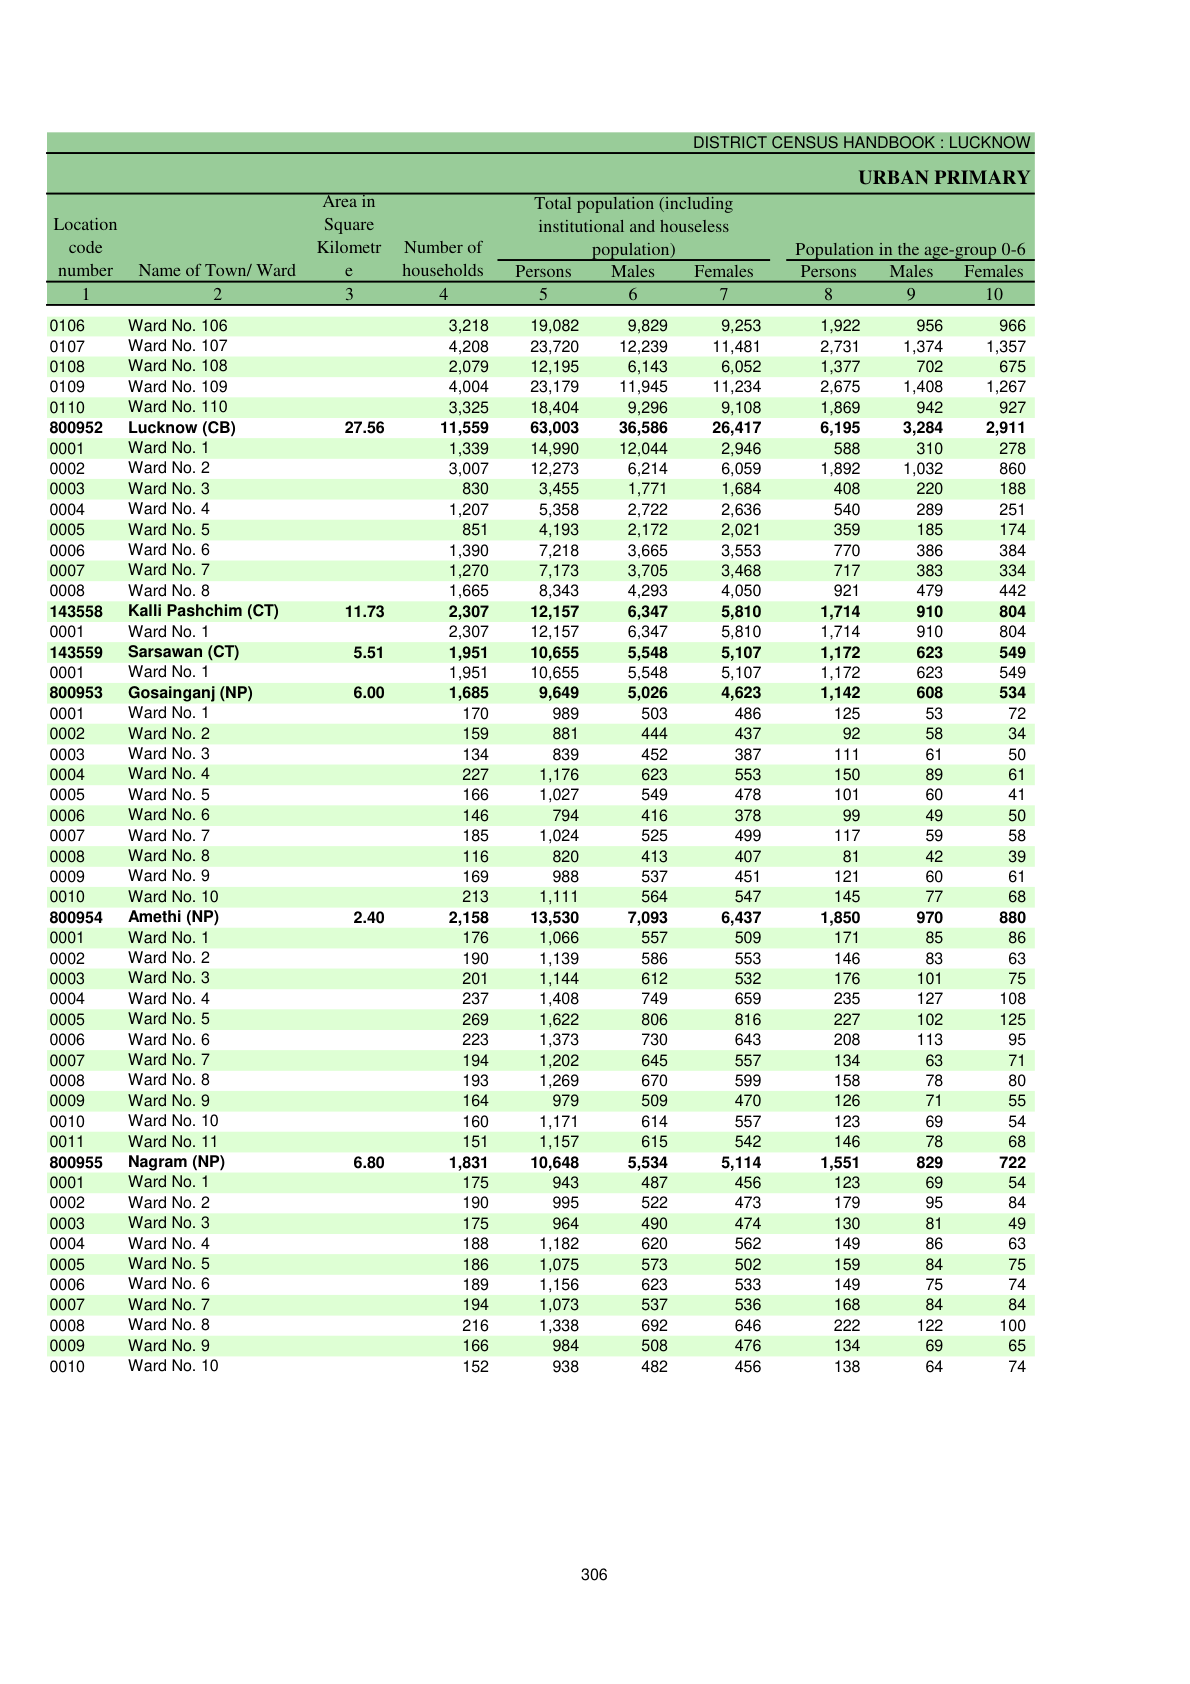


Existing PCA master CSV size: 11,706 bytes

Setup complete. No existing project data were modified.


In [ ]:
# ============================================================
# STEP 1: SET UP ENVIRONMENT AND INSPECT CENSUS HANDBOOK PAGE 325
# ============================================================

from pathlib import Path
import subprocess
import sys

# 2. Install PyMuPDF if it is not already installed
try:
    import fitz
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "PyMuPDF"]
    )
    import fitz

from IPython.display import display, Image

# 3. Define project paths
RAW_DIR = Path("/content/gdrive/MyDrive/Lucknow_Census_Raw")
PROCESSED_DIR = Path("/content/gdrive/MyDrive/lucknow_census_processed")

PDF_PATH = RAW_DIR / "DH_2011_0926_PART_B_DCHB_LUCKNOW.pdf"

MASTER_CSV = (
    PROCESSED_DIR /
    "lucknow_municipal_corporation_ward_pca_2011.csv"
)

# 4. Verify that the expected files exist
print("Raw directory exists:", RAW_DIR.exists())
print("Processed directory exists:", PROCESSED_DIR.exists())
print("Source PDF exists:", PDF_PATH.exists())
print("Existing Municipal Corporation CSV exists:", MASTER_CSV.exists())

if not PDF_PATH.exists():
    print("\nPDF files available in the raw directory:")
    if RAW_DIR.exists():
        for f in RAW_DIR.glob("*.pdf"):
            print(" -", f.name)
    raise FileNotFoundError(
        "The expected Census Handbook PDF was not found. "
        "Check the filename printed above."
    )

if not MASTER_CSV.exists():
    raise FileNotFoundError(
        "The existing Municipal Corporation master CSV was not found. "
        "We will preserve the completed work and locate the correct file."
    )

# 5. Open the PDF and inspect page 325
with fitz.open(PDF_PATH) as doc:
    print("\nTotal PDF pages:", len(doc))

    if len(doc) < 325:
        raise ValueError("The PDF contains fewer than 325 pages.")

    page = doc[324]  # PDF page 325; index starts at zero

    print("\n========== EXTRACTED TEXT: PDF PAGE 325 ==========\n")
    print(page.get_text("text"))

    # Render the source page for visual verification
    pix = page.get_pixmap(
        matrix=fitz.Matrix(2, 2),
        alpha=False
    )

    print("\n========== ORIGINAL PAGE IMAGE ==========\n")
    display(Image(data=pix.tobytes("png")))

# 6. Confirm the completed dataset remains available
print("\nExisting PCA master CSV size:",
      f"{MASTER_CSV.stat().st_size:,}", "bytes")

print("\nSetup complete. No existing project data were modified.")

In [ ]:
import pandas as pd
from pathlib import Path

# ============================================================
# STEP 2: EXTRACT LUCKNOW CANTONMENT BOARD WARD PCA
# Source: District Census Handbook, Part B, PDF page 325
# Census year: 2011
# Town code: 800952
# ============================================================

PROCESSED_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_CSV = (
    PROCESSED_DIR /
    "lucknow_cantonment_board_ward_pca_2011.csv"
)

# Values transcribed from the source table on PDF page 325.
# Column order follows the Census Handbook PCA table.
records = [
    # Ward, Households, Population, Male, Female,
    # Children 0-6, Male children, Female children
    ("0001", 1339, 14990, 12044, 2946,  588, 310, 278),
    ("0002", 3007, 12273,  6214, 6059, 1892, 1032, 860),
    ("0003",  830,  3455,  1771, 1684,  408, 220, 188),
    ("0004", 1207,  5358,  2722, 2636,  540, 289, 251),
    ("0005",  851,  4193,  2172, 2021,  359, 185, 174),
    ("0006", 1390,  7218,  3665, 3553,  770, 386, 384),
    ("0007", 1270,  7173,  3705, 3468,  717, 383, 334),
    ("0008", 1665,  8343,  4293, 4050,  921, 479, 442),
]

columns = [
    "ward_code",
    "households",
    "total_population",
    "male_population",
    "female_population",
    "children_0_6",
    "male_children_0_6",
    "female_children_0_6",
]

df_cb = pd.DataFrame(records, columns=columns)

# Geographic identity: ward codes are only unique within a town.
df_cb.insert(0, "town_code", "800952")
df_cb.insert(1, "town_name", "Lucknow Cantonment Board")
df_cb.insert(
    2,
    "geographic_id",
    df_cb["town_code"] + "_" + df_cb["ward_code"]
)

# Provenance metadata
df_cb["census_year"] = 2011
df_cb["source_pdf_page"] = 325
df_cb["source_town_code"] = "800952"

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

expected_totals = {
    "households": 11559,
    "total_population": 63003,
    "male_population": 36586,
    "female_population": 26417,
    "children_0_6": 6195,
    "male_children_0_6": 3284,
    "female_children_0_6": 2911,
}

print("Number of ward records:", len(df_cb))
print("Ward codes:", df_cb["ward_code"].tolist())
print("Duplicate ward codes:", df_cb["ward_code"].duplicated().sum())
print("Duplicate geographic IDs:", df_cb["geographic_id"].duplicated().sum())

print("\n--- Ward totals vs Census Handbook town totals ---")

validation = []
for field, expected in expected_totals.items():
    actual = int(df_cb[field].sum())
    validation.append({
        "field": field,
        "sum_of_wards": actual,
        "source_town_total": expected,
        "difference": actual - expected,
        "passed": actual == expected,
    })

validation_df = pd.DataFrame(validation)
print(validation_df.to_string(index=False))

# Arithmetic consistency checks
assert len(df_cb) == 8
assert df_cb["ward_code"].is_unique
assert df_cb["geographic_id"].is_unique

assert (
    df_cb["male_population"] + df_cb["female_population"]
    == df_cb["total_population"]
).all()

assert (
    df_cb["male_children_0_6"] + df_cb["female_children_0_6"]
    == df_cb["children_0_6"]
).all()

assert validation_df["passed"].all(), (
    "At least one ward aggregate does not match the source town total. "
    "Do not treat the extraction as validated."
)

# Save the separate dataset only after all checks pass
df_cb.to_csv(OUTPUT_CSV, index=False)

print("\nAll aggregate and arithmetic checks passed.")
print("Saved to:", OUTPUT_CSV)

print("\n--- Extracted ward data ---")
display(df_cb)

Number of ward records: 8
Ward codes: ['0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008']
Duplicate ward codes: 0
Duplicate geographic IDs: 0

--- Ward totals vs Census Handbook town totals ---
              field  sum_of_wards  source_town_total  difference  passed
         households         11559              11559           0    True
   total_population         63003              63003           0    True
    male_population         36586              36586           0    True
  female_population         26417              26417           0    True
       children_0_6          6195               6195           0    True
  male_children_0_6          3284               3284           0    True
female_children_0_6          2911               2911           0    True

All aggregate and arithmetic checks passed.
Saved to: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_cantonment_board_ward_pca_2011.csv

--- Extracted ward data ---


,town_code,town_name,geographic_id,ward_code,households,total_population,male_population,female_population,children_0_6,male_children_0_6,female_children_0_6,census_year,source_pdf_page,source_town_code
0,800952,Lucknow Cantonment Board,800952_0001,0001,1339,14990,12044,2946,588,310,278,2011,325,800952
1,800952,Lucknow Cantonment Board,800952_0002,0002,3007,12273,6214,6059,1892,1032,860,2011,325,800952
2,800952,Lucknow Cantonment Board,800952_0003,0003,830,3455,1771,1684,408,220,188,2011,325,800952
3,800952,Lucknow Cantonment Board,800952_0004,0004,1207,5358,2722,2636,540,289,251,2011,325,800952
4,800952,Lucknow Cantonment Board,800952_0005,0005,851,4193,2172,2021,359,185,174,2011,325,800952
5,800952,Lucknow Cantonment Board,800952_0006,0006,1390,7218,3665,3553,770,386,384,2011,325,800952
6,800952,Lucknow Cantonment Board,800952_0007,0007,1270,7173,3705,3468,717,383,334,2011,325,800952
7,800952,Lucknow Cantonment Board,800952_0008,0008,1665,8343,4293,4050,921,479,442,2011,325,800952


In [ ]:
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)

MUNICIPAL_CSV = (
    PROCESSED_DIR /
    "lucknow_municipal_corporation_ward_pca_2011.csv"
)

CANTONMENT_CSV = (
    PROCESSED_DIR /
    "lucknow_cantonment_board_ward_pca_2011.csv"
)

# Load both validated datasets
df_municipal = pd.read_csv(
    MUNICIPAL_CSV,
    dtype={"ward_code": str, "town_code": str}
)

df_cantonment = pd.read_csv(
    CANTONMENT_CSV,
    dtype={"ward_code": str, "town_code": str}
)

# Inspect schemas
print("=" * 65)
print("MUNICIPAL CORPORATION DATASET")
print("=" * 65)
print("Shape:", df_municipal.shape)
print("Columns:")
print(df_municipal.columns.tolist())
display(df_municipal.head(3))

print("\n" + "=" * 65)
print("CANTONMENT BOARD DATASET")
print("=" * 65)
print("Shape:", df_cantonment.shape)
print("Columns:")
print(df_cantonment.columns.tolist())
display(df_cantonment.head(3))

# Check whether the two datasets have compatible schemas
municipal_columns = set(df_municipal.columns)
cantonment_columns = set(df_cantonment.columns)

print("\n" + "=" * 65)
print("SCHEMA COMPARISON")
print("=" * 65)
print("Columns only in Municipal Corporation:",
      sorted(municipal_columns - cantonment_columns))
print("Columns only in Cantonment Board:",
      sorted(cantonment_columns - municipal_columns))
print("Columns shared by both:",
      sorted(municipal_columns & cantonment_columns))

MUNICIPAL CORPORATION DATASET
Shape: (110, 16)
Columns:
['town_code', 'ward_code', 'ward_name', 'row_y', 'households', 'population_total', 'population_male', 'population_female', 'age_0_6_total', 'age_0_6_male', 'age_0_6_female', 'geography_id', 'sex_sum', 'sex_check', 'age_sum', 'age_check']


,town_code,ward_code,ward_name,row_y,households,population_total,population_male,population_female,age_0_6_total,age_0_6_male,age_0_6_female,geography_id,sex_sum,sex_check,age_sum,age_check
0,800951,1,Ward No. 1,312.17,8570,43282,22531,20751,4733,2433,2300,800951_0001,43282.0,True,4733.0,True
1,800951,2,Ward No. 2,322.37,8251,41971,22194,19777,5149,2682,2467,800951_0002,41971.0,True,5149.0,True
2,800951,3,Ward No. 3,332.57,3350,17988,9166,8822,1868,937,931,800951_0003,17988.0,True,1868.0,True



CANTONMENT BOARD DATASET
Shape: (8, 14)
Columns:
['town_code', 'town_name', 'geographic_id', 'ward_code', 'households', 'total_population', 'male_population', 'female_population', 'children_0_6', 'male_children_0_6', 'female_children_0_6', 'census_year', 'source_pdf_page', 'source_town_code']


,town_code,town_name,geographic_id,ward_code,households,total_population,male_population,female_population,children_0_6,male_children_0_6,female_children_0_6,census_year,source_pdf_page,source_town_code
0,800952,Lucknow Cantonment Board,800952_0001,0001,1339,14990,12044,2946,588,310,278,2011,325,800952
1,800952,Lucknow Cantonment Board,800952_0002,0002,3007,12273,6214,6059,1892,1032,860,2011,325,800952
2,800952,Lucknow Cantonment Board,800952_0003,0003,830,3455,1771,1684,408,220,188,2011,325,800952



SCHEMA COMPARISON
Columns only in Municipal Corporation: ['age_0_6_female', 'age_0_6_male', 'age_0_6_total', 'age_check', 'age_sum', 'geography_id', 'population_female', 'population_male', 'population_total', 'row_y', 'sex_check', 'sex_sum', 'ward_name']
Columns only in Cantonment Board: ['census_year', 'children_0_6', 'female_children_0_6', 'female_population', 'geographic_id', 'male_children_0_6', 'male_population', 'source_pdf_page', 'source_town_code', 'total_population', 'town_name']
Columns shared by both: ['households', 'town_code', 'ward_code']


In [ ]:
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)

MUNICIPAL_CSV = (
    PROCESSED_DIR /
    "lucknow_municipal_corporation_ward_pca_2011.csv"
)

CANTONMENT_CSV = (
    PROCESSED_DIR /
    "lucknow_cantonment_board_ward_pca_2011.csv"
)

OUTPUT_CSV = (
    PROCESSED_DIR /
    "lucknow_urban_ward_pca_2011_combined.csv"
)

# ------------------------------------------------------------
# 1. Load source datasets, preserving ward-code formatting
# ------------------------------------------------------------

municipal = pd.read_csv(
    MUNICIPAL_CSV,
    dtype={"town_code": str, "ward_code": str}
)

cantonment = pd.read_csv(
    CANTONMENT_CSV,
    dtype={"town_code": str, "ward_code": str}
)

# ------------------------------------------------------------
# 2. Standardize Municipal Corporation fields
# ------------------------------------------------------------

mc = pd.DataFrame({
    "town_code": municipal["town_code"].str.strip(),
    "town_name": "Lucknow Municipal Corporation",
    "ward_code": municipal["ward_code"].str.strip().str.zfill(4),
    "households": municipal["households"],
    "total_population": municipal["population_total"],
    "male_population": municipal["population_male"],
    "female_population": municipal["population_female"],
    "children_0_6": municipal["age_0_6_total"],
    "male_children_0_6": municipal["age_0_6_male"],
    "female_children_0_6": municipal["age_0_6_female"],
    "census_year": 2011,
    "source_pdf_page": pd.NA,
    "source_row_y": municipal["row_y"],
    "source_dataset": "Municipal Corporation PCA master CSV"
})

# Retain the original extracted ward name separately
mc["source_ward_name"] = municipal["ward_name"]

# ------------------------------------------------------------
# 3. Standardize Cantonment Board fields
# ------------------------------------------------------------

cb = pd.DataFrame({
    "town_code": cantonment["town_code"].str.strip(),
    "town_name": cantonment["town_name"],
    "ward_code": cantonment["ward_code"].str.strip().str.zfill(4),
    "households": cantonment["households"],
    "total_population": cantonment["total_population"],
    "male_population": cantonment["male_population"],
    "female_population": cantonment["female_population"],
    "children_0_6": cantonment["children_0_6"],
    "male_children_0_6": cantonment["male_children_0_6"],
    "female_children_0_6": cantonment["female_children_0_6"],
    "census_year": cantonment["census_year"],
    "source_pdf_page": cantonment["source_pdf_page"],
    "source_row_y": pd.NA,
    "source_dataset": "Cantonment Board PCA extracted from PDF page 325"
})

cb["source_ward_name"] = (
    "Ward No. " + cb["ward_code"].str.lstrip("0")
)

# ------------------------------------------------------------
# 4. Create jurisdiction-aware geographic IDs
# ------------------------------------------------------------

for frame in (mc, cb):
    frame["geographic_id"] = (
        frame["town_code"] + "_" + frame["ward_code"]
    )

# ------------------------------------------------------------
# 5. Concatenate without dropping source columns
# ------------------------------------------------------------

combined = pd.concat(
    [mc, cb],
    ignore_index=True
)

column_order = [
    "geographic_id",
    "town_code",
    "town_name",
    "ward_code",
    "households",
    "total_population",
    "male_population",
    "female_population",
    "children_0_6",
    "male_children_0_6",
    "female_children_0_6",
    "census_year",
    "source_pdf_page",
    "source_row_y",
    "source_dataset",
    "source_ward_name"
]

combined = combined[column_order]

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

print("Combined shape:", combined.shape)
print("Unique geographic IDs:", combined["geographic_id"].nunique())
print("Duplicate geographic IDs:",
      combined["geographic_id"].duplicated().sum())

print("\nWard counts by jurisdiction:")
print(combined.groupby(["town_code", "town_name"]).size())

print("\nPopulation totals by jurisdiction:")
print(
    combined.groupby(["town_code", "town_name"])[
        ["households", "total_population", "male_population",
         "female_population", "children_0_6",
         "male_children_0_6", "female_children_0_6"]
    ].sum()
)

# Population arithmetic
assert (
    combined["male_population"] + combined["female_population"]
    == combined["total_population"]
).all()

assert (
    combined["male_children_0_6"] +
    combined["female_children_0_6"]
    == combined["children_0_6"]
).all()

# Coverage and identity checks
assert len(combined) == 118
assert combined["geographic_id"].is_unique
assert set(combined["town_code"]) == {"800951", "800952"}

# Confirm the two jurisdiction totals
expected_population = {"800951": 2817105, "800952": 63003}

for town_code, expected in expected_population.items():
    actual = int(
        combined.loc[
            combined["town_code"] == town_code,
            "total_population"
        ].sum()
    )
    assert actual == expected, (
        f"Population mismatch for town {town_code}: "
        f"{actual} vs {expected}"
    )

# Save only after all checks pass
combined.to_csv(OUTPUT_CSV, index=False)

print("\nAll validation checks passed.")
print("Combined population:", int(combined["total_population"].sum()))
print("Saved to:", OUTPUT_CSV)

display(combined.head(5))
display(combined.tail(8))

Combined shape: (118, 16)
Unique geographic IDs: 118
Duplicate geographic IDs: 0

Ward counts by jurisdiction:
town_code  town_name                    
800951     Lucknow Municipal Corporation    110
800952     Lucknow Cantonment Board           8
dtype: int64

Population totals by jurisdiction:
                                         households  total_population  \
town_code town_name                                                     
800951    Lucknow Municipal Corporation      538149           2817105   
800952    Lucknow Cantonment Board            11559             63003   

                                         male_population  female_population  \
town_code town_name                                                           
800951    Lucknow Municipal Corporation          1460970            1356135   
800952    Lucknow Cantonment Board                 36586              26417   

                                         children_0_6  male_children_0_6  \
town_code town_na

/tmp/ipykernel_1951/1299551970.py:99: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(


,geographic_id,town_code,town_name,ward_code,households,total_population,male_population,female_population,children_0_6,male_children_0_6,female_children_0_6,census_year,source_pdf_page,source_row_y,source_dataset,source_ward_name
0,800951_0001,800951,Lucknow Municipal Corporation,0001,8570,43282,22531,20751,4733,2433,2300,2011,<NA>,312.17,Municipal Corporation PCA master CSV,Ward No. 1
1,800951_0002,800951,Lucknow Municipal Corporation,0002,8251,41971,22194,19777,5149,2682,2467,2011,<NA>,322.37,Municipal Corporation PCA master CSV,Ward No. 2
2,800951_0003,800951,Lucknow Municipal Corporation,0003,3350,17988,9166,8822,1868,937,931,2011,<NA>,332.57,Municipal Corporation PCA master CSV,Ward No. 3
3,800951_0004,800951,Lucknow Municipal Corporation,0004,4012,22717,12009,10708,2451,1307,1144,2011,<NA>,342.77,Municipal Corporation PCA master CSV,Ward No. 4
4,800951_0005,800951,Lucknow Municipal Corporation,0005,4267,21960,11562,10398,2650,1382,1268,2011,<NA>,352.97,Municipal Corporation PCA master CSV,Ward No. 5


,geographic_id,town_code,town_name,ward_code,households,total_population,male_population,female_population,children_0_6,male_children_0_6,female_children_0_6,census_year,source_pdf_page,source_row_y,source_dataset,source_ward_name
110,800952_0001,800952,Lucknow Cantonment Board,0001,1339,14990,12044,2946,588,310,278,2011,325,NaN,Cantonment Board PCA extracted from PDF page 325,Ward No. 1
111,800952_0002,800952,Lucknow Cantonment Board,0002,3007,12273,6214,6059,1892,1032,860,2011,325,NaN,Cantonment Board PCA extracted from PDF page 325,Ward No. 2
112,800952_0003,800952,Lucknow Cantonment Board,0003,830,3455,1771,1684,408,220,188,2011,325,NaN,Cantonment Board PCA extracted from PDF page 325,Ward No. 3
113,800952_0004,800952,Lucknow Cantonment Board,0004,1207,5358,2722,2636,540,289,251,2011,325,NaN,Cantonment Board PCA extracted from PDF page 325,Ward No. 4
114,800952_0005,800952,Lucknow Cantonment Board,0005,851,4193,2172,2021,359,185,174,2011,325,NaN,Cantonment Board PCA extracted from PDF page 325,Ward No. 5
115,800952_0006,800952,Lucknow Cantonment Board,0006,1390,7218,3665,3553,770,386,384,2011,325,NaN,Cantonment Board PCA extracted from PDF page 325,Ward No. 6
116,800952_0007,800952,Lucknow Cantonment Board,0007,1270,7173,3705,3468,717,383,334,2011,325,NaN,Cantonment Board PCA extracted from PDF page 325,Ward No. 7
117,800952_0008,800952,Lucknow Cantonment Board,0008,1665,8343,4293,4050,921,479,442,2011,325,NaN,Cantonment Board PCA extracted from PDF page 325,Ward No. 8


In [ ]:
import pandas as pd
from pathlib import Path

combined_path = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_urban_ward_pca_2011_combined.csv"
)

df = pd.read_csv(
    combined_path,
    dtype={
        "geographic_id": str,
        "town_code": str,
        "ward_code": str
    }
)

print("File exists:", combined_path.exists())
print("Shape:", df.shape)
print("Unique geographic IDs:", df["geographic_id"].nunique())
print("Duplicate geographic IDs:", df["geographic_id"].duplicated().sum())

print("\nWard counts by jurisdiction:")
print(df.groupby(["town_code", "town_name"]).size())

print("\nMissing values:")
print(df.isna().sum().to_string())

assert df.shape[0] == 118
assert df["geographic_id"].nunique() == 118
assert df["geographic_id"].duplicated().sum() == 0

print("\nReload verification passed.")

File exists: True
Shape: (118, 16)
Unique geographic IDs: 118
Duplicate geographic IDs: 0

Ward counts by jurisdiction:
town_code  town_name                    
800951     Lucknow Municipal Corporation    110
800952     Lucknow Cantonment Board           8
dtype: int64

Missing values:
geographic_id            0
town_code                0
town_name                0
ward_code                0
households               0
total_population         0
male_population          0
female_population        0
children_0_6             0
male_children_0_6        0
female_children_0_6      0
census_year              0
source_pdf_page        110
source_row_y            13
source_dataset           0
source_ward_name         0

Reload verification passed.


In [ ]:
from pathlib import Path

RAW_DIR = Path(
    "/content/gdrive/MyDrive/Lucknow_Census_Raw"
)

print("=== Geographic files in the raw data directory ===\n")

extensions = {
    ".shp", ".shx", ".dbf", ".prj", ".cpg",
    ".gpkg", ".geojson", ".json", ".pbf",
    ".zip", ".kml", ".gml"
}

for path in sorted(RAW_DIR.rglob("*")):
    if path.is_file() and path.suffix.lower() in extensions:
        print(
            f"{path.relative_to(RAW_DIR)}"
            f"  |  {path.stat().st_size:,} bytes"
        )

=== Geographic files in the raw data directory ===

2011_Dist.dbf  |  54,678 bytes
2011_Dist.prj  |  145 bytes
2011_Dist.shp  |  10,220,732 bytes
2011_Dist.shx  |  5,228 bytes
DH_2011_0926-Lucknow.zip  |  890,376 bytes
central-zone-261017.osm.pbf  |  351,810,226 bytes


In [ ]:
from pathlib import Path
import subprocess
import sys

# Install GeoPandas only if required
try:
    import geopandas as gpd
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "geopandas"]
    )
    import geopandas as gpd

RAW_DIR = Path(
    "/content/gdrive/MyDrive/Lucknow_Census_Raw"
)

SHP_PATH = RAW_DIR / "2011_Dist.shp"

if not SHP_PATH.exists():
    raise FileNotFoundError(f"Shapefile not found: {SHP_PATH}")

# Load district boundaries
districts = gpd.read_file(SHP_PATH)

print("=== SHAPEFILE SUMMARY ===")
print("File:", SHP_PATH.name)
print("Number of features:", len(districts))
print("Number of columns:", len(districts.columns))
print("CRS:", districts.crs)
print("Geometry types:")
print(districts.geometry.geom_type.value_counts().to_dict())

print("\n=== ATTRIBUTE COLUMNS ===")
print(districts.columns.tolist())

print("\n=== FIRST FIVE RECORDS ===")
display(districts.drop(columns="geometry").head())

print("\n=== LUCKNOW-RELATED RECORDS ===")
text_columns = districts.select_dtypes(include=["object", "string"]).columns

mask = districts[text_columns].apply(
    lambda col: col.astype(str).str.contains(
        "Lucknow", case=False, na=False
    )
).any(axis=1)

lucknow_records = districts.loc[mask]

print("Matching records:", len(lucknow_records))
display(lucknow_records.drop(columns="geometry"))

print("\n=== GEOMETRY VALIDITY ===")
print("Missing geometries:", districts.geometry.isna().sum())
print("Empty geometries:", districts.geometry.is_empty.sum())
print("Invalid geometries:", (~districts.geometry.is_valid).sum())

=== SHAPEFILE SUMMARY ===
File: 2011_Dist.shp
Number of features: 641
Number of columns: 6
CRS: EPSG:4326
Geometry types:
{'Polygon': 567, 'MultiPolygon': 74}

=== ATTRIBUTE COLUMNS ===
['DISTRICT', 'ST_NM', 'ST_CEN_CD', 'DT_CEN_CD', 'censuscode', 'geometry']

=== FIRST FIVE RECORDS ===


,DISTRICT,ST_NM,ST_CEN_CD,DT_CEN_CD,censuscode
0,Adilabad,Andhra Pradesh,28,1,532
1,Agra,Uttar Pradesh,9,15,146
2,Ahmadabad,Gujarat,24,7,474
3,Ahmadnagar,Maharashtra,27,26,522
4,Aizawl,Mizoram,15,3,283



=== LUCKNOW-RELATED RECORDS ===
Matching records: 1


,DISTRICT,ST_NM,ST_CEN_CD,DT_CEN_CD,censuscode
344,Lucknow,Uttar Pradesh,9,26,157



=== GEOMETRY VALIDITY ===
Missing geometries: 0
Empty geometries: 0
Invalid geometries: 1


In [ ]:
import geopandas as gpd
from pathlib import Path

SHP_PATH = Path(
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/2011_Dist.shp"
)

districts = gpd.read_file(SHP_PATH)

# 1. Find every invalid geometry
invalid_mask = (
    districts.geometry.notna()
    & ~districts.geometry.is_valid
)

invalid_districts = districts.loc[
    invalid_mask,
    ["DISTRICT", "ST_NM", "ST_CEN_CD", "DT_CEN_CD", "censuscode"]
].copy()

print("=== INVALID GEOMETRIES ===")
print("Count:", len(invalid_districts))
display(invalid_districts)

# 2. Inspect Lucknow's district record
lucknow = districts[
    (districts["DISTRICT"].str.strip().str.lower() == "lucknow")
    & (districts["ST_NM"].str.strip().str.lower() == "uttar pradesh")
].copy()

print("\n=== LUCKNOW DISTRICT ===")
print("Matching records:", len(lucknow))

if len(lucknow) == 1:
    geom = lucknow.geometry.iloc[0]

    print("Geometry type:", geom.geom_type)
    print("Geometry valid:", geom.is_valid)
    print("Geometry empty:", geom.is_empty)
    print("Bounds (longitude/latitude):", geom.bounds)
    print("District CRS:", districts.crs)

    # Check whether Lucknow is the invalid feature
    print(
        "Lucknow appears in invalid list:",
        bool(invalid_mask.loc[lucknow.index].iloc[0])
    )
else:
    print("Could not uniquely identify Lucknow; inspect the matching records.")

# 3. Show the attributes of the invalid feature(s)
if len(invalid_districts):
    print("\n=== INVALID FEATURE DETAILS ===")
    display(districts.loc[invalid_mask].drop(columns="geometry"))

=== INVALID GEOMETRIES ===
Count: 1


,DISTRICT,ST_NM,ST_CEN_CD,DT_CEN_CD,censuscode
123,Cuddalore,Tamil Nadu,33,16,617



=== LUCKNOW DISTRICT ===
Matching records: 1
Geometry type: Polygon
Geometry valid: True
Geometry empty: False
Bounds (longitude/latitude): (80.56048840854083, 26.501500906903686, 81.2190026254151, 27.15897480066942)
District CRS: EPSG:4326
Lucknow appears in invalid list: False

=== INVALID FEATURE DETAILS ===


,DISTRICT,ST_NM,ST_CEN_CD,DT_CEN_CD,censuscode
123,Cuddalore,Tamil Nadu,33,16,617


In [ ]:

from pathlib import Path

RAW_DIR = Path("/content/gdrive/MyDrive/Lucknow_Census_Raw")
TARGET_NAME = "wards_lucknow.shp.zip"

matches = list(RAW_DIR.rglob(TARGET_NAME))

print("Search directory:", RAW_DIR)
print("Matching files found:", len(matches))

for path in matches:
    print("\nFile:", path)
    print("Size (MB):", round(path.stat().st_size / (1024 * 1024), 3))


Search directory: /content/gdrive/MyDrive/Lucknow_Census_Raw
Matching files found: 1

File: /content/gdrive/MyDrive/Lucknow_Census_Raw/wards_lucknow.shp.zip
Size (MB): 0.092


In [ ]:

from pathlib import Path
import zipfile

ZIP_PATH = Path(
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/wards_lucknow.shp.zip"
)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    files = z.infolist()

    print("Total entries in ZIP:", len(files))
    print("\nFiles inside the archive:\n")

    for item in files:
        print(f"{item.filename:<65} {item.file_size:>10,} bytes")

    extensions = {
        Path(item.filename).suffix.lower()
        for item in files
        if not item.is_dir()
    }

    print("\n=== Shapefile component check ===")
    for ext in [".shp", ".shx", ".dbf", ".prj", ".cpg"]:
        print(f"{ext}: {'Present' if ext in extensions else 'Not found'}")


Total entries in ZIP: 4

Files inside the archive:

wards_lucknow.dbf                                                     12,258 bytes
wards_lucknow.shx                                                        996 bytes
wards_lucknow.shp                                                    137,044 bytes
wards_lucknow.prj                                                        145 bytes

=== Shapefile component check ===
.shp: Present
.shx: Present
.dbf: Present
.prj: Present
.cpg: Not found


In [ ]:

from pathlib import Path
import zipfile
import geopandas as gpd

ZIP_PATH = Path(
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/wards_lucknow.shp.zip"
)

WORK_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/ward_boundaries_candidate"
)
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Extract the archive into a separate working directory
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(WORK_DIR)

print("Extracted files:")
for path in sorted(WORK_DIR.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(WORK_DIR))

# Locate and load the shapefile
SHP_PATH = WORK_DIR / "wards_lucknow.shp"

if not SHP_PATH.exists():
    candidates = list(WORK_DIR.rglob("wards_lucknow.shp"))
    if len(candidates) != 1:
        raise FileNotFoundError(
            f"Expected one wards_lucknow.shp, found {len(candidates)}"
        )
    SHP_PATH = candidates[0]

wards = gpd.read_file(SHP_PATH)

print("\n=== BASIC DATASET INSPECTION ===")
print("File:", SHP_PATH)
print("Shape (rows, columns):", wards.shape)
print("CRS:", wards.crs)
print("Geometry types:")
print(wards.geom_type.value_counts(dropna=False))

print("\n=== ATTRIBUTE COLUMNS ===")
print(wards.columns.tolist())

print("\n=== FIRST 10 RECORDS ===")
display(wards.head(10))

print("\n=== GEOMETRY VALIDATION ===")
print("Missing geometries:", wards.geometry.isna().sum())
print("Empty geometries:", wards.geometry.is_empty.sum())
print("Invalid geometries:", (~wards.geometry.is_valid).sum())
print("Duplicate complete records:", wards.drop(columns="geometry").duplicated().sum())


Extracted files:
 - wards_lucknow.dbf
 - wards_lucknow.prj
 - wards_lucknow.shp
 - wards_lucknow.shx

=== BASIC DATASET INSPECTION ===
File: /content/gdrive/MyDrive/lucknow_census_processed/ward_boundaries_candidate/wards_lucknow.shp
Shape (rows, columns): (112, 5)
CRS: EPSG:4326
Geometry types:
Polygon    112
Name: count, dtype: int64

=== ATTRIBUTE COLUMNS ===
['id', 'Zone', 'Ward Num', 'Ward Name', 'geometry']

=== FIRST 10 RECORDS ===


,id,Zone,Ward Num,Ward Name,geometry
0,1,5,4,Sarojni Nagar Part 1,"POLYGON ((80.8519 26.77589, 80.85158 26.77458,..."
1,2,5,15,Sarojni Nagar Part 2,"POLYGON ((80.86472 26.74491, 80.86467 26.74508..."
2,3,5,0,Airport,"POLYGON ((80.88118 26.77512, 80.89417 26.76837..."
3,4,5,2,Raja Bijli Pasi,"POLYGON ((80.88116 26.7752, 80.88645 26.78454,..."
4,5,5,21,Sharda Nagar,"POLYGON ((80.91646 26.76414, 80.9176 26.76641,..."
5,6,5,1,Ibrahimpur,"POLYGON ((80.94334 26.77725, 80.94611 26.77515..."
6,7,5,10,Kharika,"POLYGON ((80.94334 26.77725, 80.93974 26.791, ..."
7,8,5,88,Vidyavati 1st,"POLYGON ((80.90258 26.77752, 80.90504 26.78128..."
8,9,5,73,Vidyavati 2nd,"POLYGON ((80.88944 26.78314, 80.89066 26.78537..."
9,10,5,66,Hind Nagar,"POLYGON ((80.88871 26.78873, 80.89137 26.7936,..."



=== GEOMETRY VALIDATION ===
Missing geometries: 0
Empty geometries: 0
Invalid geometries: 0
Duplicate complete records: 0


In [ ]:

import pandas as pd

# Work on a copy; do not modify the original GeoDataFrame
ward_audit = wards[["id", "Zone", "Ward Num", "Ward Name"]].copy()

# Standardize field types for inspection only
ward_audit["Ward Num"] = pd.to_numeric(
    ward_audit["Ward Num"], errors="coerce"
)

ward_audit["Ward Name"] = (
    ward_audit["Ward Name"].astype("string").str.strip()
)

print("=== WARD NUMBER SUMMARY ===")
print("Total polygon records:", len(ward_audit))
print("Missing ward numbers:", ward_audit["Ward Num"].isna().sum())
print("Distinct ward numbers:", ward_audit["Ward Num"].nunique())
print("Minimum ward number:", ward_audit["Ward Num"].min())
print("Maximum ward number:", ward_audit["Ward Num"].max())

print("\n=== DUPLICATE WARD NUMBERS ===")
duplicate_numbers = ward_audit[
    ward_audit["Ward Num"].duplicated(keep=False)
].sort_values("Ward Num")

if duplicate_numbers.empty:
    print("No duplicate ward numbers.")
else:
    display(duplicate_numbers)

print("\n=== MISSING NUMBERS IN THE OBSERVED RANGE ===")
valid_numbers = set(
    ward_audit["Ward Num"].dropna().astype(int).tolist()
)

if valid_numbers:
    low = min(valid_numbers)
    high = max(valid_numbers)
    missing_numbers = sorted(set(range(low, high + 1)) - valid_numbers)
    print("Missing ward numbers:", missing_numbers)
else:
    print("No valid ward numbers to inspect.")

print("\n=== WARD ZERO ===")
display(ward_audit[ward_audit["Ward Num"] == 0])

print("\n=== RECORDS BY ZONE ===")
print(
    ward_audit.groupby("Zone", dropna=False)
    .agg(
        polygon_records=("id", "size"),
        distinct_ward_numbers=("Ward Num", "nunique"),
        distinct_ward_names=("Ward Name", "nunique")
    )
    .sort_index()
)

print("\n=== ALL WARD NUMBERS AND NAMES ===")
display(
    ward_audit.sort_values(["Ward Num", "Ward Name"])
    .reset_index(drop=True)
)


=== WARD NUMBER SUMMARY ===
Total polygon records: 112
Missing ward numbers: 0
Distinct ward numbers: 111
Minimum ward number: 0
Maximum ward number: 110

=== DUPLICATE WARD NUMBERS ===


,id,Zone,Ward Num,Ward Name
2,3,5,0,Airport
111,112,0,0,Cantonment



=== MISSING NUMBERS IN THE OBSERVED RANGE ===
Missing ward numbers: []

=== WARD ZERO ===


,id,Zone,Ward Num,Ward Name
2,3,5,0,Airport
111,112,0,0,Cantonment



=== RECORDS BY ZONE ===
      polygon_records  distinct_ward_numbers  distinct_ward_names
Zone                                                             
0                   1                      1                    1
1                  16                     16                   16
2                  20                     20                   20
3                  21                     21                   21
4                  17                     17                   17
5                  19                     19                   19
6                  18                     18                   18

=== ALL WARD NUMBERS AND NAMES ===


,id,Zone,Ward Num,Ward Name
0,3,5,0,Airport
1,112,0,0,Cantonment
2,6,5,1,Ibrahimpur
3,4,5,2,Raja Bijli Pasi
4,48,2,3,Tilak Nagar
...,...,...,...,...
107,49,2,106,Kundri Rakab Ganj
108,60,6,107,Maulana Kalbey Abid 1st
109,56,6,108,Maulana Kalbey Abid 2nd
110,66,6,109,Mallahi Tola 2nd


In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

CENSUS_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_urban_ward_pca_2011_combined.csv"
)

census = pd.read_csv(CENSUS_PATH, dtype={"town_code": str, "ward_code": str})

# Select only the 110 Census Municipal Corporation records
lmc_census = census[
    census["town_code"].str.strip() == "800951"
].copy()

# Prepare boundary attributes, excluding special polygons from the
# initial numbered-ward comparison (do not delete them from `wards`)
boundary_audit = wards[
    ["id", "Zone", "Ward Num", "Ward Name"]
].copy()

boundary_audit["Ward Num"] = pd.to_numeric(
    boundary_audit["Ward Num"], errors="coerce"
)

lmc_boundaries = boundary_audit[
    boundary_audit["Ward Num"].between(1, 110)
].copy()

print("=== RECORD COUNTS ===")
print("Census LMC records:", len(lmc_census))
print("Boundary records numbered 1–110:", len(lmc_boundaries))
print("Unique Census ward codes:", lmc_census["ward_code"].nunique())
print("Unique boundary ward numbers:", lmc_boundaries["Ward Num"].nunique())

print("\n=== CENSUS COLUMN NAMES ===")
print(lmc_census.columns.tolist())

print("\n=== CENSUS WARD NAMES, IF AVAILABLE ===")
if "source_ward_name" in lmc_census.columns:
    display(
        lmc_census[["geographic_id", "ward_code", "source_ward_name"]]
        .sort_values("ward_code")
        .head(20)
    )
else:
    print("No source_ward_name column found.")

print("\n=== BOUNDARY WARD NAMES ===")
display(
    lmc_boundaries[["Ward Num", "Ward Name", "Zone"]]
    .sort_values("Ward Num")
    .head(20)
)


=== RECORD COUNTS ===
Census LMC records: 110
Boundary records numbered 1–110: 110
Unique Census ward codes: 110
Unique boundary ward numbers: 110

=== CENSUS COLUMN NAMES ===
['geographic_id', 'town_code', 'town_name', 'ward_code', 'households', 'total_population', 'male_population', 'female_population', 'children_0_6', 'male_children_0_6', 'female_children_0_6', 'census_year', 'source_pdf_page', 'source_row_y', 'source_dataset', 'source_ward_name']

=== CENSUS WARD NAMES, IF AVAILABLE ===


,geographic_id,ward_code,source_ward_name
0,800951_0001,0001,Ward No. 1
1,800951_0002,0002,Ward No. 2
2,800951_0003,0003,Ward No. 3
3,800951_0004,0004,Ward No. 4
4,800951_0005,0005,Ward No. 5
5,800951_0006,0006,Ward No. 6
6,800951_0007,0007,Ward No. 7
7,800951_0008,0008,Ward No. 8
8,800951_0009,0009,Ward No. 9
9,800951_0010,0010,Ward No. 10



=== BOUNDARY WARD NAMES ===


,Ward Num,Ward Name,Zone
5,1,Ibrahimpur,5
3,2,Raja Bijli Pasi,5
46,3,Tilak Nagar,2
0,4,Sarojni Nagar Part 1,5
25,5,Ambedkar Nagar 2nd,2
109,6,Shaheed Bhagat Singh,4
40,7,Malviya Nagar,2
100,8,Lal Bahadur Shastri 1st,4
23,9,Kanhaiya Madhopur,6
6,10,Kharika,5


=== GEOGRAPHIC COVERAGE ===
Overall bounds (longitude, latitude): [80.83111634 26.74407895 81.06093189 26.93436358]
Numbered ward polygons: 110
Special polygons: 2

=== SPECIAL FEATURES ===


,id,Zone,Ward Num,Ward Name
2,3,5,0,Airport
111,112,0,0,Cantonment



=== AREA SUMMARY (km²) ===
Numbered wards:


,area_km2
count,110.000000
mean,2.342911
std,3.162542
min,0.169229
25%,0.687422
50%,1.126618
75%,2.396155
max,17.516888


Special features:


,Ward Name,area_km2
2,Airport,4.519813
111,Cantonment,20.668726


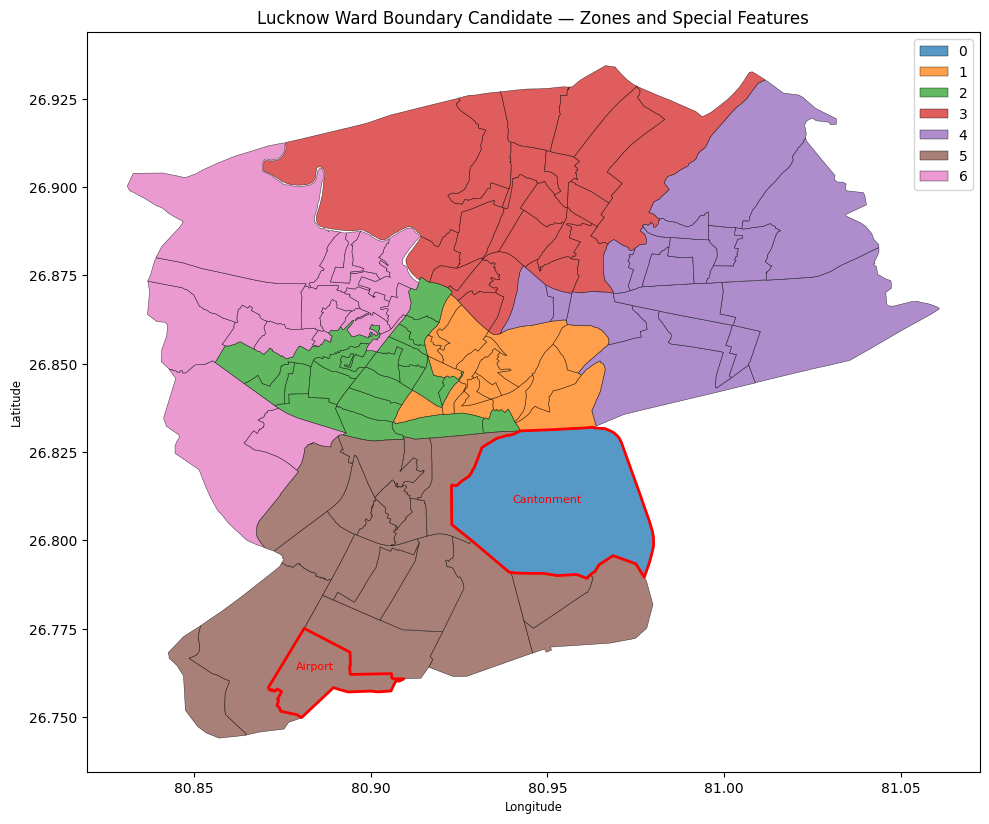

In [ ]:

import geopandas as gpd
import matplotlib.pyplot as plt

# Keep the original wards GeoDataFrame unchanged
numbered_wards = wards[
    wards["Ward Num"].between(1, 110)
].copy()

special_features = wards[
    wards["Ward Num"] == 0
].copy()

# Project to UTM Zone 44N for area calculations in metres
wards_projected = wards.to_crs("EPSG:32644")
numbered_projected = wards_projected[
    wards_projected["Ward Num"].between(1, 110)
].copy()

special_projected = wards_projected[
    wards_projected["Ward Num"] == 0
].copy()

print("=== GEOGRAPHIC COVERAGE ===")
print("Overall bounds (longitude, latitude):", wards.total_bounds)
print("Numbered ward polygons:", len(numbered_wards))
print("Special polygons:", len(special_features))

print("\n=== SPECIAL FEATURES ===")
display(
    special_features[["id", "Zone", "Ward Num", "Ward Name"]]
)

print("\n=== AREA SUMMARY (km²) ===")
numbered_projected["area_km2"] = (
    numbered_projected.geometry.area / 1_000_000
)

special_projected["area_km2"] = (
    special_projected.geometry.area / 1_000_000
)

print("Numbered wards:")
display(
    numbered_projected["area_km2"].describe().to_frame()
)

print("Special features:")
display(
    special_projected[["Ward Name", "area_km2"]]
)

# Plot the complete layer, distinguishing the zones
fig, ax = plt.subplots(figsize=(10, 10))

wards.plot(
    ax=ax,
    column="Zone",
    categorical=True,
    legend=True,
    edgecolor="black",
    linewidth=0.35,
    alpha=0.75
)

# Outline the special polygons so they stand out
special_features.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

for _, row in special_features.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(
        str(row["Ward Name"]),
        (point.x, point.y),
        fontsize=8,
        color="red",
        ha="center"
    )

ax.set_title("Lucknow Ward Boundary Candidate — Zones and Special Features")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


In [ ]:

import geopandas as gpd
import pandas as pd

# Project all geometries to metres before calculating intersections
projected = wards.to_crs("EPSG:32644").copy()

numbered = projected[
    projected["Ward Num"].between(1, 110)
].copy()

special = projected[
    projected["Ward Num"] == 0
].copy()

print("=== PAIRWISE OVERLAP CHECK ===")

for _, special_row in special.iterrows():
    special_geom = special_row.geometry
    special_name = special_row["Ward Name"]

    intersections = numbered[
        numbered.geometry.intersects(special_geom)
    ].copy()

    intersections["intersection_km2"] = intersections.geometry.apply(
        lambda geom: geom.intersection(special_geom).area / 1_000_000
    )

    intersections = intersections[
        intersections["intersection_km2"] > 1e-6
    ].sort_values("intersection_km2", ascending=False)

    print(f"\nSpecial feature: {special_name}")
    print("Numbered wards with positive-area overlap:", len(intersections))

    if not intersections.empty:
        display(
            intersections[
                ["Ward Num", "Ward Name", "intersection_km2"]
            ].head(15)
        )
    else:
        print("No positive-area overlaps found.")

# Also test overlap between the two special polygons
special_rows = list(special.iterrows())

if len(special_rows) == 2:
    name_a = special_rows[0][1]["Ward Name"]
    geom_a = special_rows[0][1].geometry

    name_b = special_rows[1][1]["Ward Name"]
    geom_b = special_rows[1][1].geometry

    overlap_km2 = geom_a.intersection(geom_b).area / 1_000_000

    print(f"\nOverlap between {name_a} and {name_b}: {overlap_km2:.6f} km²")


=== PAIRWISE OVERLAP CHECK ===

Special feature: Airport
Numbered wards with positive-area overlap: 2


,Ward Num,Ward Name,intersection_km2
1,15,Sarojni Nagar Part 2,0.022639
3,2,Raja Bijli Pasi,0.003963



Special feature: Cantonment
Numbered wards with positive-area overlap: 5


,Ward Num,Ward Name,intersection_km2
15,20,Guru Govind Singh Ward,0.018087
28,57,Vikramaditya,0.004766
5,1,Ibrahimpur,0.004428
4,21,Sharda Nagar,0.001575
6,10,Kharika,0.000718



Overlap between Airport and Cantonment: 0.000000 km²


In [ ]:

import pandas as pd

# Use the projected geometries from the previous cell
overlap_rows = []

for _, special_row in special.iterrows():
    special_geom = special_row.geometry
    special_name = special_row["Ward Name"]
    special_area = special_geom.area

    for _, ward_row in numbered.iterrows():
        ward_geom = ward_row.geometry

        if not ward_geom.intersects(special_geom):
            continue

        intersection_area = ward_geom.intersection(special_geom).area

        if intersection_area > 1:  # Ignore intersections of 1 m² or less
            overlap_rows.append({
                "special_feature": special_name,
                "ward_num": int(ward_row["Ward Num"]),
                "ward_name": ward_row["Ward Name"],
                "overlap_km2": intersection_area / 1_000_000,
                "special_area_pct": (
                    100 * intersection_area / special_area
                    if special_area else None
                ),
                "ward_area_km2": ward_geom.area / 1_000_000,
                "ward_area_pct": (
                    100 * intersection_area / ward_geom.area
                    if ward_geom.area else None
                )
            })

overlap_report = pd.DataFrame(overlap_rows)

print("=== OVERLAP PERCENTAGES ===")
if overlap_report.empty:
    print("No overlaps greater than 1 m² found.")
else:
    overlap_report = overlap_report.sort_values(
        ["special_feature", "overlap_km2"],
        ascending=[True, False]
    )

    display(
        overlap_report.round({
            "overlap_km2": 6,
            "special_area_pct": 4,
            "ward_area_km2": 4,
            "ward_area_pct": 4
        })
    )


=== OVERLAP PERCENTAGES ===


,special_feature,ward_num,ward_name,overlap_km2,special_area_pct,ward_area_km2,ward_area_pct
0,Airport,15,Sarojni Nagar Part 2,0.022639,0.5009,10.6225,0.2131
1,Airport,2,Raja Bijli Pasi,0.003963,0.0877,5.2841,0.0750
5,Cantonment,20,Guru Govind Singh Ward,0.018087,0.0875,3.3898,0.5336
6,Cantonment,57,Vikramaditya,0.004766,0.0231,2.6254,0.1815
3,Cantonment,1,Ibrahimpur,0.004428,0.0214,5.9462,0.0745
2,Cantonment,21,Sharda Nagar,0.001575,0.0076,7.5047,0.0210
4,Cantonment,10,Kharika,0.000718,0.0035,2.4060,0.0298


In [ ]:

from pathlib import Path

WORK_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "ward_boundaries_candidate"
)

print("=== LOCAL FILE METADATA ===")

for filename in [
    "wards_lucknow.shp",
    "wards_lucknow.shx",
    "wards_lucknow.dbf",
    "wards_lucknow.prj"
]:
    path = WORK_DIR / filename

    if path.exists():
        print(
            f"{filename}: "
            f"{path.stat().st_size:,} bytes"
        )
    else:
        print(f"{filename}: NOT FOUND")

print("\n=== CRS DEFINITION (.prj) ===")

prj_path = WORK_DIR / "wards_lucknow.prj"

if prj_path.exists():
    print(prj_path.read_text(errors="replace"))
else:
    print("Projection file not found.")


=== LOCAL FILE METADATA ===
wards_lucknow.shp: 137,044 bytes
wards_lucknow.shx: 996 bytes
wards_lucknow.dbf: 12,258 bytes
wards_lucknow.prj: 145 bytes

=== CRS DEFINITION (.prj) ===
GEOGCS["GCS_WGS_1984",DATUM["D_WGS_1984",SPHEROID["WGS_1984",6378137.0,298.257223563]],PRIMEM["Greenwich",0.0],UNIT["Degree",0.0174532925199433]]


In [ ]:
import pandas as pd
from pathlib import Path
import geopandas as gpd

WORK_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "ward_boundaries_candidate"
)

SHP_PATH = WORK_DIR / "wards_lucknow.shp"

OUTPUT_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_map_boundaries_working.gpkg"
)

wards = gpd.read_file(SHP_PATH)

# Select the 110 numbered wards
lmc_map = wards[
    wards["Ward Num"].between(1, 110)
].copy()

# Select the single Cantonment feature
cantonment_map = wards[
    wards["Ward Name"].str.strip().str.lower() == "cantonment"
].copy()

if len(lmc_map) != 110:
    raise ValueError(f"Expected 110 numbered wards, found {len(lmc_map)}")

if len(cantonment_map) != 1:
    raise ValueError(
        f"Expected one Cantonment polygon, found {len(cantonment_map)}"
    )

# Standardize the working map layer
lmc_map["map_unit_id"] = lmc_map["Ward Num"].apply(
    lambda n: f"LMC_{int(n):03d}"
)
lmc_map["map_unit_type"] = "LMC_WARD"
lmc_map["map_unit_name"] = lmc_map["Ward Name"].astype(str)

cantonment_map["map_unit_id"] = "CANTONMENT"
cantonment_map["map_unit_type"] = "CANTONMENT_AGGREGATE"
cantonment_map["map_unit_name"] = "Lucknow Cantonment"

map_columns = [
    "map_unit_id",
    "map_unit_type",
    "map_unit_name",
    "Ward Num",
    "Ward Name",
    "Zone",
    "geometry"
]

map_boundaries = gpd.GeoDataFrame(
    pd.concat(
        [
            lmc_map[map_columns],
            cantonment_map[map_columns]
        ],
        ignore_index=True
    ),
    geometry="geometry",
    crs=wards.crs
)

# Save as a new file; the source shapefile remains unchanged
if OUTPUT_PATH.exists():
    OUTPUT_PATH.unlink()

map_boundaries.to_file(
    OUTPUT_PATH,
    layer="map_boundaries",
    driver="GPKG"
)

print("Saved:", OUTPUT_PATH)
print("Map units:", len(map_boundaries))
print("\nUnits by type:")
print(map_boundaries["map_unit_type"].value_counts())

print("\nFirst five records:")
display(map_boundaries.head())


Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_map_boundaries_working.gpkg
Map units: 111

Units by type:
map_unit_type
LMC_WARD                110
CANTONMENT_AGGREGATE      1
Name: count, dtype: int64

First five records:


,map_unit_id,map_unit_type,map_unit_name,Ward Num,Ward Name,Zone,geometry
0,LMC_004,LMC_WARD,Sarojni Nagar Part 1,4,Sarojni Nagar Part 1,5,"POLYGON ((80.8519 26.77589, 80.85158 26.77458,..."
1,LMC_015,LMC_WARD,Sarojni Nagar Part 2,15,Sarojni Nagar Part 2,5,"POLYGON ((80.86472 26.74491, 80.86467 26.74508..."
2,LMC_002,LMC_WARD,Raja Bijli Pasi,2,Raja Bijli Pasi,5,"POLYGON ((80.88116 26.7752, 80.88645 26.78454,..."
3,LMC_021,LMC_WARD,Sharda Nagar,21,Sharda Nagar,5,"POLYGON ((80.91646 26.76414, 80.9176 26.76641,..."
4,LMC_001,LMC_WARD,Ibrahimpur,1,Ibrahimpur,5,"POLYGON ((80.94334 26.77725, 80.94611 26.77515..."


In [ ]:

import pandas as pd
from pathlib import Path

CENSUS_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_urban_ward_pca_2011_combined.csv"
)

census = pd.read_csv(
    CENSUS_PATH,
    dtype={"town_code": str, "ward_code": str}
)

# Additive demographic fields
sum_cols = [
    "households",
    "total_population",
    "male_population",
    "female_population",
    "children_0_6",
    "male_children_0_6",
    "female_children_0_6"
]

# Normalize identifiers
census["town_code"] = census["town_code"].str.strip()
census["ward_code"] = census["ward_code"].str.strip().str.zfill(4)

# Separate the two jurisdictions
lmc = census[census["town_code"] == "800951"].copy()
cant = census[census["town_code"] == "800952"].copy()

# Validate record counts and identifiers before aggregation
assert len(lmc) == 110, f"Expected 110 LMC records, found {len(lmc)}"
assert lmc["ward_code"].nunique() == 110, "Duplicate LMC ward codes found"

assert len(cant) == 8, f"Expected 8 Cantonment records, found {len(cant)}"
assert cant["ward_code"].nunique() == 8, "Duplicate Cantonment ward codes found"

# Convert additive fields to numeric and fail if any are missing
for col in sum_cols:
    lmc[col] = pd.to_numeric(lmc[col], errors="raise")
    cant[col] = pd.to_numeric(cant[col], errors="raise")

    assert lmc[col].notna().all(), f"Missing values in LMC {col}"
    assert cant[col].notna().all(), f"Missing values in Cantonment {col}"

# LMC: retain each Census ward as one map-unit record
lmc_demo = lmc[["ward_code"] + sum_cols].copy()
lmc_demo["map_unit_id"] = lmc_demo["ward_code"].apply(
    lambda code: f"LMC_{int(code):03d}"
)
lmc_demo["map_unit_type"] = "LMC_WARD"
lmc_demo["source_census_records"] = 1

# Cantonment: aggregate the eight Census ward records into one
cant_totals = cant[sum_cols].sum()

cant_demo = pd.DataFrame([{
    **cant_totals.to_dict(),
    "map_unit_id": "CANTONMENT",
    "map_unit_type": "CANTONMENT_AGGREGATE",
    "source_census_records": len(cant)
}])

# Combine into a 111-row map-ready demographic table
map_demographics = pd.concat(
    [
        lmc_demo[
            sum_cols + [
                "map_unit_id", "map_unit_type", "source_census_records"
            ]
        ],
        cant_demo[
            sum_cols + [
                "map_unit_id", "map_unit_type", "source_census_records"
            ]
        ]
    ],
    ignore_index=True
)

# Validate aggregate and combined totals
expected_cant = {
    "households": 11559,
    "total_population": 63003,
    "male_population": 36586,
    "female_population": 26417,
    "children_0_6": 6195,
    "male_children_0_6": 3284,
    "female_children_0_6": 2911
}

print("=== CANTONMENT AGGREGATE VALIDATION ===")
for col, expected in expected_cant.items():
    actual = int(cant_totals[col])
    print(f"{col}: {actual:,} | Expected: {expected:,} | Match: {actual == expected}")
    assert actual == expected, f"Cantonment total mismatch for {col}"

print("\n=== MAP DEMOGRAPHICS SUMMARY ===")
print("Map-unit records:", len(map_demographics))
print("Unique map-unit IDs:", map_demographics["map_unit_id"].nunique())
print("\nRecords by type:")
print(map_demographics["map_unit_type"].value_counts())

print("\n=== COMBINED DEMOGRAPHIC TOTALS ===")
display(
    map_demographics.groupby("map_unit_type")[sum_cols].sum()
)

print("\n=== ARITHMETIC VALIDATION ===")
assert (
    map_demographics["male_population"]
    + map_demographics["female_population"]
    == map_demographics["total_population"]
).all(), "Male/female population totals do not match"

assert (
    map_demographics["male_children_0_6"]
    + map_demographics["female_children_0_6"]
    == map_demographics["children_0_6"]
).all(), "Child population totals do not match"

assert map_demographics["map_unit_id"].is_unique

print("All population arithmetic checks passed.")
print("All map-unit IDs are unique.")


=== CANTONMENT AGGREGATE VALIDATION ===
households: 11,559 | Expected: 11,559 | Match: True
total_population: 63,003 | Expected: 63,003 | Match: True
male_population: 36,586 | Expected: 36,586 | Match: True
female_population: 26,417 | Expected: 26,417 | Match: True
children_0_6: 6,195 | Expected: 6,195 | Match: True
male_children_0_6: 3,284 | Expected: 3,284 | Match: True
female_children_0_6: 2,911 | Expected: 2,911 | Match: True

=== MAP DEMOGRAPHICS SUMMARY ===
Map-unit records: 111
Unique map-unit IDs: 111

Records by type:
map_unit_type
LMC_WARD                110
CANTONMENT_AGGREGATE      1
Name: count, dtype: int64

=== COMBINED DEMOGRAPHIC TOTALS ===


,households,total_population,male_population,female_population,children_0_6,male_children_0_6,female_children_0_6
map_unit_type,,,,,,,
CANTONMENT_AGGREGATE,11559,63003,36586,26417,6195,3284,2911
LMC_WARD,538149,2817105,1460970,1356135,293697,154226,139471



=== ARITHMETIC VALIDATION ===
All population arithmetic checks passed.
All map-unit IDs are unique.


In [ ]:

from pathlib import Path
import geopandas as gpd
import pandas as pd

BOUNDARY_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_map_boundaries_working.gpkg"
)

OUTPUT_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_map_boundaries_with_demographics.gpkg"
)

# Reload the saved map layer so the join uses the actual saved file
map_boundaries = gpd.read_file(
    BOUNDARY_PATH,
    layer="map_boundaries"
)

# Ensure identifiers are unique before joining
assert map_boundaries["map_unit_id"].is_unique
assert map_demographics["map_unit_id"].is_unique

assert len(map_boundaries) == 111
assert len(map_demographics) == 111

# Avoid duplicating map_unit_type, which already exists in the boundary layer
demo_for_join = map_demographics.drop(columns=["map_unit_type"])

# Perform a validated one-to-one join
joined = map_boundaries.merge(
    demo_for_join,
    on="map_unit_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("=== JOIN VALIDATION ===")
print("Boundary records:", len(map_boundaries))
print("Demographic records:", len(map_demographics))
print("Joined records:", len(joined))
print("Unique joined IDs:", joined["map_unit_id"].nunique())

print("\nJoin status:")
print(joined["_merge"].value_counts())

# Stop if any geometry lacks a demographic match
unmatched = joined[joined["_merge"] != "both"]

if not unmatched.empty:
    display(unmatched[["map_unit_id", "map_unit_name", "_merge"]])
    raise ValueError("Some map units did not receive demographic records.")

# Verify demographic completeness
sum_cols = [
    "households",
    "total_population",
    "male_population",
    "female_population",
    "children_0_6",
    "male_children_0_6",
    "female_children_0_6"
]

for col in sum_cols:
    assert joined[col].notna().all(), f"Missing demographic values in {col}"

# Remove the merge indicator after validation
joined = joined.drop(columns=["_merge"])

# Check key aggregate totals
expected_totals = {
    "households": 549708,
    "total_population": 2880108,
    "male_population": 1497556,
    "female_population": 1382552,
    "children_0_6": 299892,
    "male_children_0_6": 157510,
    "female_children_0_6": 142382
}

print("\n=== TOTAL PRESERVATION CHECK ===")
for col, expected in expected_totals.items():
    actual = int(joined[col].sum())
    print(
        f"{col}: {actual:,} | Expected: {expected:,} "
        f"| Match: {actual == expected}"
    )
    assert actual == expected, f"Total mismatch for {col}"

# Save the joined layer as a new file
if OUTPUT_PATH.exists():
    OUTPUT_PATH.unlink()

joined = gpd.GeoDataFrame(
    joined,
    geometry="geometry",
    crs=map_boundaries.crs
)

joined.to_file(
    OUTPUT_PATH,
    layer="ward_demographics",
    driver="GPKG"
)

print("\n=== SAVED OUTPUT ===")
print(OUTPUT_PATH)
print("Final shape:", joined.shape)
print("CRS:", joined.crs)
print("\nMap units by type:")
print(joined["map_unit_type"].value_counts())

print("\nSample records:")
display(
    joined[
        [
            "map_unit_id",
            "map_unit_name",
            "map_unit_type",
            "households",
            "total_population",
            "children_0_6"
        ]
    ].head()
)


=== JOIN VALIDATION ===
Boundary records: 111
Demographic records: 111
Joined records: 111
Unique joined IDs: 111

Join status:
_merge
both          111
left_only       0
right_only      0
Name: count, dtype: int64

=== TOTAL PRESERVATION CHECK ===
households: 549,708 | Expected: 549,708 | Match: True
total_population: 2,880,108 | Expected: 2,880,108 | Match: True
male_population: 1,497,556 | Expected: 1,497,556 | Match: True
female_population: 1,382,552 | Expected: 1,382,552 | Match: True
children_0_6: 299,892 | Expected: 299,892 | Match: True
male_children_0_6: 157,510 | Expected: 157,510 | Match: True
female_children_0_6: 142,382 | Expected: 142,382 | Match: True

=== SAVED OUTPUT ===
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_map_boundaries_with_demographics.gpkg
Final shape: (111, 15)
CRS: EPSG:4326

Map units by type:
map_unit_type
LMC_WARD                110
CANTONMENT_AGGREGATE      1
Name: count, dtype: int64

Sample records:


,map_unit_id,map_unit_name,map_unit_type,households,total_population,children_0_6
0,LMC_004,Sarojni Nagar Part 1,LMC_WARD,4012,22717,2451
1,LMC_015,Sarojni Nagar Part 2,LMC_WARD,8601,46057,5088
2,LMC_002,Raja Bijli Pasi,LMC_WARD,8251,41971,5149
3,LMC_021,Sharda Nagar,LMC_WARD,14270,68993,6856
4,LMC_001,Ibrahimpur,LMC_WARD,8570,43282,4733


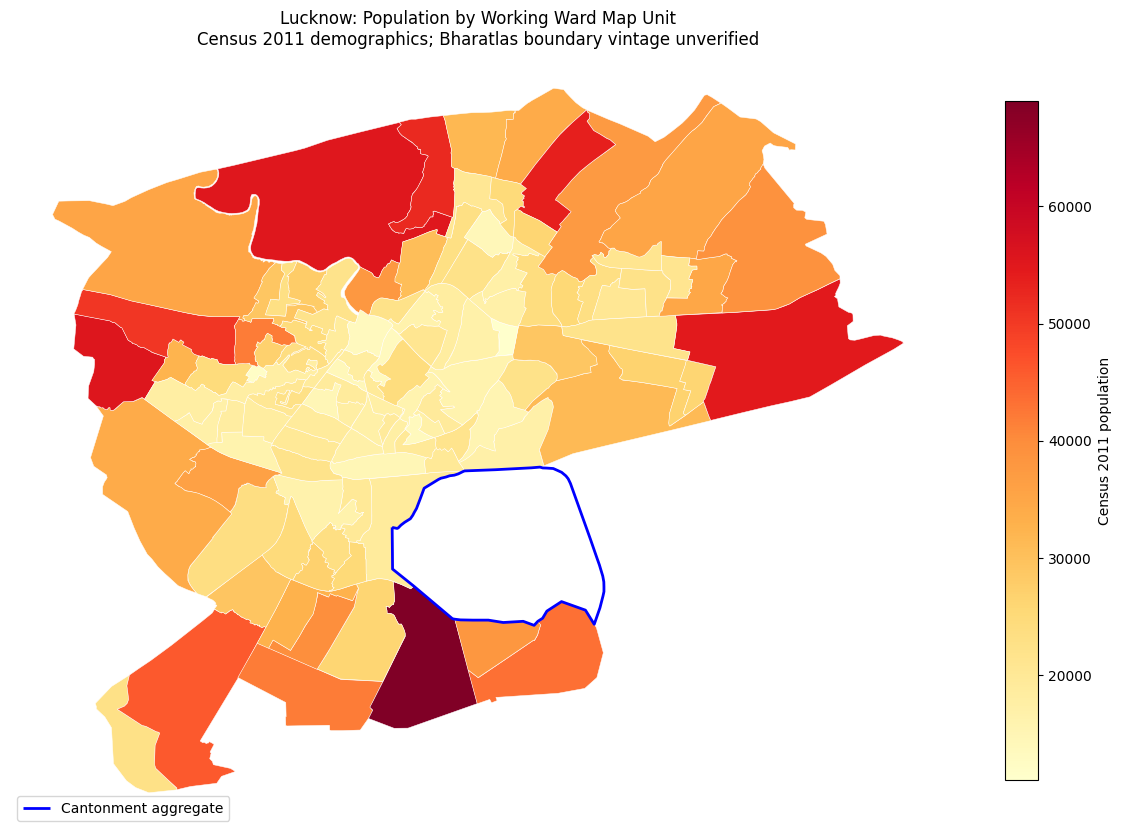

LMC wards plotted: 110
Cantonment aggregate polygons: 1
Total population represented: 2,880,108


In [ ]:

import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

INPUT_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_map_boundaries_with_demographics.gpkg"
)

gdf = gpd.read_file(
    INPUT_PATH,
    layer="ward_demographics"
)

# Verify the essential fields before plotting
required = [
    "map_unit_id",
    "map_unit_name",
    "map_unit_type",
    "total_population",
    "geometry"
]

missing = [col for col in required if col not in gdf.columns]
if missing:
    raise ValueError(f"Required columns missing: {missing}")

if gdf["total_population"].isna().any():
    raise ValueError("Population is missing for one or more map units.")

# Plot numbered wards
lmc = gdf[gdf["map_unit_type"] == "LMC_WARD"]
cant = gdf[gdf["map_unit_type"] == "CANTONMENT_AGGREGATE"]

fig, ax = plt.subplots(figsize=(12, 10))

lmc.plot(
    column="total_population",
    cmap="YlOrRd",
    linewidth=0.35,
    edgecolor="white",
    legend=True,
    legend_kwds={"label": "Census 2011 population", "shrink": 0.7},
    ax=ax
)

# Outline Cantonment separately to distinguish the aggregate unit
cant.boundary.plot(
    ax=ax,
    color="blue",
    linewidth=2,
    label="Cantonment aggregate"
)

ax.set_title(
    "Lucknow: Population by Working Ward Map Unit\n"
    "Census 2011 demographics; Bharatlas boundary vintage unverified"
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="lower left")
ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()
plt.show()

print("LMC wards plotted:", len(lmc))
print("Cantonment aggregate polygons:", len(cant))
print("Total population represented:", f"{gdf['total_population'].sum():,}")


In [ ]:

import pandas as pd
from pathlib import Path

HOSPITAL_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_hospital_master.csv"
)

if not HOSPITAL_PATH.exists():
    raise FileNotFoundError(f"File not found: {HOSPITAL_PATH}")

hospitals = pd.read_csv(HOSPITAL_PATH, low_memory=False)

print("=" * 65)
print("HOSPITAL DATASET OVERVIEW")
print("=" * 65)
print("Rows:", len(hospitals))
print("Columns:", len(hospitals.columns))
print("\nColumn names:")
for col in hospitals.columns:
    print(f"  - {col}")

print("\n" + "=" * 65)
print("DATA TYPES")
print("=" * 65)
print(hospitals.dtypes.to_string())

print("\n" + "=" * 65)
print("MISSING VALUES")
print("=" * 65)
missing = pd.DataFrame({
    "missing_count": hospitals.isna().sum(),
    "missing_percent": (hospitals.isna().mean() * 100).round(2)
})
print(missing[missing["missing_count"] > 0].to_string())

print("\n" + "=" * 65)
print("DUPLICATE CHECK")
print("=" * 65)
print("Exact duplicate rows:", hospitals.duplicated().sum())

print("\n" + "=" * 65)
print("SAMPLE RECORDS")
print("=" * 65)
display(hospitals.head(10))


HOSPITAL DATASET OVERVIEW
Rows: 286
Columns: 13

Column names:
  - record_key
  - facility_name
  - facility_type
  - ownership
  - beds
  - latitude
  - longitude
  - address
  - registration_no
  - district
  - source
  - coordinate_status
  - bed_status

DATA TYPES
record_key            object
facility_name         object
facility_type         object
ownership             object
beds                 float64
latitude             float64
longitude            float64
address               object
registration_no       object
district              object
source                object
coordinate_status     object
bed_status            object

MISSING VALUES
                 missing_count  missing_percent
registration_no             84            29.37

DUPLICATE CHECK
Exact duplicate rows: 0

SAMPLE RECORDS


,record_key,facility_name,facility_type,ownership,beds,latitude,longitude,address,registration_no,district,source,coordinate_status,bed_status
0,dr shyama prasad mukherjee civil hospital||26....,Dr. Shyama Prasad Mukherjee (Civil) Hospital,Government Hospital,public,401.0,26.844668,80.948981,"Hazratganj, Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,Coordinates found in public geospatial directo...,reported
1,king george s medical university kgmu hospital...,King George’s Medical University (KGMU) Hospital,Government Teaching Hospital,public,3500.0,26.861000,80.929000,"Chowk, Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,needs_verification,reported
2,dr ram manohar lohia institute of medical scie...,Dr. Ram Manohar Lohia Institute of Medical Sci...,Government Teaching Hospital,public,1285.0,26.870000,81.005000,"Gomti Nagar, Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,needs_verification,reported
3,sanjay gandhi postgraduate institute of medica...,Sanjay Gandhi Postgraduate Institute of Medica...,Government Teaching Hospital,public,2272.0,26.746420,80.936060,"Raebareli Road, Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,needs_verification,reported
4,balrampur hospital||26.85729|80.92594,Balrampur Hospital,Government Hospital,public,776.0,26.857292,80.925939,"Kaiserbagh, Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,Coordinates found in public geospatial directo...,reported
5,rani laxmi bai combined hospital||26.83134|80....,Rani Laxmi Bai Combined Hospital,Government Hospital,public,100.0,26.831341,80.891741,"Rajajipuram, Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,Coordinates found in public geospatial directo...,reported
6,lok bandhu shri raj narayan combined hospital|...,Lok Bandhu Shri Raj Narayan Combined Hospital,Government Hospital,public,318.0,26.793499,80.901125,"Kanpur Road, Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,Coordinates found in public geospatial directo...,reported
7,avanti bai mahila chikitsalaya dufferin hospit...,Avanti Bai Mahila Chikitsalaya (Dufferin Hospi...,Government Women Hospital,public,326.0,26.851000,80.936000,"Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,needs_verification,reported
8,chc malihabad||26.9232|80.71005,CHC Malihabad,Community Health Centre,public,30.0,26.923200,80.710050,"Malihabad, Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,needs_verification,reported
9,chc chinhat||26.88146|81.00265,CHC Chinhat,Community Health Centre,public,50.0,26.881460,81.002650,"Chinhat, Lucknow, Uttar Pradesh, India",NaN,Lucknow,public_hospitals_csv,needs_verification,reported


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

HOSPITAL_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_hospital_master.csv"
)

hospitals = pd.read_csv(HOSPITAL_PATH, low_memory=False)

# Convert relevant fields to numeric for validation
for col in ["latitude", "longitude", "beds"]:
    hospitals[col] = pd.to_numeric(hospitals[col], errors="coerce")

print("=" * 65)
print("1. COORDINATE COMPLETENESS")
print("=" * 65)

has_lat = hospitals["latitude"].notna()
has_lon = hospitals["longitude"].notna()
has_both = has_lat & has_lon

print("Total facilities:", len(hospitals))
print("Both coordinates present:", int(has_both.sum()))
print("Both coordinates missing:", int((~has_lat & ~has_lon).sum()))
print("Latitude only:", int((has_lat & ~has_lon).sum()))
print("Longitude only:", int((~has_lat & has_lon).sum()))

print("\nCoordinate status counts:")
print(hospitals["coordinate_status"].fillna("MISSING").value_counts().to_string())

print("\n" + "=" * 65)
print("2. COORDINATE RANGE CHECK")
print("=" * 65)

# Broad geographic sanity check for Lucknow and surrounding areas.
# This is not a definitive administrative-boundary test.
plausible = (
    has_both
    & hospitals["latitude"].between(25.0, 28.0)
    & hospitals["longitude"].between(79.0, 83.0)
)

# Approximate bounding box of the candidate ward map layer
inside_map_bbox = (
    has_both
    & hospitals["latitude"].between(26.74407895, 26.93436358)
    & hospitals["longitude"].between(80.83111634, 81.06093189)
)

print("Coordinates within broad sanity-check range:", int(plausible.sum()))
print("Coordinates outside broad sanity-check range:", int((has_both & ~plausible).sum()))
print("Coordinates inside candidate map bounding box:", int(inside_map_bbox.sum()))
print("Coordinates outside candidate map bounding box:", int((has_both & ~inside_map_bbox).sum()))

print("\nRecords outside the broad range:")
display(hospitals.loc[
    has_both & ~plausible,
    ["facility_name", "latitude", "longitude", "address", "coordinate_status"]
])

print("\nRecords outside the candidate map bounding box (first 20):")
display(hospitals.loc[
    has_both & ~inside_map_bbox,
    ["facility_name", "latitude", "longitude", "address", "coordinate_status"]
].head(20))

print("\n" + "=" * 65)
print("3. BED COUNT VALIDATION")
print("=" * 65)

beds = hospitals["beds"]

print("Bed counts present:", int(beds.notna().sum()))
print("Bed counts missing:", int(beds.isna().sum()))
print("Zero bed counts:", int((beds == 0).sum()))
print("Negative bed counts:", int((beds < 0).sum()))
print("Non-integer bed counts:", int((beds.notna() & (beds % 1 != 0)).sum()))

print("\nBed status counts:")
print(hospitals["bed_status"].fillna("MISSING").value_counts().to_string())

print("\nBed-count summary:")
print(beds.describe().to_string())

print("\nPotential bed-count anomalies:")
display(hospitals.loc[
    (beds < 0) | (beds == 0) | (beds > 5000),
    ["facility_name", "facility_type", "ownership", "beds", "bed_status", "source"]
])

print("\n" + "=" * 65)
print("4. FACILITY AND SOURCE BREAKDOWN")
print("=" * 65)

for col in ["facility_type", "ownership", "source"]:
    print(f"\n{col}:")
    print(hospitals[col].fillna("MISSING").value_counts().to_string())

print("\n" + "=" * 65)
print("5. POSSIBLE DUPLICATES BY COORDINATES")
print("=" * 65)

coordinate_duplicates = hospitals.loc[
    has_both & hospitals.duplicated(
        subset=["latitude", "longitude"], keep=False
    ),
    ["facility_name", "latitude", "longitude", "address", "source"]
].sort_values(["latitude", "longitude", "facility_name"])

print("Records sharing exact coordinates:", len(coordinate_duplicates))
display(coordinate_duplicates.head(30))


1. COORDINATE COMPLETENESS
Total facilities: 286
Both coordinates present: 286
Both coordinates missing: 0
Latitude only: 0
Longitude only: 0

Coordinate status counts:
coordinate_status
needs_verification                                                                  282
Coordinates found in public geospatial directory; field verification recommended      4

2. COORDINATE RANGE CHECK
Coordinates within broad sanity-check range: 286
Coordinates outside broad sanity-check range: 0
Coordinates inside candidate map bounding box: 221
Coordinates outside candidate map bounding box: 65

Records outside the broad range:


,facility_name,latitude,longitude,address,coordinate_status



Records outside the candidate map bounding box (first 20):


,facility_name,latitude,longitude,address,coordinate_status
8,CHC Malihabad,26.923200,80.710050,"Malihabad, Lucknow, Uttar Pradesh, India",needs_verification
10,CHC Sarojini Nagar,26.747977,80.764461,"Sarojini Nagar, Lucknow, Uttar Pradesh, India",needs_verification
11,CHC Kakori,26.869400,80.785200,"Kakori, Lucknow, Uttar Pradesh, India",needs_verification
12,CHC Mall,27.021600,80.741700,"Mall, Lucknow, Uttar Pradesh, India",needs_verification
13,CHC Bakshi Ka Talab (BKT),26.983700,80.920700,"Bakshi Ka Talab, Lucknow, Uttar Pradesh, India",needs_verification
14,CHC Itaunja,27.083470,80.896720,"Itaunja, Lucknow, Uttar Pradesh, India",needs_verification
15,CHC Mohanlalganj,26.686100,80.988600,"Mohanlalganj, Lucknow, Uttar Pradesh, India",needs_verification
16,PHC Nagram,26.618721,81.140431,"Nagram, Lucknow, Uttar Pradesh, India",needs_verification
17,PHC Haroni,26.706966,80.749534,"Haroni, Lucknow, Uttar Pradesh, India",needs_verification
23,SWASTIKA MOTHER AND CHILD CARE,26.691306,80.828598,"Kanpur - Lucknow Rd, near Lucknow Surgical hos...",needs_verification



3. BED COUNT VALIDATION
Bed counts present: 286
Bed counts missing: 0
Zero bed counts: 8
Negative bed counts: 0
Non-integer bed counts: 0

Bed status counts:
bed_status
reported                      278
zero_requires_verification      8

Bed-count summary:
count     286.000000
mean       85.041958
std       288.098762
min         0.000000
25%        10.000000
50%        20.000000
75%        49.750000
max      3500.000000

Potential bed-count anomalies:


,facility_name,facility_type,ownership,beds,bed_status,source
25,Brigadier's eye clinic,Hospital,unknown,0.0,zero_requires_verification,hospital_workbook
60,ADVANCE LAPAROSCOPIC AND GYNAE CLINIC,Hospital,unknown,0.0,zero_requires_verification,hospital_workbook
189,Neelkanth Eye Hospital,Hospital,unknown,0.0,zero_requires_verification,hospital_workbook
205,CONFIDENT DENTAL CLINIC,Hospital,unknown,0.0,zero_requires_verification,hospital_workbook
227,T S MISRA MEDICAL COLLEGE AND HOSPITAL,Hospital,unknown,0.0,zero_requires_verification,hospital_workbook
229,FATIMA HOSPITAL,Hospital,unknown,0.0,zero_requires_verification,hospital_workbook
256,RIDANSH HOSPITAL PRIVATE LIMITED,Hospital,unknown,0.0,zero_requires_verification,hospital_workbook
263,Myra City Hospital,Hospital,unknown,0.0,zero_requires_verification,hospital_workbook



4. FACILITY AND SOURCE BREAKDOWN

facility_type:
facility_type
Hospital                         267
Community Health Centre            8
Government Hospital                4
Government Teaching Hospital       3
Primary Health Centre              2
Government Women Hospital          1
Government Specialty Hospital      1

ownership:
ownership
unknown    267
public      19

source:
source
hospital_workbook       267
public_hospitals_csv     19

5. POSSIBLE DUPLICATES BY COORDINATES
Records sharing exact coordinates: 29


,facility_name,latitude,longitude,address,source
20,CHAKRAWARTI EYE HOSPITAL AND ENT CENTRE,26.789059,80.969422,"08, Sahinoor Colony, behind पाल डेयरी, Nilmath...",hospital_workbook
40,CHAKRAWARTI EYE HOSPITAL AND ENT CENTRE,26.789059,80.969422,"08, Sahinoor Colony, behind पाल डेयरी, Nilmath...",hospital_workbook
60,ADVANCE LAPAROSCOPIC AND GYNAE CLINIC,26.790735,80.998291,"3, Skyline Plaza 3, G-48, beside Dayal Bagh, G...",hospital_workbook
131,ADVANCE LAPAROSCOPIC AND GYNAE CLINIC,26.790735,80.998291,"3, Skyline Plaza 3, G-48, beside Dayal Bagh, G...",hospital_workbook
76,VIRAT MEDICITY SUPER SPECIALITY HOSPITAL AND D...,26.796351,80.912719,"D-2/7, Kanpur Rd, Sector H, LDA, Lucknow, Utta...",hospital_workbook
141,VIRAT MEDICITY SUPER SPECIALITY HOSPITAL AND D...,26.796351,80.912719,"D-2/7, Kanpur Rd, Sector H, LDA, Lucknow, Utta...",hospital_workbook
182,ALPHA HOSPITAL AND MATERNITY CENTRE,26.843675,80.949054,"7A, Park Rd, opposite Civil Hospital, Raj Bhav...",hospital_workbook
211,City Hospital and maternity center,26.843675,80.949054,"7A, Park Rd, opposite Civil Hospital, Raj Bhav...",hospital_workbook
25,Brigadier's eye clinic,26.846694,80.946166,"Lucknow, Uttar Pradesh, India",hospital_workbook
273,CHANDAN HOSPITAL LTD.,26.846694,80.946166,"RWWW+MFF, Narpatkhera, Lalbagh, Lucknow, Uttar...",hospital_workbook


In [ ]:

import pandas as pd
from pathlib import Path

HOSPITAL_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_hospital_master.csv"
)

hospitals = pd.read_csv(HOSPITAL_PATH, low_memory=False)

# Ensure coordinates are numeric
hospitals["latitude"] = pd.to_numeric(
    hospitals["latitude"], errors="coerce"
)
hospitals["longitude"] = pd.to_numeric(
    hospitals["longitude"], errors="coerce"
)

valid = hospitals.dropna(
    subset=["latitude", "longitude"]
).copy()

# Group records sharing exactly the same coordinate pair
groups = (
    valid.groupby(["latitude", "longitude"])
    .agg(
        record_count=("facility_name", "size"),
        distinct_facilities=("facility_name", "nunique"),
        facility_names=(
            "facility_name",
            lambda x: " | ".join(x.astype(str))
        ),
        addresses=(
            "address",
            lambda x: " | ".join(
                x.dropna().astype(str).drop_duplicates()
            )
        ),
        sources=(
            "source",
            lambda x: " | ".join(
                x.dropna().astype(str).drop_duplicates()
            )
        ),
    )
    .reset_index()
)

repeated = groups[groups["record_count"] > 1].copy()
repeated = repeated.sort_values(
    ["record_count", "distinct_facilities"],
    ascending=False
)

print("TOTAL COORDINATE GROUPS")
print("Hospital records with coordinates:", len(valid))
print("Unique coordinate pairs:", len(groups))
print("Coordinate pairs shared by multiple records:", len(repeated))
print(
    "Records belonging to repeated-coordinate groups:",
    int(repeated["record_count"].sum())
)
print(
    "Groups containing 3 or more distinct facility names:",
    int((repeated["distinct_facilities"] >= 3).sum())
)

print("\nREPEATED COORDINATE GROUPS")
display(repeated)

# Save this diagnostic report separately; do not change the master file.
OUTPUT_PATH = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "hospital_repeated_coordinate_audit.csv"
)

repeated.to_csv(OUTPUT_PATH, index=False)
print("\nDiagnostic report saved to:", OUTPUT_PATH)


TOTAL COORDINATE GROUPS
Hospital records with coordinates: 286
Unique coordinate pairs: 266
Coordinate pairs shared by multiple records: 9
Records belonging to repeated-coordinate groups: 29
Groups containing 3 or more distinct facility names: 4

REPEATED COORDINATE GROUPS


,latitude,longitude,record_count,distinct_facilities,facility_names,addresses,sources
98,26.846694,80.946166,9,9,R S HOSPITAL | Brigadier's eye clinic | RAJ SU...,"RWWW+MFF Mishrapur Dipo, Narpatkhera, Lalbagh,...",hospital_workbook
122,26.857289,81.039169,4,4,GUARDIAN 25 MULTISPECIALITY HOSPITAL | ELITE M...,"Schumacher Colony, Vikalp Khand, Gomti Nagar, ...",hospital_workbook
103,26.848879,80.874089,3,3,BHASKAR HOSPITAL | ULTRA HOSPITAL | ARUN HOSPITAL,"Hospital, Ashraf Nagar, Rajajipuram, Lucknow, ...",hospital_workbook
115,26.856221,80.954503,3,3,AAROGYA JYOTI MEDICITY PRIVATE LIMITED | BHAVY...,"VX43+FRJ, Parehta, Gokhale Vihar, Gomti Nagar,...",hospital_workbook
89,26.843675,80.949054,2,2,ALPHA HOSPITAL AND MATERNITY CENTRE | City Hos...,"7A, Park Rd, opposite Civil Hospital, Raj Bhav...",hospital_workbook
247,26.943397,80.931038,2,2,R.S. SEWA HOSPITAL | SEWA HOSPITAL AND RESEARC...,"Sewa Nagar, NH-24, Sitapur Rd, Govind Puram, B...",hospital_workbook
44,26.789059,80.969422,2,1,CHAKRAWARTI EYE HOSPITAL AND ENT CENTRE | CHAK...,"08, Sahinoor Colony, behind पाल डेयरी, Nilmath...",hospital_workbook
46,26.790735,80.998291,2,1,ADVANCE LAPAROSCOPIC AND GYNAE CLINIC | ADVANC...,"3, Skyline Plaza 3, G-48, beside Dayal Bagh, G...",hospital_workbook
52,26.796351,80.912719,2,1,VIRAT MEDICITY SUPER SPECIALITY HOSPITAL AND D...,"D-2/7, Kanpur Rd, Sector H, LDA, Lucknow, Utta...",hospital_workbook



Diagnostic report saved to: /content/gdrive/MyDrive/lucknow_census_processed/hospital_repeated_coordinate_audit.csv


In [ ]:

import pandas as pd
import re
from pathlib import Path

BASE_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)
HOSPITAL_PATH = BASE_DIR / "lucknow_hospital_master.csv"

df = pd.read_csv(HOSPITAL_PATH, low_memory=False)

for col in ["latitude", "longitude", "beds"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Normalize names for comparison without changing the original names
def normalize_name(value):
    if pd.isna(value):
        return ""
    value = str(value).lower().strip()
    value = re.sub(r"[^a-z0-9]+", " ", value)
    return re.sub(r"\s+", " ", value).strip()

df["normalized_name"] = df["facility_name"].apply(normalize_name)

# A. Inspect every record whose coordinates are shared
coord_counts = df.groupby(
    ["latitude", "longitude"]
)["facility_name"].transform("size")

shared = df.loc[
    coord_counts > 1,
    [
        "record_key", "facility_name", "facility_type", "ownership",
        "beds", "latitude", "longitude", "address", "source",
        "coordinate_status", "bed_status"
    ]
].sort_values(["latitude", "longitude", "facility_name"])

print("=" * 70)
print("A. ALL RECORDS WITH SHARED COORDINATES")
print("Records:", len(shared))
print("=" * 70)
display(shared.to_string(index=False))

# B. Find repeated normalized facility names throughout the dataset
name_counts = df.groupby("normalized_name")["facility_name"].transform("size")

repeated_names = df.loc[
    (name_counts > 1) & (df["normalized_name"] != ""),
    [
        "facility_name", "normalized_name", "beds",
        "latitude", "longitude", "address", "source"
    ]
].sort_values(["normalized_name", "facility_name"])

print("\n" + "=" * 70)
print("B. REPEATED NORMALIZED FACILITY NAMES")
print("Records involved:", len(repeated_names))
print("=" * 70)
display(repeated_names.to_string(index=False))

# C. Summarize possible same-name duplicate groups
summary = (
    df[df["normalized_name"] != ""]
    .groupby("normalized_name")
    .agg(
        record_count=("record_key", "size"),
        names=("facility_name", lambda s: " | ".join(s.astype(str).unique())),
        unique_coordinates=(
            "latitude",
            lambda s: df.loc[s.index, ["latitude", "longitude"]]
            .drop_duplicates().shape[0]
        ),
        unique_addresses=("address", "nunique"),
        sources=("source", lambda s: " | ".join(s.astype(str).unique()))
    )
    .query("record_count > 1")
    .reset_index()
)

print("\n" + "=" * 70)
print("C. SUMMARY OF SAME-NAME GROUPS")
print("=" * 70)
display(summary.to_string(index=False))

# Save a separate audit report; preserve the master dataset unchanged
shared.to_csv(BASE_DIR / "hospital_shared_coordinate_records.csv", index=False)
repeated_names.to_csv(BASE_DIR / "hospital_repeated_name_records.csv", index=False)
summary.to_csv(BASE_DIR / "hospital_repeated_name_groups.csv", index=False)

print("\nSaved three audit reports. The hospital master file was not modified.")


A. ALL RECORDS WITH SHARED COORDINATES
Records: 29


"                                                                              record_key                                              facility_name facility_type ownership  beds  latitude  longitude                                                                                                                   address            source  coordinate_status                 bed_status\n                   chakrawarti eye hospital and ent centre|rmee2658996|26.78906|80.96942                    CHAKRAWARTI EYE HOSPITAL AND ENT CENTRE      Hospital   unknown  30.0 26.789059  80.969422                   08, Sahinoor Colony, behind पाल डेयरी, Nilmatha Cantt, Neel Matha, Lucknow, Uttar Pradesh 226002, India hospital_workbook needs_verification                   reported\n                   chakrawarti eye hospital and ent centre|rmee2658979|26.78906|80.96942                    CHAKRAWARTI EYE HOSPITAL AND ENT CENTRE      Hospital   unknown   5.0 26.789059  80.969422                   08, Sahino


B. REPEATED NORMALIZED FACILITY NAMES
Records involved: 6


'                                             facility_name                                            normalized_name  beds  latitude  longitude                                                                                                                   address            source\n                     ADVANCE LAPAROSCOPIC AND GYNAE CLINIC                      advance laparoscopic and gynae clinic   0.0 26.790735  80.998291 3, Skyline Plaza 3, G-48, beside Dayal Bagh, Golf City, Sector B Ansal API, Lucknow, Ahmamau, Uttar Pradesh 226030, India hospital_workbook\n                     ADVANCE LAPAROSCOPIC AND GYNAE CLINIC                      advance laparoscopic and gynae clinic  10.0 26.790735  80.998291 3, Skyline Plaza 3, G-48, beside Dayal Bagh, Golf City, Sector B Ansal API, Lucknow, Ahmamau, Uttar Pradesh 226030, India hospital_workbook\n                   CHAKRAWARTI EYE HOSPITAL AND ENT CENTRE                    chakrawarti eye hospital and ent centre  30.0 26.789059  80.969


C. SUMMARY OF SAME-NAME GROUPS


'                                           normalized_name  record_count                                                      names  unique_coordinates  unique_addresses           sources\n                     advance laparoscopic and gynae clinic             2                      ADVANCE LAPAROSCOPIC AND GYNAE CLINIC                   1                 1 hospital_workbook\n                   chakrawarti eye hospital and ent centre             2                    CHAKRAWARTI EYE HOSPITAL AND ENT CENTRE                   1                 1 hospital_workbook\nvirat medicity super speciality hospital and diabetes care             2 VIRAT MEDICITY SUPER SPECIALITY HOSPITAL AND DIABETES CARE                   1                 1 hospital_workbook'


Saved three audit reports. The hospital master file was not modified.


In [ ]:

import pandas as pd
from pathlib import Path

base_dir = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)
input_path = base_dir / "lucknow_hospital_master.csv"
output_path = base_dir / "lucknow_hospital_master_cleaned.csv"

df = pd.read_csv(input_path, low_memory=False)

target_names = [
    "ADVANCE LAPAROSCOPIC AND GYNAE CLINIC",
    "CHAKRAWARTI EYE HOSPITAL AND ENT CENTRE",
    "VIRAT MEDICITY SUPER SPECIALITY HOSPITAL AND DIABETES CARE",
]

name_norm = df["facility_name"].astype("string").str.strip().str.upper()
drop_indices = []

for name in target_names:
    indices = df.index[name_norm.eq(name)].tolist()
    group = df.loc[indices].copy()
    group["beds"] = pd.to_numeric(group["beds"], errors="coerce")

    if len(group) != 2:
        raise ValueError(
            f"{name}: expected exactly 2 records, found {len(group)}"
        )

    if group["beds"].isna().any():
        raise ValueError(f"{name}: missing bed count; no safe deletion.")

    if group["beds"].duplicated().any():
        raise ValueError(f"{name}: bed counts are tied; no safe deletion.")

    lower_index = group["beds"].idxmin()
    higher_index = group["beds"].idxmax()

    print(
        f"{name}: deleting {group.loc[lower_index, 'beds']:g} beds; "
        f"retaining {group.loc[higher_index, 'beds']:g} beds"
    )
    drop_indices.append(lower_index)

cleaned = df.drop(index=drop_indices).copy()
cleaned.to_csv(output_path, index=False)

# Verify the result
check = pd.read_csv(output_path, low_memory=False)
assert len(df) == len(check) + 3

print("\nOriginal records:", len(df))
print("Deleted records:", len(drop_indices))
print("Cleaned records:", len(check))
print("Saved to:", output_path)


ADVANCE LAPAROSCOPIC AND GYNAE CLINIC: deleting 0 beds; retaining 10 beds
CHAKRAWARTI EYE HOSPITAL AND ENT CENTRE: deleting 5 beds; retaining 30 beds
VIRAT MEDICITY SUPER SPECIALITY HOSPITAL AND DIABETES CARE: deleting 25 beds; retaining 30 beds

Original records: 286
Deleted records: 3
Cleaned records: 283
Saved to: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_hospital_master_cleaned.csv


In [ ]:

import pandas as pd
import geopandas as gpd
from pathlib import Path

BASE_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)

HOSPITAL_PATH = BASE_DIR / "lucknow_hospital_master_cleaned.csv"
BOUNDARY_PATH = BASE_DIR / "lucknow_map_boundaries_with_demographics.gpkg"

# 1. Load datasets
hospitals = pd.read_csv(HOSPITAL_PATH, low_memory=False)

wards = gpd.read_file(
    BOUNDARY_PATH,
    layer="ward_demographics"
)

# 2. Validate required columns
required_hospital_cols = [
    "facility_name", "latitude", "longitude", "beds",
    "facility_type", "ownership", "coordinate_status"
]
missing = [c for c in required_hospital_cols if c not in hospitals.columns]
if missing:
    raise ValueError(f"Hospital columns missing: {missing}")

if wards.crs is None:
    raise ValueError("Ward boundaries have no CRS.")

hospitals["latitude"] = pd.to_numeric(
    hospitals["latitude"], errors="coerce"
)
hospitals["longitude"] = pd.to_numeric(
    hospitals["longitude"], errors="coerce"
)

if hospitals[["latitude", "longitude"]].isna().any().any():
    raise ValueError("Some hospital coordinates are missing or non-numeric.")

# 3. Convert hospitals into spatial points
hospital_gdf = gpd.GeoDataFrame(
    hospitals.copy(),
    geometry=gpd.points_from_xy(
        hospitals["longitude"],
        hospitals["latitude"]
    ),
    crs="EPSG:4326"
)

# Match the CRS of the ward polygons
hospital_gdf = hospital_gdf.to_crs(wards.crs)

# 4. Spatial join: point inside polygon
ward_fields = [
    "map_unit_id", "map_unit_name", "map_unit_type", "geometry"
]
ward_shapes = wards[ward_fields].copy()

joined = gpd.sjoin(
    hospital_gdf,
    ward_shapes,
    how="left",
    predicate="within"
)

# 5. Flag locations for review, safely handling multiple polygon matches

# Count exact coordinate occurrences on the original hospital records
coord_counts = hospitals.groupby(
    ["latitude", "longitude"]
)["facility_name"].transform("size")

# Create a stable record ID before the spatial join if one is not present
hospital_gdf = hospital_gdf.reset_index(drop=True)
hospital_gdf["hospital_row_id"] = range(len(hospital_gdf))

# Rebuild the spatial join so we can detect multiple matches
joined = gpd.sjoin(
    hospital_gdf,
    ward_shapes,
    how="left",
    predicate="within"
)

# Map coordinate flags by the original hospital-row ID.
# This correctly handles extra rows created by multiple polygon matches.
coord_flag_map = pd.Series(
    coord_counts.to_numpy(),
    index=range(len(hospitals))
)

joined["shared_exact_coordinates"] = (
    joined["hospital_row_id"]
    .map(coord_flag_map)
    .gt(1)
)

# Count the number of polygon matches for each hospital
match_counts = joined.groupby("hospital_row_id")["map_unit_id"].count()

joined["polygon_match_count"] = (
    joined["hospital_row_id"].map(match_counts)
)

joined["inside_working_map"] = joined["map_unit_id"].notna()

joined["location_review_flag"] = "review"
joined.loc[
    joined["inside_working_map"] & ~joined["shared_exact_coordinates"],
    "location_review_flag"
] = "inside_polygon_no_exact_coordinate_collision"

joined.loc[
    ~joined["inside_working_map"],
    "location_review_flag"
] = "outside_working_map"

joined.loc[
    joined["inside_working_map"] & joined["shared_exact_coordinates"],
    "location_review_flag"
] = "inside_polygon_shared_coordinates"

# 6. Report results
print("=" * 65)
print("HOSPITAL-TO-WARD SPATIAL AUDIT")
print("=" * 65)
print("Original hospital records:", len(hospitals))
print("Rows after spatial join:", len(joined))
print("Unique hospitals after join:", joined["hospital_row_id"].nunique())
print(
    "Hospitals matched to multiple polygons:",
    int((match_counts > 1).sum())
)
print(
    "Hospitals inside working map:",
    int(joined.loc[joined["map_unit_id"].notna(), "hospital_row_id"].nunique())
)
print(
    "Hospitals outside working map:",
    int(joined.loc[joined["map_unit_id"].isna(), "hospital_row_id"].nunique())
)
print(
    "Hospitals with shared exact coordinates:",
    int(joined.loc[joined["shared_exact_coordinates"], "hospital_row_id"].nunique())
)

print("\nLocation review flags (joined rows):")
print(joined["location_review_flag"].value_counts().to_string())

# Save the audit output
OUTPUT_PATH = BASE_DIR / "hospital_ward_spatial_audit.csv"
joined.drop(columns="geometry").to_csv(OUTPUT_PATH, index=False)

print("\nSpatial audit saved to:", OUTPUT_PATH)

print("\nHospitals matched to multiple polygons:")
display(
    joined.loc[
        joined["hospital_row_id"].isin(match_counts[match_counts > 1].index),
        ["hospital_row_id", "facility_name", "map_unit_id", "map_unit_name",
         "latitude", "longitude", "location_review_flag"]
    ].sort_values(["hospital_row_id", "map_unit_id"])
)


HOSPITAL-TO-WARD SPATIAL AUDIT
Original hospital records: 283
Rows after spatial join: 284
Unique hospitals after join: 283
Hospitals matched to multiple polygons: 1
Hospitals inside working map: 188
Hospitals outside working map: 95
Hospitals with shared exact coordinates: 23

Location review flags (joined rows):
location_review_flag
inside_polygon_no_exact_coordinate_collision    168
outside_working_map                              95
inside_polygon_shared_coordinates                21

Spatial audit saved to: /content/gdrive/MyDrive/lucknow_census_processed/hospital_ward_spatial_audit.csv

Hospitals matched to multiple polygons:


,hospital_row_id,facility_name,map_unit_id,map_unit_name,latitude,longitude,location_review_flag
62,62,ARSH HOSPITAL,LMC_009,Kanhaiya Madhopur,26.875921,80.857082,inside_polygon_no_exact_coordinate_collision
62,62,ARSH HOSPITAL,LMC_025,Bala Ganj,26.875921,80.857082,inside_polygon_no_exact_coordinate_collision


ARSH HOSPITAL coordinate: 80.857082 26.875921

Ward polygon details:

Map unit: LMC_009
Ward name: Kanhaiya Madhopur
Point within polygon: True
Point intersects polygon: True
Distance from point to polygon boundary (degrees): 9.061107037474889e-06

Map unit: LMC_025
Ward name: Bala Ganj
Point within polygon: True
Point intersects polygon: True
Distance from point to polygon boundary (degrees): 6.447863452519752e-06

Polygon overlap area (km²): 0.006330760365629991
Overlap geometry type: MultiPolygon


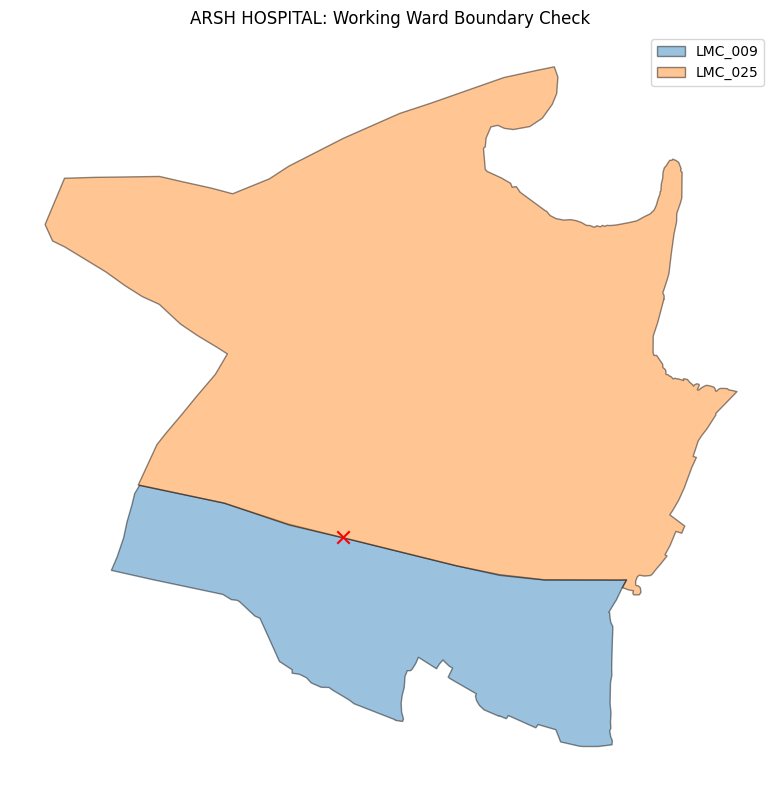

In [ ]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

BASE_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)

BOUNDARY_PATH = BASE_DIR / "lucknow_map_boundaries_with_demographics.gpkg"

wards = gpd.read_file(
    BOUNDARY_PATH,
    layer="ward_demographics"
)

hospital_lat = 26.875921
hospital_lon = 80.857082

# Find the two wards involved in the multiple match
target_ids = ["LMC_009", "LMC_025"]
target_wards = wards[wards["map_unit_id"].isin(target_ids)].copy()

point = gpd.GeoSeries(
    gpd.points_from_xy([hospital_lon], [hospital_lat]),
    crs="EPSG:4326"
).to_crs(wards.crs).iloc[0]

print("ARSH HOSPITAL coordinate:", hospital_lon, hospital_lat)
print("\nWard polygon details:")

for _, ward in target_wards.iterrows():
    print("\nMap unit:", ward["map_unit_id"])
    print("Ward name:", ward["map_unit_name"])
    print("Point within polygon:", point.within(ward.geometry))
    print("Point intersects polygon:", point.intersects(ward.geometry))
    print("Distance from point to polygon boundary (degrees):",
          point.distance(ward.geometry.boundary))

# Check the overlap between the two polygons in a projected CRS
target_projected = target_wards.to_crs("EPSG:32644")
if len(target_projected) == 2:
    overlap = target_projected.geometry.iloc[0].intersection(
        target_projected.geometry.iloc[1]
    )
    print("\nPolygon overlap area (km²):", overlap.area / 1_000_000)
    print("Overlap geometry type:", overlap.geom_type)

# Plot the two polygons and hospital point
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 8))

target_wards.plot(
    ax=ax,
    column="map_unit_id",
    alpha=0.45,
    edgecolor="black",
    legend=True
)

point_gdf = gpd.GeoDataFrame(
    {"facility": ["ARSH HOSPITAL"]},
    geometry=[point],
    crs=wards.crs
)
point_gdf.plot(ax=ax, color="red", markersize=80, marker="x")

ax.set_title("ARSH HOSPITAL: Working Ward Boundary Check")
ax.set_axis_off()
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)
HOSPITAL_PATH = BASE_DIR / "lucknow_hospital_master_cleaned.csv"

df = pd.read_csv(HOSPITAL_PATH, low_memory=False)

# Identify ARSH HOSPITAL
mask = df["facility_name"].astype(str).str.strip().str.upper().eq(
    "ARSH HOSPITAL"
)

if mask.sum() != 1:
    raise ValueError(
        f"Expected exactly one ARSH HOSPITAL record; found {mask.sum()}. "
        "No changes made."
    )

# Assign the intended ward directly in the cleaned CSV
df.loc[mask, "assigned_map_unit_id"] = "LMC_009"
df.loc[mask, "assigned_map_unit_name"] = "Kanhaiya Madhopur"
df.loc[mask, "ward_assignment_status"] = "forced_manual_assignment"

# Overwrite the cleaned file
df.to_csv(HOSPITAL_PATH, index=False)

# Verify the saved record
check = pd.read_csv(HOSPITAL_PATH, low_memory=False)
result = check.loc[check["facility_name"].astype(str).str.strip().str.upper().eq(
    "ARSH HOSPITAL"
), [
    "facility_name",
    "latitude",
    "longitude",
    "assigned_map_unit_id",
    "assigned_map_unit_name",
    "ward_assignment_status"
]]

print("Updated cleaned hospital CSV:", HOSPITAL_PATH)
display(result)


Updated cleaned hospital CSV: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_hospital_master_cleaned.csv


,facility_name,latitude,longitude,assigned_map_unit_id,assigned_map_unit_name,ward_assignment_status
62,ARSH HOSPITAL,26.875921,80.857082,LMC_009,Kanhaiya Madhopur,forced_manual_assignment


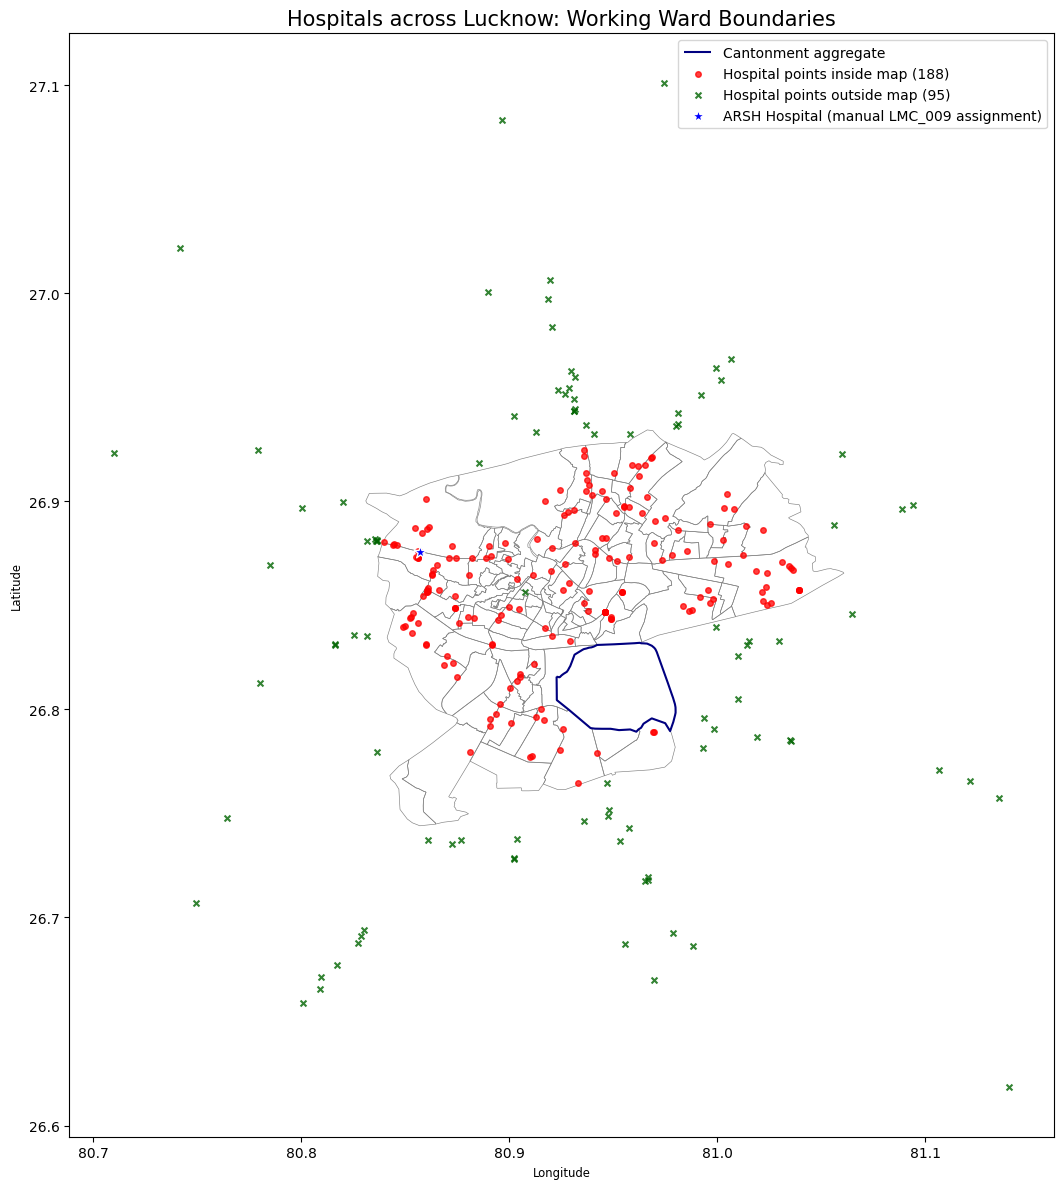

Hospital records plotted: 283
Inside working map: 188
Outside working map: 95
Map saved to: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_all_hospitals_map.png


In [ ]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)

HOSPITAL_PATH = BASE_DIR / "lucknow_hospital_master_cleaned.csv"
BOUNDARY_PATH = BASE_DIR / "lucknow_map_boundaries_with_demographics.gpkg"

# Load datasets
hospitals = pd.read_csv(HOSPITAL_PATH, low_memory=False)
wards = gpd.read_file(
    BOUNDARY_PATH,
    layer="ward_demographics"
)

# Validate coordinates
hospitals["latitude"] = pd.to_numeric(
    hospitals["latitude"], errors="coerce"
)
hospitals["longitude"] = pd.to_numeric(
    hospitals["longitude"], errors="coerce"
)

hospitals = hospitals.dropna(
    subset=["latitude", "longitude"]
).copy()

# Create point geometries
hospital_points = gpd.GeoDataFrame(
    hospitals,
    geometry=gpd.points_from_xy(
        hospitals["longitude"],
        hospitals["latitude"]
    ),
    crs="EPSG:4326"
).to_crs(wards.crs)

# Classify points by whether they intersect the working map
ward_union = wards.geometry.union_all()
hospital_points["inside_working_map"] = (
    hospital_points.geometry.apply(ward_union.covers)
)

inside = hospital_points[hospital_points["inside_working_map"]]
outside = hospital_points[~hospital_points["inside_working_map"]]

# Plot
fig, ax = plt.subplots(figsize=(14, 12))

# Urban ward polygons
lmc = wards[wards["map_unit_type"] == "LMC_WARD"]
cantonment = wards[
    wards["map_unit_type"] == "CANTONMENT_AGGREGATE"
]

lmc.boundary.plot(
    ax=ax,
    color="grey",
    linewidth=0.45
)

cantonment.boundary.plot(
    ax=ax,
    color="navy",
    linewidth=1.5,
    label="Cantonment aggregate"
)

# Hospitals inside and outside the mapped polygons
if len(inside):
    inside.plot(
        ax=ax,
        color="red",
        markersize=16,
        alpha=0.75,
        label=f"Hospital points inside map ({len(inside)})",
        zorder=3
    )

if len(outside):
    outside.plot(
        ax=ax,
        color="darkgreen",
        markersize=18,
        marker="x",
        alpha=0.8,
        label=f"Hospital points outside map ({len(outside)})",
        zorder=4
    )

# Mark the manually assigned ARSH Hospital separately
if "assigned_map_unit_id" in hospital_points.columns:
    arsh = hospital_points[
        hospital_points["facility_name"].astype(str).str.strip().str.upper()
        .eq("ARSH HOSPITAL")
    ]
    if not arsh.empty:
        arsh.plot(
            ax=ax,
            color="blue",
            edgecolor="white",
            markersize=90,
            marker="*",
            label="ARSH Hospital (manual LMC_009 assignment)",
            zorder=5
        )

ax.set_title(
    "Hospitals across Lucknow: Working Ward Boundaries",
    fontsize=15
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.legend(loc="best")
plt.tight_layout()

# Save a copy for project documentation
OUTPUT_PATH = BASE_DIR / "lucknow_all_hospitals_map.png"
plt.savefig(OUTPUT_PATH, dpi=220, bbox_inches="tight")
plt.show()

print("Hospital records plotted:", len(hospital_points))
print("Inside working map:", len(inside))
print("Outside working map:", len(outside))
print("Map saved to:", OUTPUT_PATH)


In [ ]:

import requests
import getpass
import pandas as pd
from IPython.display import display

url = "https://maps.googleapis.com/maps/api/geocode/json"

api_key = getpass.getpass("Enter your Google Maps API key: ")

hospitals_to_geocode = [
    {
        "facility_name": "Cantonment Board Hospital / Cantonment General Hospital",
        "address": (
            "Cantonment Board Hospital, Nehru Road, Sadar Bazaar, "
            "Lucknow Cantonment, Uttar Pradesh 226002, India"
        ),
        "beds": 42,
    },
    {
        "facility_name": "Command Hospital (Central Command)",
        "address": (
            "Command Hospital Central Command, Lal Bahadur Shastri Marg, "
            "Neil Lines, Lucknow Cantonment, Uttar Pradesh 226002, India"
        ),
        "beds": 880,
    },
    {
        "facility_name": "Base Hospital, Lucknow",
        "address": (
            "Base Hospital, Lal Bahadur Shastri Marg, Neil Lines, "
            "Lucknow Cantonment, Uttar Pradesh 226002, India"
        ),
        "beds": 450,
    },
]

results = []

for hospital in hospitals_to_geocode:
    params = {
        "address": hospital["address"],
        "key": api_key,
        "region": "in",
    }

    try:
        response = requests.get(url, params=params, timeout=30)
        response.raise_for_status()
        data = response.json()

        result = {
            **hospital,
            "geocode_status": data.get("status"),
            "latitude": None,
            "longitude": None,
            "formatted_address": None,
            "place_id": None,
            "location_type": None,
            "partial_match": None,
            "error_message": data.get("error_message"),
        }

        if data.get("status") == "OK" and data.get("results"):
            best = data["results"][0]
            location = best["geometry"]["location"]

            result.update({
                "latitude": location["lat"],
                "longitude": location["lng"],
                "formatted_address": best.get("formatted_address"),
                "place_id": best.get("place_id"),
                "location_type": best["geometry"].get("location_type"),
                "partial_match": best.get("partial_match", False),
            })

        results.append(result)

    except requests.RequestException as exc:
        results.append({
            **hospital,
            "geocode_status": "REQUEST_ERROR",
            "latitude": None,
            "longitude": None,
            "formatted_address": None,
            "place_id": None,
            "location_type": None,
            "partial_match": None,
            "error_message": str(exc),
        })

geocode_results = pd.DataFrame(results)

display(geocode_results[[
    "facility_name",
    "beds",
    "geocode_status",
    "latitude",
    "longitude",
    "formatted_address",
    "location_type",
    "partial_match",
    "error_message",
]])

print("\nDo not append the results yet.")
print("Review whether each returned address identifies the intended hospital.")


Enter your Google Maps API key: ··········


,facility_name,beds,geocode_status,latitude,longitude,formatted_address,location_type,partial_match,error_message
0,Cantonment Board Hospital / Cantonment General...,42,OK,26.825896,80.944500,"1-a, Nehru Rd, Sadar Bazaar, Cantonment, Luckn...",ROOFTOP,False,None
1,Command Hospital (Central Command),880,OK,26.808667,80.936493,"RW5P+9M7, Lal Bahadur Shastri Marg, Neil Lines...",ROOFTOP,True,None
2,"Base Hospital, Lucknow",450,OK,26.808424,80.936671,"Base Hospital CC, Lal Bahadur Shastri Marg, Ne...",ROOFTOP,False,None



Do not append the results yet.
Review whether each returned address identifies the intended hospital.


In [ ]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)
CSV_PATH = BASE_DIR / "lucknow_hospital_master_cleaned.csv"

# Use the geocode_results DataFrame from the previous cell.
if "geocode_results" not in globals():
    raise ValueError("Run the geocoding cell first.")

df = pd.read_csv(CSV_PATH, low_memory=False)

required_result_cols = [
    "facility_name", "beds", "geocode_status", "latitude",
    "longitude", "formatted_address", "location_type", "partial_match"
]
missing = [c for c in required_result_cols if c not in geocode_results.columns]
if missing:
    raise ValueError(f"Geocoding result columns missing: {missing}")

if not geocode_results["geocode_status"].eq("OK").all():
    raise ValueError("At least one geocoding request failed. No records appended.")

if geocode_results[["latitude", "longitude"]].isna().any().any():
    raise ValueError("At least one coordinate is missing. No records appended.")

def normalize_name(value):
    return " ".join(str(value).strip().lower().split())

existing_names = set(
    df["facility_name"].dropna().map(normalize_name)
)

new_rows = []

for _, r in geocode_results.iterrows():
    name = r["facility_name"]

    if normalize_name(name) in existing_names:
        print(f"SKIPPED (name already exists): {name}")
        continue

    # Keep all original master columns; fill applicable fields.
    row = {col: pd.NA for col in df.columns}

    row.update({
        "facility_name": name,
        "facility_type": (
            "Cantonment Board Hospital"
            if "Cantonment Board" in name
            else "Military Hospital"
        ),
        "ownership": "public",
        "beds": int(r["beds"]),
        "latitude": float(r["latitude"]),
        "longitude": float(r["longitude"]),
        "address": r["formatted_address"],
        "district": "Lucknow",
        "source": "Google Maps Geocoding API; bed count supplied by user",
        "coordinate_status": (
            "Google rooftop result; partial match; verify"
            if bool(r["partial_match"])
            else "Google rooftop result; verification recommended"
        ),
        "bed_status": "user_provided",
    })

    # Populate record_key only if that column exists and is blank.
    if "record_key" in df.columns:
        row["record_key"] = (
            f"manual_{normalize_name(name).replace(' ', '_')}"
        )

    new_rows.append(row)
    existing_names.add(normalize_name(name))

if new_rows:
    new_df = pd.DataFrame(new_rows, columns=df.columns)
    updated = pd.concat([df, new_df], ignore_index=True)
    updated.to_csv(CSV_PATH, index=False)
else:
    updated = df.copy()
    print("No new records were required.")

# Verify the saved CSV
check = pd.read_csv(CSV_PATH, low_memory=False)

target_names = [
    "Cantonment Board Hospital / Cantonment General Hospital",
    "Command Hospital (Central Command)",
    "Base Hospital, Lucknow",
]

saved = check[
    check["facility_name"].isin(target_names)
][[
    "facility_name", "beds", "latitude", "longitude",
    "address", "coordinate_status", "bed_status", "source"
]]

print("\nRows appended this run:", len(new_rows))
print("Hospital rows in cleaned CSV:", len(check))
print("Saved file:", CSV_PATH)
display(saved)



Rows appended this run: 3
Hospital rows in cleaned CSV: 286
Saved file: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_hospital_master_cleaned.csv


,facility_name,beds,latitude,longitude,address,coordinate_status,bed_status,source
283,Cantonment Board Hospital / Cantonment General...,42.0,26.825896,80.944500,"1-a, Nehru Rd, Sadar Bazaar, Cantonment, Luckn...",Google rooftop result; verification recommended,user_provided,Google Maps Geocoding API; bed count supplied ...
284,Command Hospital (Central Command),880.0,26.808667,80.936493,"RW5P+9M7, Lal Bahadur Shastri Marg, Neil Lines...",Google rooftop result; partial match; verify,user_provided,Google Maps Geocoding API; bed count supplied ...
285,"Base Hospital, Lucknow",450.0,26.808424,80.936671,"Base Hospital CC, Lal Bahadur Shastri Marg, Ne...",Google rooftop result; verification recommended,user_provided,Google Maps Geocoding API; bed count supplied ...


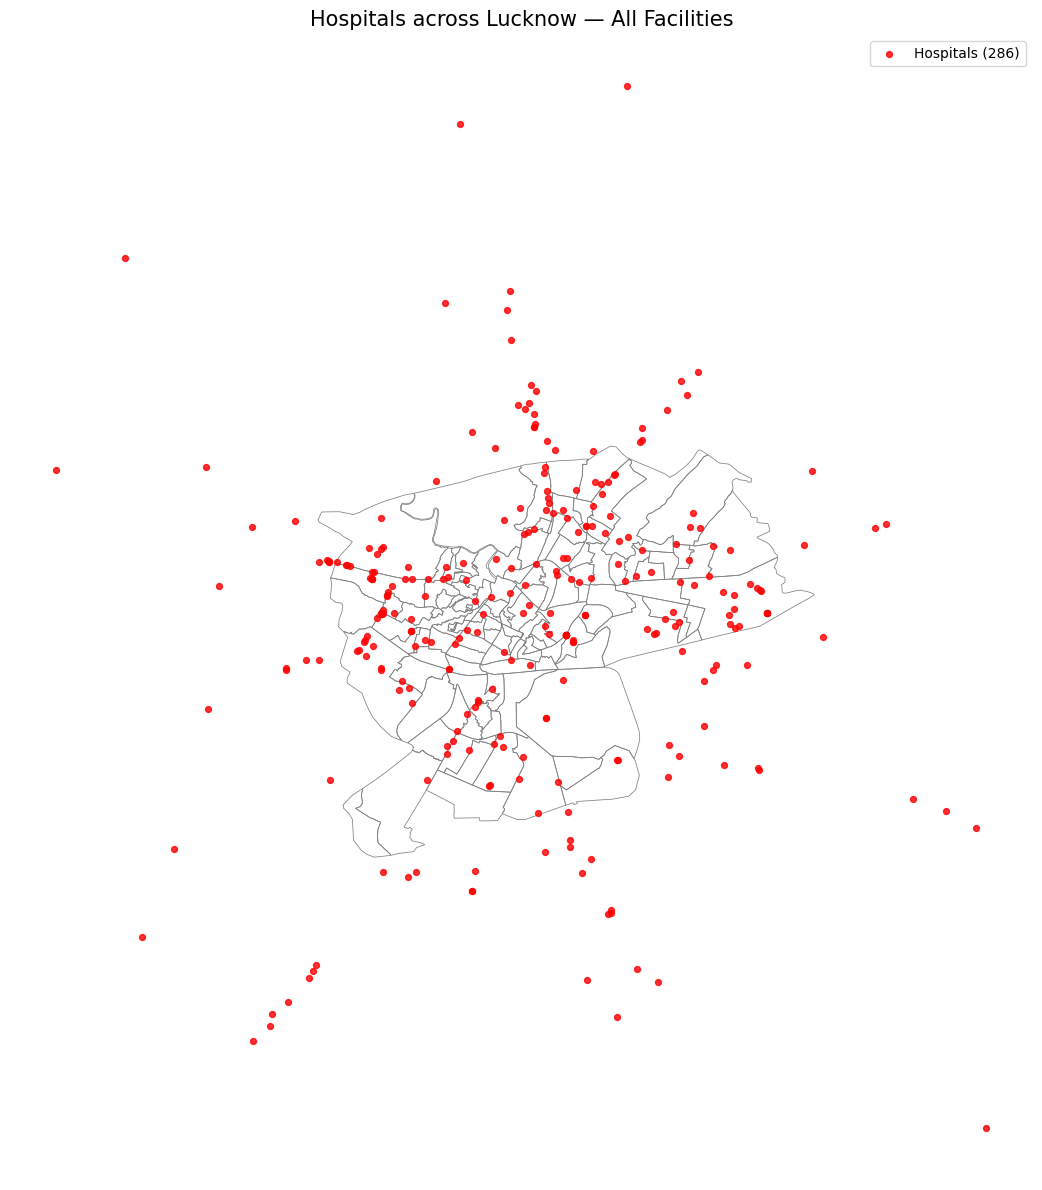

Hospital records plotted: 286
Map saved to: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_all_hospitals_map_updated.png


In [ ]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)
CSV_PATH = BASE_DIR / "lucknow_hospital_master_cleaned.csv"
GPKG_PATH = BASE_DIR / "lucknow_map_boundaries_with_demographics.gpkg"

hospitals = pd.read_csv(CSV_PATH, low_memory=False)
wards = gpd.read_file(GPKG_PATH, layer="ward_demographics")

hospitals["latitude"] = pd.to_numeric(hospitals["latitude"], errors="coerce")
hospitals["longitude"] = pd.to_numeric(hospitals["longitude"], errors="coerce")

hospitals = hospitals.dropna(
    subset=["latitude", "longitude"]
).copy()

points = gpd.GeoDataFrame(
    hospitals,
    geometry=gpd.points_from_xy(
        hospitals["longitude"],
        hospitals["latitude"]
    ),
    crs="EPSG:4326"
).to_crs(wards.crs)

fig, ax = plt.subplots(figsize=(14, 12))

# Draw all working map-unit boundaries in neutral grey
wards.boundary.plot(
    ax=ax,
    color="grey",
    linewidth=0.55
)

# Draw every hospital with the same red dot
points.plot(
    ax=ax,
    color="red",
    markersize=18,
    alpha=0.8,
    label=f"Hospitals ({len(points)})",
    zorder=3
)

ax.set_title(
    "Hospitals across Lucknow — All Facilities",
    fontsize=15
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend(loc="best")

plt.tight_layout()

output_path = BASE_DIR / "lucknow_all_hospitals_map_updated.png"
plt.savefig(output_path, dpi=220, bbox_inches="tight")
plt.show()

print("Hospital records plotted:", len(points))
print("Map saved to:", output_path)


In [ ]:

import pandas as pd
import geopandas as gpd
from pathlib import Path

BASE_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)

CSV_PATH = BASE_DIR / "lucknow_hospital_master_cleaned.csv"
GPKG_PATH = BASE_DIR / "lucknow_map_boundaries_with_demographics.gpkg"

# Load the cleaned hospital inventory and current map polygons
df = pd.read_csv(CSV_PATH, low_memory=False)
wards = gpd.read_file(
    GPKG_PATH,
    layer="ward_demographics"
)

# 1. Replace unknown ownership with private
ownership_before = (
    df["ownership"].astype("string").str.strip().str.lower()
)
unknown_mask = ownership_before.eq("unknown").fillna(False)
unknown_replaced = int(unknown_mask.sum())

df.loc[unknown_mask, "ownership"] = "private"

# 2. Determine whether each hospital falls inside any current map polygon
df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

df["inside_lko_plot"] = False

valid_mask = (
    df["latitude"].notna()
    & df["longitude"].notna()
)

if valid_mask.any():
    points = gpd.GeoDataFrame(
        df.loc[valid_mask].copy(),
        geometry=gpd.points_from_xy(
            df.loc[valid_mask, "longitude"],
            df.loc[valid_mask, "latitude"]
        ),
        crs="EPSG:4326"
    ).to_crs(wards.crs)

    # Union all 111 map-unit polygons into one coverage geometry
    map_coverage = wards.geometry.union_all()

    # covers() includes points on polygon boundaries
    inside_flags = points.geometry.apply(map_coverage.covers)

    df.loc[valid_mask, "inside_lko_plot"] = inside_flags.to_numpy()

# 3. Overwrite the cleaned CSV
df.to_csv(CSV_PATH, index=False)

# 4. Reload and verify the saved file
check = pd.read_csv(CSV_PATH, low_memory=False)

print("Update complete.")
print("Saved to:", CSV_PATH)
print("Total hospital records:", len(check))
print("Ownership values changed from unknown to private:", unknown_replaced)
print("\nOwnership breakdown:")
print(check["ownership"].value_counts(dropna=False).to_string())

print("\nInside current Lucknow plot:")
print(check["inside_lko_plot"].value_counts(dropna=False).to_string())

print("\nRecords with missing coordinates:",
      int(check[["latitude", "longitude"]].isna().any(axis=1).sum()))


Update complete.
Saved to: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_hospital_master_cleaned.csv
Total hospital records: 286
Ownership values changed from unknown to private: 0

Ownership breakdown:
ownership
private    264
public      22

Inside current Lucknow plot:
inside_lko_plot
True     191
False     95

Records with missing coordinates: 0


In [ ]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(
    "/content/gdrive/MyDrive/lucknow_census_processed"
)
CSV_PATH = BASE_DIR / "lucknow_hospital_master_cleaned.csv"

df = pd.read_csv(CSV_PATH, low_memory=False)

for col in ["latitude", "longitude", "beds"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("=" * 60)
print("FINAL HOSPITAL INVENTORY AUDIT")
print("=" * 60)

print("Total records:", len(df))
print("Missing coordinates:", int(
    df[["latitude", "longitude"]].isna().any(axis=1).sum()
))
print("Missing bed counts:", int(df["beds"].isna().sum()))
print("Zero bed counts:", int((df["beds"] == 0).sum()))
print("Negative bed counts:", int((df["beds"] < 0).sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))

print("\nRepeated normalized facility names:")
normalized_names = (
    df["facility_name"].astype("string").str.strip().str.lower()
)
name_counts = normalized_names.value_counts()
print(name_counts[name_counts > 1].to_string())

print("\nRepeated coordinate pairs:")
valid = df.dropna(subset=["latitude", "longitude"])
coord_counts = valid.groupby(
    ["latitude", "longitude"]
).size()
print("Unique coordinate pairs:", len(coord_counts))
print("Pairs shared by multiple records:", int((coord_counts > 1).sum()))
print("Records in shared-coordinate groups:", int(
    coord_counts[coord_counts > 1].sum()
))

print("\nNew Cantonment hospital records:")
target_names = [
    "Cantonment Board Hospital / Cantonment General Hospital",
    "Command Hospital (Central Command)",
    "Base Hospital, Lucknow",
]
display(df.loc[
    df["facility_name"].isin(target_names),
    [
        "facility_name", "beds", "latitude", "longitude",
        "coordinate_status", "bed_status", "source"
    ]
])

print("\nOwnership breakdown:")
print(df["ownership"].fillna("missing").value_counts().to_string())


FINAL HOSPITAL INVENTORY AUDIT
Total records: 286
Missing coordinates: 0
Missing bed counts: 0
Zero bed counts: 7
Negative bed counts: 0
Exact duplicate rows: 0

Repeated normalized facility names:
Series([], )

Repeated coordinate pairs:
Unique coordinate pairs: 269
Pairs shared by multiple records: 6
Records in shared-coordinate groups: 23

New Cantonment hospital records:


,facility_name,beds,latitude,longitude,coordinate_status,bed_status,source
283,Cantonment Board Hospital / Cantonment General...,42.0,26.825896,80.944500,Google rooftop result; verification recommended,user_provided,Google Maps Geocoding API; bed count supplied ...
284,Command Hospital (Central Command),880.0,26.808667,80.936493,Google rooftop result; partial match; verify,user_provided,Google Maps Geocoding API; bed count supplied ...
285,"Base Hospital, Lucknow",450.0,26.808424,80.936671,Google rooftop result; verification recommended,user_provided,Google Maps Geocoding API; bed count supplied ...



Ownership breakdown:
ownership
private    264
public      22


In [ ]:
import os

RAW_DIR = "/content/gdrive/MyDrive/Lucknow_Census_Raw"

print("Existing shapefiles:\n")

for root, dirs, files in os.walk(RAW_DIR):
    for filename in files:
        if filename.lower().endswith(".shp"):
            print(os.path.join(root, filename))

Existing shapefiles:

/content/gdrive/MyDrive/Lucknow_Census_Raw/2011_Dist.shp


In [ ]:
import geopandas as gpd

DISTRICT_SHP = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/2011_Dist.shp"
)

districts = gpd.read_file(DISTRICT_SHP)

print("=== DISTRICT SHAPEFILE AUDIT ===")
print("Total geographic records:", len(districts))
print("Coordinate reference system:", districts.crs)
print("Columns:", districts.columns.tolist())
print("Geometry types:", districts.geometry.geom_type.value_counts().to_dict())
print("Missing geometries:", districts.geometry.isna().sum())
print("Invalid geometries:", (~districts.geometry.is_valid).sum())

print("\n=== SAMPLE RECORDS ===")
print(districts.drop(columns="geometry").head(10).to_string(index=False))

print("\n=== COLUMNS THAT MAY CONTAIN DISTRICT NAMES ===")
for col in districts.columns:
    if districts[col].dtype == "object" and col != "geometry":
        matches = districts[
            districts[col].astype(str).str.contains(
                "Lucknow", case=False, na=False
            )
        ]
        if not matches.empty:
            print(f"\nMatching column: {col}")
            print(matches[[col]].drop_duplicates().to_string(index=False))

=== DISTRICT SHAPEFILE AUDIT ===
Total geographic records: 641
Coordinate reference system: EPSG:4326
Columns: ['DISTRICT', 'ST_NM', 'ST_CEN_CD', 'DT_CEN_CD', 'censuscode', 'geometry']
Geometry types: {'Polygon': 567, 'MultiPolygon': 74}
Missing geometries: 0
Invalid geometries: 1

=== SAMPLE RECORDS ===
  DISTRICT          ST_NM  ST_CEN_CD  DT_CEN_CD  censuscode
  Adilabad Andhra Pradesh         28          1         532
      Agra  Uttar Pradesh          9         15         146
 Ahmadabad        Gujarat         24          7         474
Ahmadnagar    Maharashtra         27         26         522
    Aizawl        Mizoram         15          3         283
     Ajmer      Rajasthan          8         21         119
     Akola    Maharashtra         27          5         501
 Alappuzha         Kerala         32         11         598
   Aligarh  Uttar Pradesh          9         12         143
 Alirajpur Madhya Pradesh         23         48         465

=== COLUMNS THAT MAY CONTAIN DIST

=== LUCKNOW DISTRICT BOUNDARY ===
Matching records: 1
CRS: EPSG:4326
Geometry types: ['Polygon']
Valid geometries: [True]
Bounds (longitude/latitude): [80.56048841 26.50150091 81.21900263 27.1589748 ]

District record:
DISTRICT         ST_NM  ST_CEN_CD  DT_CEN_CD  censuscode
 Lucknow Uttar Pradesh          9         26         157


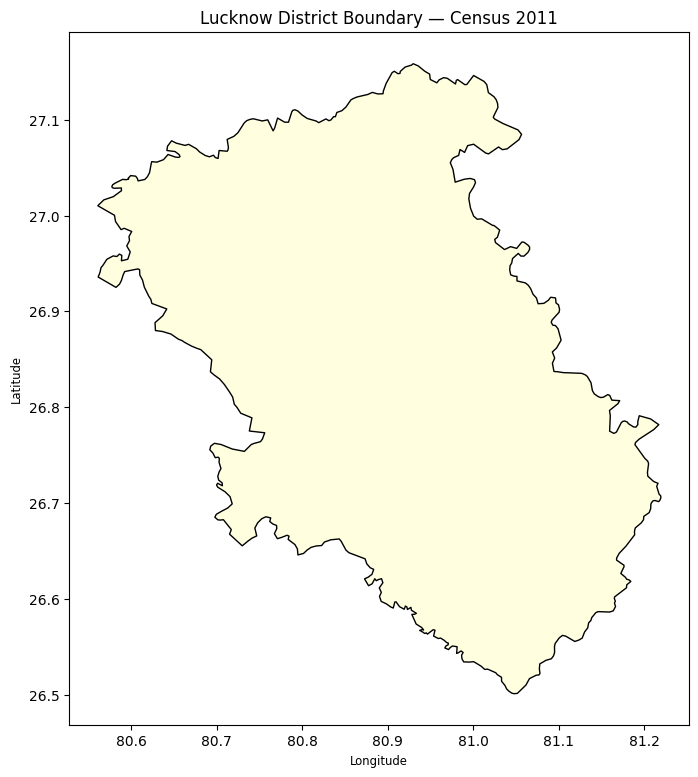

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

DISTRICT_SHP = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/2011_Dist.shp"
)

districts = gpd.read_file(DISTRICT_SHP)

# Select Lucknow district in Uttar Pradesh
lucknow_district = districts[
    (districts["DISTRICT"].str.strip().str.lower() == "lucknow") &
    (districts["ST_NM"].str.strip().str.lower() == "uttar pradesh")
].copy()

print("=== LUCKNOW DISTRICT BOUNDARY ===")
print("Matching records:", len(lucknow_district))
print("CRS:", lucknow_district.crs)
print("Geometry types:", lucknow_district.geometry.geom_type.tolist())
print("Valid geometries:", lucknow_district.geometry.is_valid.tolist())
print("Bounds (longitude/latitude):", lucknow_district.total_bounds)

if len(lucknow_district) == 1:
    print("\nDistrict record:")
    print(lucknow_district.drop(columns="geometry").to_string(index=False))

    ax = lucknow_district.plot(
        figsize=(9, 9),
        edgecolor="black",
        facecolor="lightyellow"
    )
    ax.set_title("Lucknow District Boundary — Census 2011")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    plt.show()
else:
    print("Please inspect the matches before proceeding.")

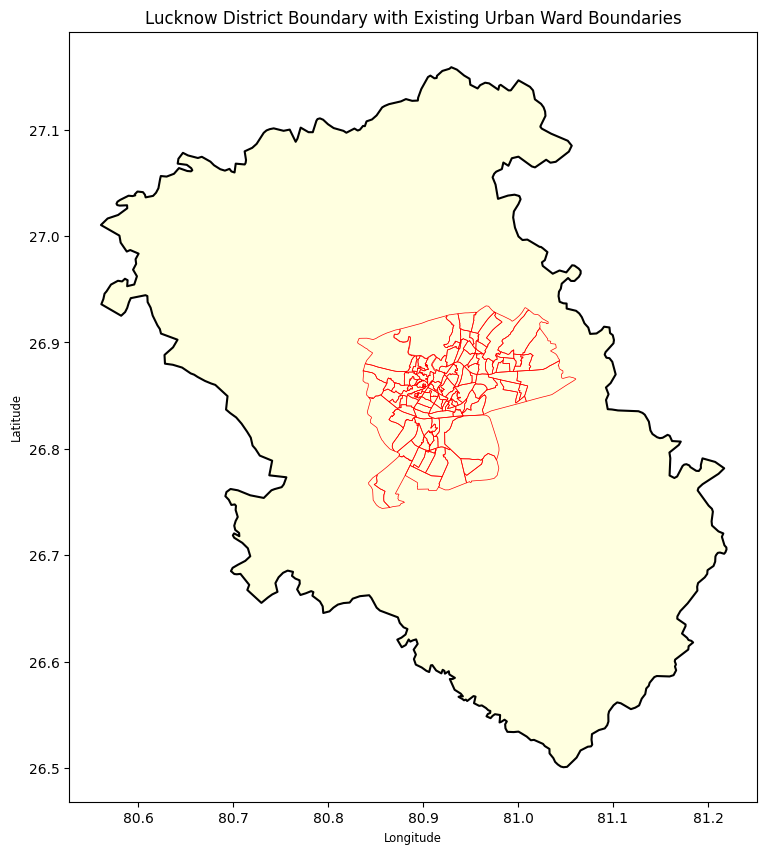

District records: 1
Ward/map units: 111
District CRS: EPSG:4326
Ward CRS: EPSG:4326


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

DISTRICT_SHP = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/2011_Dist.shp"
)
WARD_GPKG = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_map_boundaries_with_demographics.gpkg"
)

districts = gpd.read_file(DISTRICT_SHP)
lucknow_district = districts[
    (districts["DISTRICT"].str.strip().str.lower() == "lucknow") &
    (districts["ST_NM"].str.strip().str.lower() == "uttar pradesh")
].copy()

wards = gpd.read_file(WARD_GPKG, layer="ward_demographics")

# Align coordinate reference systems
if wards.crs != lucknow_district.crs:
    wards = wards.to_crs(lucknow_district.crs)

fig, ax = plt.subplots(figsize=(10, 10))

lucknow_district.plot(
    ax=ax, facecolor="lightyellow",
    edgecolor="black", linewidth=1.5
)
wards.boundary.plot(
    ax=ax, color="red", linewidth=0.5
)

ax.set_title(
    "Lucknow District Boundary with Existing Urban Ward Boundaries"
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

print("District records:", len(lucknow_district))
print("Ward/map units:", len(wards))
print("District CRS:", lucknow_district.crs)
print("Ward CRS:", wards.crs)

In [ ]:
import pandas as pd
import geopandas as gpd

HOSPITAL_CSV = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_hospital_master_cleaned.csv"
)
DISTRICT_SHP = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/2011_Dist.shp"
)

# Load the cleaned hospital inventory
hospitals = pd.read_csv(HOSPITAL_CSV)

# Extract Lucknow district
districts = gpd.read_file(DISTRICT_SHP)

lucknow_district = districts[
    (districts["DISTRICT"].str.strip().str.lower() == "lucknow") &
    (districts["ST_NM"].str.strip().str.lower() == "uttar pradesh")
].copy()

if len(lucknow_district) != 1:
    raise ValueError(
        f"Expected one Lucknow district polygon, found {len(lucknow_district)}"
    )

district_geometry = lucknow_district.geometry.iloc[0]

# Create geographic points from hospital coordinates
hospitals["latitude"] = pd.to_numeric(
    hospitals["latitude"], errors="coerce"
)
hospitals["longitude"] = pd.to_numeric(
    hospitals["longitude"], errors="coerce"
)

valid = hospitals["latitude"].notna() & hospitals["longitude"].notna()

hospitals["inside_lucknow_district"] = False

points = gpd.GeoDataFrame(
    hospitals.loc[valid].copy(),
    geometry=gpd.points_from_xy(
        hospitals.loc[valid, "longitude"],
        hospitals.loc[valid, "latitude"]
    ),
    crs="EPSG:4326"
)

district_geometry = gpd.GeoSeries(
    [district_geometry],
    crs=lucknow_district.crs
).to_crs(points.crs).iloc[0]

hospitals.loc[valid, "inside_lucknow_district"] = (
    points.geometry.apply(district_geometry.covers).to_numpy()
)

# Save the new district-level classification
hospitals.to_csv(HOSPITAL_CSV, index=False)

# Report results
print("=== DISTRICT-LEVEL HOSPITAL CLASSIFICATION ===")
print("Total hospital records:", len(hospitals))
print("\nInside Lucknow district:")
print(hospitals["inside_lucknow_district"].value_counts().to_string())

print("\nComparison with current ward-level plot:")
print(pd.crosstab(
    hospitals["inside_lucknow_district"],
    hospitals["inside_lko_plot"],
    rownames=["Inside district"],
    colnames=["Inside ward plot"],
    dropna=False
).to_string())

print("\nMissing coordinates:", int((~valid).sum()))
print("\nUpdated file:", HOSPITAL_CSV)

=== DISTRICT-LEVEL HOSPITAL CLASSIFICATION ===
Total hospital records: 286

Inside Lucknow district:
inside_lucknow_district
True    286

Comparison with current ward-level plot:
Inside ward plot  False  True 
Inside district               
True                 95    191

Missing coordinates: 0

Updated file: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_hospital_master_cleaned.csv


In [ ]:

import os
import sqlite3
import geopandas as gpd

gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

# Check whether the file exists
if not os.path.exists(gpkg_path):
    raise FileNotFoundError(
        f"File not found: {gpkg_path}\n"
        "Check your Google Drive mount and file location."
    )

print("GeoPackage found.")
print(f"Size: {os.path.getsize(gpkg_path) / (1024**2):.2f} MB")

# List layers directly from the GeoPackage database
with sqlite3.connect(gpkg_path) as conn:
    layers_df = gpd.pd.read_sql_query(
        "SELECT table_name, data_type, srs_id "
        "FROM gpkg_contents",
        conn
    )

print("\nAvailable layers:")
print(layers_df.to_string(index=False))

# Inspect every spatial layer
for layer_name in layers_df["table_name"]:
    try:
        gdf = gpd.read_file(gpkg_path, layer=layer_name)

        print("\n" + "=" * 60)
        print("LAYER:", layer_name)
        print("=" * 60)

        print("Records:", len(gdf))
        print("CRS:", gdf.crs)
        print("Geometry types:", gdf.geom_type.value_counts().to_dict())
        print("Missing geometries:", gdf.geometry.isna().sum())
        print("Empty geometries:", gdf.geometry.is_empty.sum())
        print("Invalid geometries:", (~gdf.geometry.is_valid).sum())
        print("Columns:", gdf.columns.tolist())

        print("\nFirst 3 records:")
        print(gdf.drop(columns="geometry").head(3).to_string(index=False))

    except Exception as e:
        print(f"\nCould not read layer {layer_name}: {e}")

print("\nInspection finished. No files were modified.")


GeoPackage found.
Size: 3.43 MB

Available layers:
               table_name data_type  srs_id
             tehsils_2011  features  100000
villages_towns_shrug_pc11  features  100000
village_points_census2011  features  100000
   villages_lgd_blocks_gp  features  100000

LAYER: tehsils_2011
Records: 4
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]
Geometry types: {'MultiPolygon': 4}
Missing geometries: 0
Empty geometries: 0
Invalid geometries: 0
Columns: ['stcode11', 'dtcode11', 'sdtcode11', 'sdtname', 'Subdt_LGD', 'Dist_LGD', 'pop2011', 'tehsil_name', 'area_km2', 'geometry']

First 3 records:
stcode11 dtcode11 sdtcode11         sdtname  Subdt_LGD  Dist_LGD  pop2011     tehsil_name  area_km2
      09      157     00822   

In [3]:

import geopandas as gpd
import pandas as pd

gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

# Load the primary Census 2011 polygon layer
units = gpd.read_file(
    gpkg_path,
    layer="villages_towns_shrug_pc11"
)

# Load the tehsil boundaries
tehsils = gpd.read_file(
    gpkg_path,
    layer="tehsils_2011"
)

print("=" * 65)
print("1. VILLAGE / TOWN CLASSIFICATION")
print("=" * 65)

print("Total polygons:", len(units))
print("\nClassification counts, including missing values:")
print(units["is_town"].value_counts(dropna=False))

print("\nTown records:")
towns = units[units["is_town"] == True]
print("Count:", len(towns))
print(towns[["pc11_tv_id", "tv_name", "tehsil_name"]].to_string(index=False))

print("\nVillage records:")
villages = units[units["is_town"] == False]
print("Count:", len(villages))

print("\nMissing town/village classifications:",
      units["is_town"].isna().sum())

print("\n" + "=" * 65)
print("2. CENSUS CODE QUALITY")
print("=" * 65)

code_col = "pc11_tv_id"

print("Missing Census codes:", units[code_col].isna().sum())
print("Unique Census codes:", units[code_col].nunique())
print("Duplicate Census codes:",
      units[code_col].duplicated(keep=False).sum())

if units[code_col].duplicated().any():
    print("\nRecords with duplicated Census codes:")
    print(
        units.loc[
            units[code_col].duplicated(keep=False),
            [code_col, "tv_name", "tehsil_name", "is_town"]
        ].sort_values(code_col).to_string(index=False)
    )

print("\n" + "=" * 65)
print("3. POPULATION FIELD")
print("=" * 65)

print("Missing population values:",
      units["pop2011_villagept"].isna().sum())

print("Negative population values:",
      (units["pop2011_villagept"] < 0).sum())

print("\nPopulation summary:")
print(units["pop2011_villagept"].describe())

print("\nPopulation sums by classification:")
print(
    units.groupby("is_town", dropna=False)["pop2011_villagept"]
    .agg(["count", "sum"])
)

print("\n" + "=" * 65)
print("4. TEHSIL SUMMARY")
print("=" * 65)

print(
    tehsils[
        ["sdtcode11", "tehsil_name", "pop2011", "area_km2"]
    ].sort_values("tehsil_name").to_string(index=False)
)

print("\nTotal tehsil population:", tehsils["pop2011"].sum())
print("Total polygon population:",
      units["pop2011_villagept"].sum())

print("\nPolygon counts by tehsil:")
print(units.groupby("tehsil_name").size().sort_index())

print("\nAudit complete. No files were modified.")


1. VILLAGE / TOWN CLASSIFICATION
Total polygons: 819

Classification counts, including missing values:
is_town
False    809
True      10
Name: count, dtype: int64

Town records:
Count: 10
pc11_tv_id         tv_name     tehsil_name
    800955          Nagram    Mohanlalganj
    800953      Gosainganj    Mohanlalganj
    800954          Amethi    Mohanlalganj
    800950          Kakori Lucknow (Sadar)
    800946       Malihabad       Malihabad
    800948         Itaunja Bakshi Ka Talab
    800947          Mahona Bakshi Ka Talab
    800949 Bakshi Ka Talab Bakshi Ka Talab
    800951         Lucknow Lucknow (Sadar)
    800952         Lucknow Lucknow (Sadar)

Village records:
Count: 809

Missing town/village classifications: 0

2. CENSUS CODE QUALITY
Missing Census codes: 0
Unique Census codes: 819
Duplicate Census codes: 0

3. POPULATION FIELD
Missing population values: 11
Negative population values: 0

Population summary:
count      808.000000
mean      1947.198020
std       1826.775835
mi

In [4]:

import geopandas as gpd
import pandas as pd

# Existing district boundary and new GeoPackage
district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)

gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

# Load the existing district boundary
districts = gpd.read_file(district_path)

lucknow_district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].copy()

if len(lucknow_district) != 1:
    raise ValueError(
        f"Expected exactly one Lucknow district polygon; "
        f"found {len(lucknow_district)}."
    )

# Load village/town and tehsil polygons
units = gpd.read_file(
    gpkg_path,
    layer="villages_towns_shrug_pc11"
)

tehsils = gpd.read_file(
    gpkg_path,
    layer="tehsils_2011"
)

# Reproject all layers to a metric CRS
district_m = lucknow_district.to_crs("EPSG:32644")
units_m = units.to_crs("EPSG:32644")
tehsils_m = tehsils.to_crs("EPSG:32644")

# Union the district and administrative polygons
district_geom = district_m.geometry.union_all()
units_union = units_m.geometry.union_all()
tehsils_union = tehsils_m.geometry.union_all()

# Compare coverage without modifying any source geometry
units_inside = units_union.intersection(district_geom)
units_outside = units_union.difference(district_geom)
district_uncovered_by_units = district_geom.difference(units_union)

tehsils_inside = tehsils_union.intersection(district_geom)
tehsils_outside = tehsils_union.difference(district_geom)
district_uncovered_by_tehsils = district_geom.difference(tehsils_union)

def area_km2(geom):
    return geom.area / 1_000_000

district_area = area_km2(district_geom)
unit_union_area = area_km2(units_union)
tehsil_union_area = area_km2(tehsils_union)

print("=" * 65)
print("DISTRICT BOUNDARY COVERAGE AUDIT")
print("=" * 65)

print(f"District area: {district_area:,.2f} km²")

print("\nVillage/town polygons:")
print(f"Feature count: {len(units_m)}")
print(f"Union area: {unit_union_area:,.2f} km²")
print(
    f"District area covered: "
    f"{100 * area_km2(units_inside) / district_area:.2f}%"
)
print(f"Polygon area outside district: {area_km2(units_outside):,.2f} km²")
print(
    f"District area not covered: "
    f"{area_km2(district_uncovered_by_units):,.2f} km²"
)

print("\nTehsil polygons:")
print(f"Feature count: {len(tehsils_m)}")
print(f"Union area: {tehsil_union_area:,.2f} km²")
print(
    f"District area covered: "
    f"{100 * area_km2(tehsils_inside) / district_area:.2f}%"
)
print(f"Tehsil area outside district: {area_km2(tehsils_outside):,.2f} km²")
print(
    f"District area not covered: "
    f"{area_km2(district_uncovered_by_tehsils):,.2f} km²"
)

# Individual polygons that extend beyond the district
outside_areas = units_m.geometry.difference(district_geom).area / 1_000_000
outside_units = units_m.loc[
    outside_areas > 0.01,
    ["pc11_tv_id", "tv_name", "tehsil_name", "is_town"]
].copy()

outside_units["outside_area_km2"] = outside_areas.loc[
    outside_areas > 0.01
].values

print("\nIndividual polygons extending more than 0.01 km² outside:")
print("Count:", len(outside_units))
if len(outside_units):
    print(
        outside_units.sort_values(
            "outside_area_km2", ascending=False
        ).to_string(index=False)
    )

print("\nAudit complete. No source files were modified.")

import geopandas as gpd
import pandas as pd

# Existing district boundary and new GeoPackage
district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)

gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

# Load the existing district boundary
districts = gpd.read_file(district_path)

lucknow_district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].copy()

if len(lucknow_district) != 1:
    raise ValueError(
        f"Expected exactly one Lucknow district polygon; "
        f"found {len(lucknow_district)}."
    )

# Load village/town and tehsil polygons
units = gpd.read_file(
    gpkg_path,
    layer="villages_towns_shrug_pc11"
)

tehsils = gpd.read_file(
    gpkg_path,
    layer="tehsils_2011"
)

# Reproject all layers to a metric CRS
district_m = lucknow_district.to_crs("EPSG:32644")
units_m = units.to_crs("EPSG:32644")
tehsils_m = tehsils.to_crs("EPSG:32644")

# Union the district and administrative polygons
district_geom = district_m.geometry.union_all()
units_union = units_m.geometry.union_all()
tehsils_union = tehsils_m.geometry.union_all()

# Compare coverage without modifying any source geometry
units_inside = units_union.intersection(district_geom)
units_outside = units_union.difference(district_geom)
district_uncovered_by_units = district_geom.difference(units_union)

tehsils_inside = tehsils_union.intersection(district_geom)
tehsils_outside = tehsils_union.difference(district_geom)
district_uncovered_by_tehsils = district_geom.difference(tehsils_union)

def area_km2(geom):
    return geom.area / 1_000_000

district_area = area_km2(district_geom)
unit_union_area = area_km2(units_union)
tehsil_union_area = area_km2(tehsils_union)

print("=" * 65)
print("DISTRICT BOUNDARY COVERAGE AUDIT")
print("=" * 65)

print(f"District area: {district_area:,.2f} km²")

print("\nVillage/town polygons:")
print(f"Feature count: {len(units_m)}")
print(f"Union area: {unit_union_area:,.2f} km²")
print(
    f"District area covered: "
    f"{100 * area_km2(units_inside) / district_area:.2f}%"
)
print(f"Polygon area outside district: {area_km2(units_outside):,.2f} km²")
print(
    f"District area not covered: "
    f"{area_km2(district_uncovered_by_units):,.2f} km²"
)

print("\nTehsil polygons:")
print(f"Feature count: {len(tehsils_m)}")
print(f"Union area: {tehsil_union_area:,.2f} km²")
print(
    f"District area covered: "
    f"{100 * area_km2(tehsils_inside) / district_area:.2f}%"
)
print(f"Tehsil area outside district: {area_km2(tehsils_outside):,.2f} km²")
print(
    f"District area not covered: "
    f"{area_km2(district_uncovered_by_tehsils):,.2f} km²"
)

# Individual polygons that extend beyond the district
outside_areas = units_m.geometry.difference(district_geom).area / 1_000_000
outside_units = units_m.loc[
    outside_areas > 0.01,
    ["pc11_tv_id", "tv_name", "tehsil_name", "is_town"]
].copy()

outside_units["outside_area_km2"] = outside_areas.loc[
    outside_areas > 0.01
].values

print("\nIndividual polygons extending more than 0.01 km² outside:")
print("Count:", len(outside_units))
if len(outside_units):
    print(
        outside_units.sort_values(
            "outside_area_km2", ascending=False
        ).to_string(index=False)
    )

print("\nAudit complete. No source files were modified.")


DISTRICT BOUNDARY COVERAGE AUDIT
District area: 2,537.07 km²

Village/town polygons:
Feature count: 819
Union area: 2,512.60 km²
District area covered: 97.75%
Polygon area outside district: 32.62 km²
District area not covered: 57.09 km²

Tehsil polygons:
Feature count: 4
Union area: 2,528.10 km²
District area covered: 98.90%
Tehsil area outside district: 19.02 km²
District area not covered: 27.99 km²

Individual polygons extending more than 0.01 km² outside:
Count: 83
pc11_tv_id              tv_name     tehsil_name  is_town  outside_area_km2
    143067             Sahijana       Malihabad    False          2.319590
    143075          Mavai Kalan       Malihabad    False          2.227389
    142997      Auntgarhi Saura       Malihabad    False          1.411659
    143640              Ghuskar    Mohanlalganj    False          1.349258
    143016               Badiya       Malihabad    False          1.257142
    143698            Bhadeshwa    Mohanlalganj    False          1.129950
  

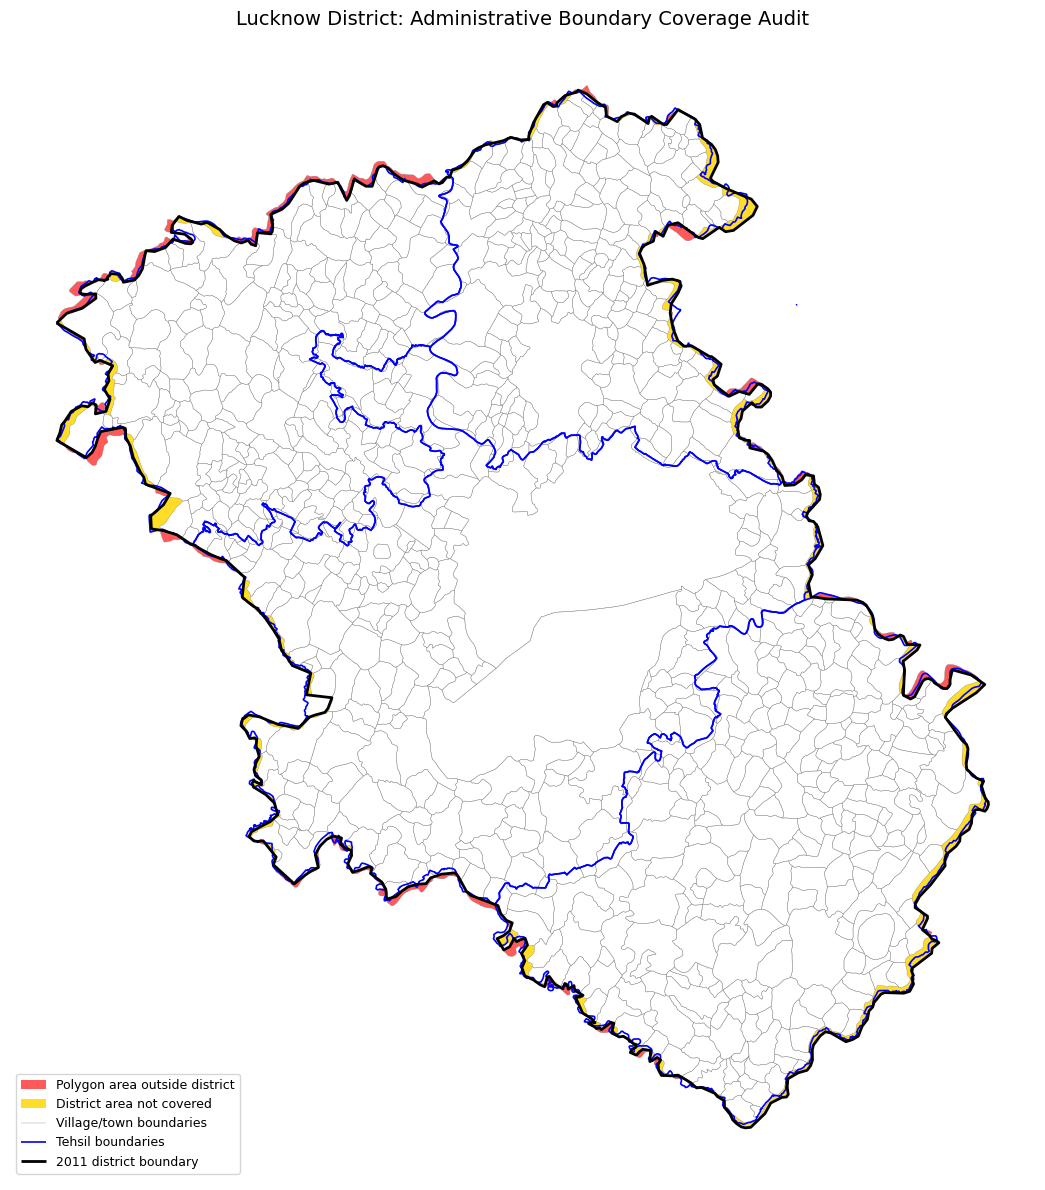

In [5]:

import geopandas as gpd
import matplotlib.pyplot as plt

district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)
gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

# Load the three layers
districts = gpd.read_file(district_path)
district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].copy()

units = gpd.read_file(
    gpkg_path, layer="villages_towns_shrug_pc11"
)
tehsils = gpd.read_file(
    gpkg_path, layer="tehsils_2011"
)

if len(district) != 1:
    raise ValueError(f"Expected one district feature, found {len(district)}")

# Use a metric CRS for spatial comparisons
district = district.to_crs("EPSG:32644")
units = units.to_crs("EPSG:32644")
tehsils = tehsils.to_crs("EPSG:32644")

district_geom = district.geometry.union_all()
units_union = units.geometry.union_all()

outside = units_union.difference(district_geom)
uncovered = district_geom.difference(units_union)

# Draw diagnostic map
fig, ax = plt.subplots(figsize=(12, 12))

# Areas where the village/town polygons extend outside the district
if not outside.is_empty:
    gpd.GeoSeries([outside], crs=units.crs).plot(
        ax=ax, color="red", alpha=0.65,
        label="Polygon area outside district"
    )

# District areas with no village/town polygon coverage
if not uncovered.is_empty:
    gpd.GeoSeries([uncovered], crs=district.crs).plot(
        ax=ax, color="gold", alpha=0.85,
        label="District area not covered"
    )

# Internal village/town boundaries
units.boundary.plot(
    ax=ax, color="grey", linewidth=0.25,
    label="Village/town boundaries"
)

# Tehsil boundaries
tehsils.boundary.plot(
    ax=ax, color="blue", linewidth=1.2,
    label="Tehsil boundaries"
)

# Reference district outline on top
district.boundary.plot(
    ax=ax, color="black", linewidth=2,
    label="2011 district boundary"
)

ax.set_title(
    "Lucknow District: Administrative Boundary Coverage Audit",
    fontsize=14
)
ax.set_axis_off()
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()


In [6]:

import geopandas as gpd
import pandas as pd

district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)

gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

# Load district and village/town boundaries
districts = gpd.read_file(district_path)

district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].copy()

units = gpd.read_file(
    gpkg_path,
    layer="villages_towns_shrug_pc11"
)

if len(district) != 1:
    raise ValueError("Expected exactly one Lucknow district polygon.")

# Project to metres before measuring areas
district = district.to_crs("EPSG:32644")
units = units.to_crs("EPSG:32644")

district_geom = district.geometry.union_all()
units_union = units.geometry.union_all()

# Areas inside the district with no village/town polygon coverage
gap_geom = district_geom.difference(units_union)

if gap_geom.is_empty:
    print("No uncovered areas were found.")
else:
    gaps = gpd.GeoDataFrame(
        {"geometry": list(gap_geom.geoms)
         if gap_geom.geom_type == "MultiPolygon"
         else [gap_geom]},
        geometry="geometry",
        crs=units.crs
    )

    gaps["area_km2"] = gaps.geometry.area / 1_000_000

    # Centroids are used only to summarize approximate locations
    centroids = gaps.geometry.centroid
    centroids_gdf = gpd.GeoSeries(
        centroids, crs=units.crs
    ).to_crs("EPSG:4326")

    gaps["longitude"] = centroids_gdf.x
    gaps["latitude"] = centroids_gdf.y

    gaps = gaps.sort_values(
        "area_km2", ascending=False
    ).reset_index(drop=True)

    print("Number of uncovered components:", len(gaps))
    print(
        "Total uncovered area (km²):",
        round(gaps["area_km2"].sum(), 3)
    )

    print("\nLargest 20 uncovered components:")
    print(
        gaps[["area_km2", "longitude", "latitude"]]
        .head(20)
        .round(5)
        .to_string(index=True)
    )

    print("\nGap area distribution (km²):")
    print(
        gaps["area_km2"].describe().round(3).to_string()
    )


Number of uncovered components: 72
Total uncovered area (km²): 57.091

Largest 20 uncovered components:
    area_km2  longitude  latitude
0    8.61964   81.12350  26.56946
1    6.66775   81.03156  27.09551
2    5.02375   81.19263  26.68044
3    2.39858   80.63712  26.89079
4    2.38603   81.04922  26.95702
5    2.26600   81.20078  26.77491
6    1.81413   81.09538  26.86185
7    1.81087   80.57057  26.94736
8    1.75839   80.59894  26.97118
9    1.63665   81.02329  26.98125
10   1.56748   80.72505  26.80309
11   1.27152   81.09481  26.90159
12   1.26402   80.99513  27.03012
13   1.19805   80.61826  26.92423
14   1.15680   80.89401  26.60800
15   1.11282   81.16140  26.79562
16   0.96868   80.97584  27.05356
17   0.95140   80.70385  26.73251
18   0.89839   80.88000  26.62179
19   0.82893   80.99640  27.00402

Gap area distribution (km²):
count    72.000
mean      0.793
std       1.433
min       0.000
25%       0.071
50%       0.266
75%       0.912
max       8.620


In [7]:

import geopandas as gpd
import pandas as pd

district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)
gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

districts = gpd.read_file(district_path)
district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].to_crs("EPSG:32644")

units = gpd.read_file(
    gpkg_path, layer="villages_towns_shrug_pc11"
).to_crs("EPSG:32644")

tehsils = gpd.read_file(
    gpkg_path, layer="tehsils_2011"
).to_crs("EPSG:32644")

district_geom = district.geometry.union_all()
units_union = units.geometry.union_all()
gap_geom = district_geom.difference(units_union)

# Split uncovered area into separate components
gap_parts = (
    list(gap_geom.geoms)
    if gap_geom.geom_type == "MultiPolygon"
    else [gap_geom]
)

gaps = gpd.GeoDataFrame(
    {"gap_id": range(1, len(gap_parts) + 1),
     "geometry": gap_parts},
    crs=units.crs
)

gaps["area_km2"] = gaps.geometry.area / 1_000_000

# Representative points are guaranteed to lie within each gap
gaps["representative_point"] = gaps.geometry.representative_point()

points = gpd.GeoDataFrame(
    gaps[["gap_id", "area_km2"]].copy(),
    geometry=gaps["representative_point"],
    crs=gaps.crs
)

# Find the tehsil containing each representative point
joined = gpd.sjoin(
    points,
    tehsils[["tehsil_name", "geometry"]],
    how="left",
    predicate="within"
)

# Convert representative points to longitude/latitude
points_ll = points.to_crs("EPSG:4326")
joined["longitude"] = points_ll.geometry.x.values
joined["latitude"] = points_ll.geometry.y.values

print("Gap components:", len(gaps))
print("\nGap area by representative-point tehsil:")
print(
    joined.groupby("tehsil_name", dropna=False)
    .agg(
        components=("gap_id", "count"),
        total_gap_area_km2=("area_km2", "sum"),
        largest_gap_km2=("area_km2", "max")
    )
    .round(3)
    .to_string()
)

print("\nLargest 15 gaps:")
print(
    joined.sort_values("area_km2", ascending=False)[
        ["gap_id", "area_km2", "tehsil_name", "longitude", "latitude"]
    ].head(15).round(5).to_string(index=False)
)

print("\nUnassigned representative points:",
      joined["tehsil_name"].isna().sum())

print("\nNo source files were modified.")


Gap components: 72

Gap area by representative-point tehsil:
                 components  total_gap_area_km2  largest_gap_km2
tehsil_name                                                     
Bakshi Ka Talab          14              15.824            6.668
Lucknow (Sadar)          11               6.615            1.567
Malihabad                12               9.039            2.399
Mohanlalganj             19              22.247            8.620
NaN                      16               3.366            1.814

Largest 15 gaps:
 gap_id  area_km2     tehsil_name  longitude  latitude
      1   8.61964    Mohanlalganj   81.10802  26.56224
     53   6.66775 Bakshi Ka Talab   81.01935  27.10217
     71   5.02375    Mohanlalganj   81.19367  26.68273
     31   2.39858       Malihabad   80.63598  26.89042
     59   2.38603 Bakshi Ka Talab   81.04200  26.95511
     68   2.26600    Mohanlalganj   81.19452  26.77050
     64   1.81413             NaN   81.09335  26.86090
     33   1.81087       Ma

UNCOVERED DISTRICT AREA
Total: 57.091 km²
Within tehsil polygons: 38.157 km²
Outside tehsil polygons: 18.935 km²


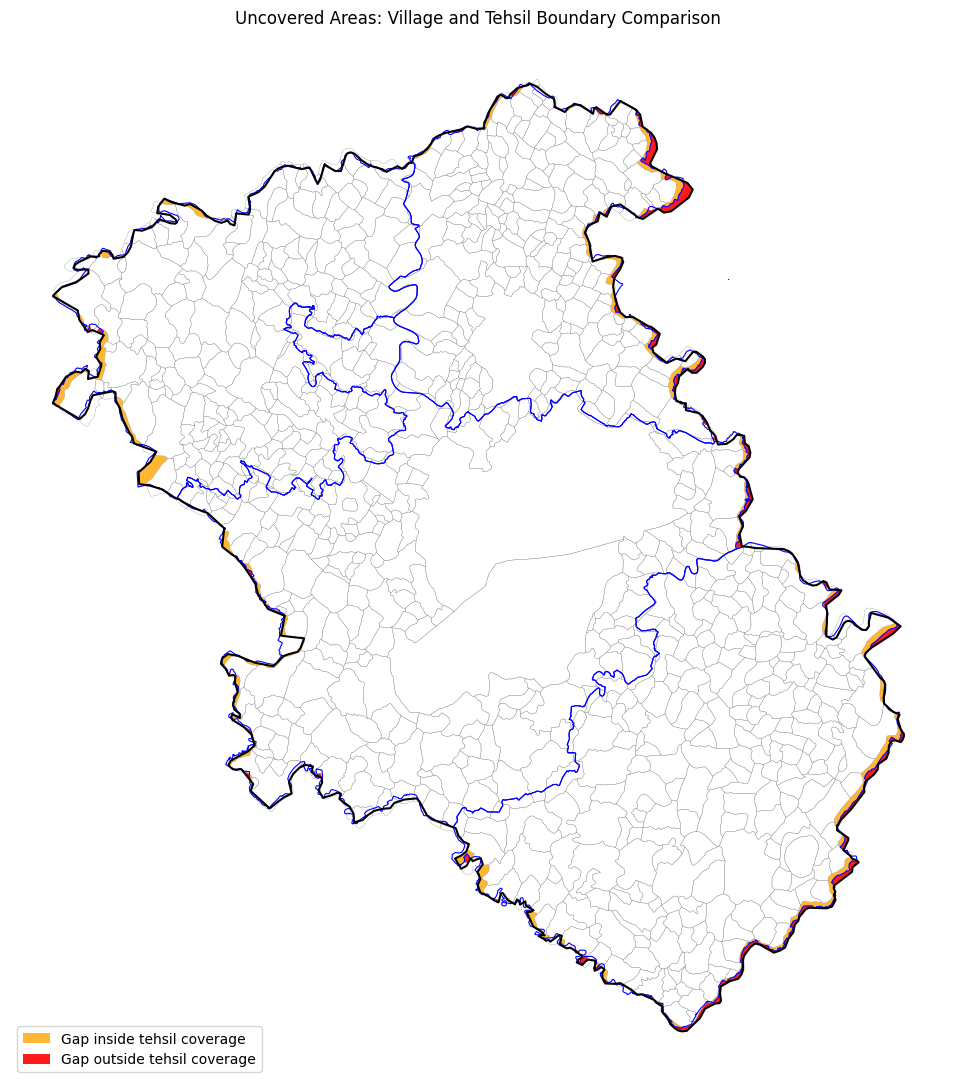


No source files were modified.


In [8]:

import geopandas as gpd
import matplotlib.pyplot as plt

district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)
gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

# Load existing boundaries
districts = gpd.read_file(district_path)
district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].to_crs("EPSG:32644")

units = gpd.read_file(
    gpkg_path, layer="villages_towns_shrug_pc11"
).to_crs("EPSG:32644")

tehsils = gpd.read_file(
    gpkg_path, layer="tehsils_2011"
).to_crs("EPSG:32644")

if len(district) != 1:
    raise ValueError("Expected exactly one Lucknow district polygon.")

district_geom = district.geometry.union_all()
units_union = units.geometry.union_all()
tehsil_union = tehsils.geometry.union_all()

# First find areas inside the district without village/town coverage
gaps_geom = district_geom.difference(units_union)

# Then split these areas according to tehsil coverage
inside_tehsils = gaps_geom.intersection(tehsil_union)
outside_tehsils = gaps_geom.difference(tehsil_union)

def km2(geom):
    return geom.area / 1_000_000

print("UNCOVERED DISTRICT AREA")
print(f"Total: {km2(gaps_geom):.3f} km²")
print(f"Within tehsil polygons: {km2(inside_tehsils):.3f} km²")
print(f"Outside tehsil polygons: {km2(outside_tehsils):.3f} km²")

# Diagnostic visualization
fig, ax = plt.subplots(figsize=(11, 11))

gpd.GeoSeries([inside_tehsils], crs=units.crs).plot(
    ax=ax, color="orange", alpha=0.8,
    label="Gap inside tehsil coverage"
)

gpd.GeoSeries([outside_tehsils], crs=units.crs).plot(
    ax=ax, color="red", alpha=0.9,
    label="Gap outside tehsil coverage"
)

units.boundary.plot(
    ax=ax, color="grey", linewidth=0.2
)

tehsils.boundary.plot(
    ax=ax, color="blue", linewidth=0.8
)

district.boundary.plot(
    ax=ax, color="black", linewidth=1.5
)

ax.set_title("Uncovered Areas: Village and Tehsil Boundary Comparison")
ax.set_axis_off()
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

print("\nNo source files were modified.")


In [9]:

import geopandas as gpd
import pandas as pd

district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)
gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

districts = gpd.read_file(district_path)

district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].to_crs("EPSG:32644")

units = gpd.read_file(
    gpkg_path,
    layer="villages_towns_shrug_pc11"
).to_crs("EPSG:32644")

tehsils = gpd.read_file(
    gpkg_path,
    layer="tehsils_2011"
).to_crs("EPSG:32644")

district_geom = district.geometry.union_all()
units_union = units.geometry.union_all()

gap_geom = district_geom.difference(units_union)
gap_parts = (
    list(gap_geom.geoms)
    if gap_geom.geom_type == "MultiPolygon"
    else [gap_geom]
)

gaps = gpd.GeoDataFrame(
    {"gap_id": range(len(gap_parts)),
     "geometry": gap_parts},
    crs=units.crs
)
gaps["area_km2"] = gaps.geometry.area / 1_000_000

# Select the largest uncovered component
largest = gaps.loc[[gaps["area_km2"].idxmax()]].copy()
largest_geom = largest.geometry.iloc[0]

# Identify village/town polygons within 1 km of this gap
nearby = units[
    units.geometry.distance(largest_geom) <= 1000
].copy()

nearby["distance_to_gap_m"] = nearby.geometry.distance(
    largest_geom
)

print("Largest gap area:", round(largest["area_km2"].iloc[0], 3), "km²")

print("\nNearby administrative polygons (within 1 km):")
print(
    nearby[
        [
            "pc11_tv_id",
            "tv_name",
            "tehsil_name",
            "is_town",
            "distance_to_gap_m"
        ]
    ]
    .sort_values("distance_to_gap_m")
    .head(30)
    .round(2)
    .to_string(index=False)
)

# Check overlap with tehsil boundaries
for _, row in tehsils.iterrows():
    intersection_area = largest_geom.intersection(
        row.geometry
    ).area / 1_000_000

    if intersection_area > 0:
        print(
            f"\nLargest gap overlaps {row['tehsil_name']}: "
            f"{intersection_area:.3f} km²"
        )

print("\nNo source files were modified.")


Largest gap area: 8.62 km²

Nearby administrative polygons (within 1 km):
pc11_tv_id          tv_name  tehsil_name  is_town  distance_to_gap_m
    143756      Aslam Nagar Mohanlalganj    False               0.00
    143758      Abbas Nagar Mohanlalganj    False               0.00
    143759            Garna Mohanlalganj    False               0.00
    143755 Amba Muratajapur Mohanlalganj    False               0.00
    143782     Khuddi Khera Mohanlalganj    False               0.00
    143784  Dakhena Sekhpur Mohanlalganj    False               0.00
    143783         Puraheya Mohanlalganj    False               0.00
    143781          Nadauli Mohanlalganj    False               0.00
    143787       Ramdas Pur Mohanlalganj    False               0.00
    143785         Badhauna Mohanlalganj    False               0.00
    143788          Natauli Mohanlalganj    False               0.00
    143786         Jamoriya Mohanlalganj    False               0.00
    143764           Kaneri M

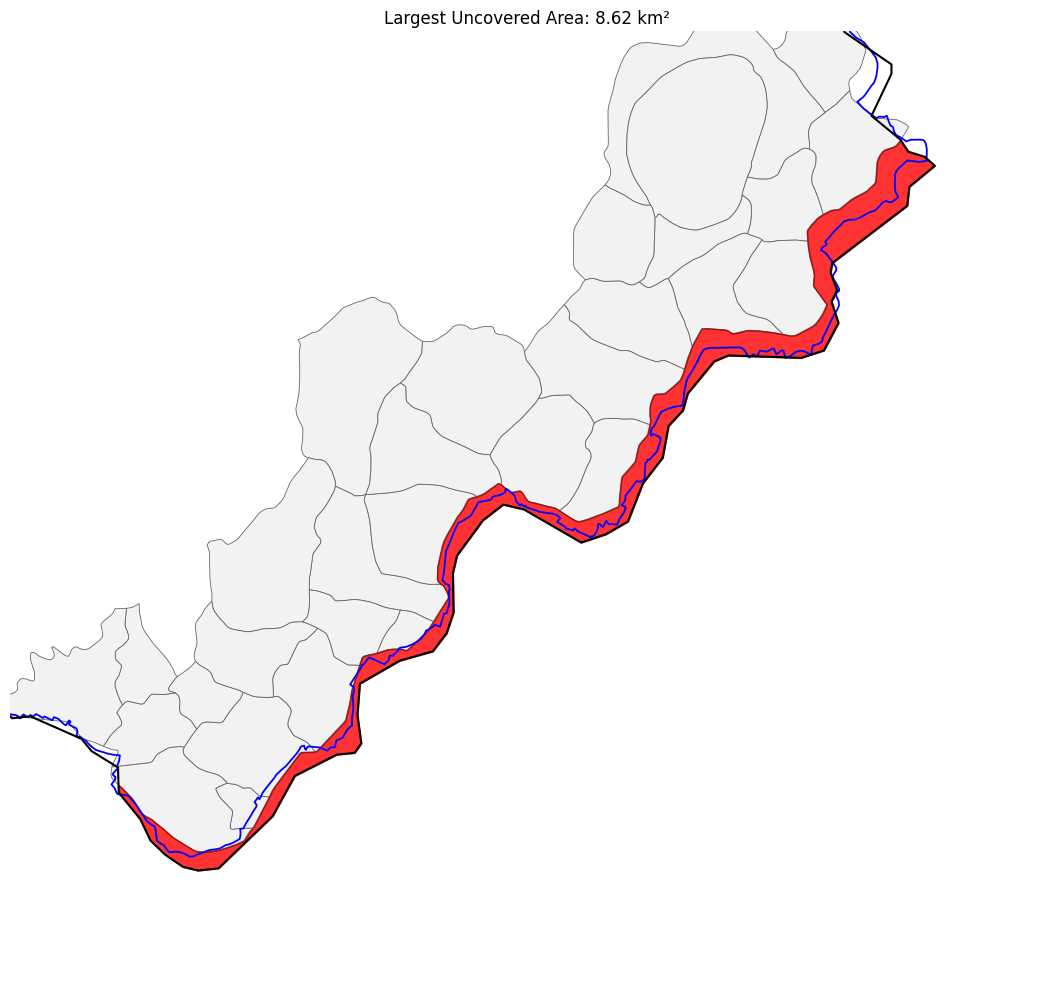

Gap area: 8.62 km²
Nearby village/town polygons: 30
No source files were modified.


In [10]:

import geopandas as gpd
import matplotlib.pyplot as plt

district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)
gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

districts = gpd.read_file(district_path)
district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].to_crs("EPSG:32644")

units = gpd.read_file(
    gpkg_path, layer="villages_towns_shrug_pc11"
).to_crs("EPSG:32644")

tehsils = gpd.read_file(
    gpkg_path, layer="tehsils_2011"
).to_crs("EPSG:32644")

district_geom = district.geometry.union_all()
units_union = units.geometry.union_all()

gap_geom = district_geom.difference(units_union)
gap_parts = (
    list(gap_geom.geoms)
    if gap_geom.geom_type == "MultiPolygon"
    else [gap_geom]
)

gaps = gpd.GeoDataFrame(
    {"area_km2": [g.area / 1_000_000 for g in gap_parts]},
    geometry=gap_parts,
    crs=units.crs
)

largest_gap = gaps.loc[[gaps["area_km2"].idxmax()]]
gap = largest_gap.geometry.iloc[0]

# Show nearby polygons within 2 km
nearby = units[units.geometry.distance(gap) <= 2000].copy()

fig, ax = plt.subplots(figsize=(12, 10))

# Surrounding village polygons
nearby.plot(
    ax=ax, facecolor="#F2F2F2",
    edgecolor="#666666", linewidth=0.6
)

# Tehsil boundaries
tehsils.boundary.plot(
    ax=ax, color="blue", linewidth=1.3
)

# Existing district boundary
district.boundary.plot(
    ax=ax, color="black", linewidth=1.5
)

# Highlight the gap
gpd.GeoSeries([gap], crs=units.crs).plot(
    ax=ax, facecolor="red", edgecolor="darkred",
    alpha=0.8
)

# Zoom to the gap with a 2 km margin
minx, miny, maxx, maxy = gap.bounds
margin = 2000
ax.set_xlim(minx - margin, maxx + margin)
ax.set_ylim(miny - margin, maxy + margin)

ax.set_title(
    f"Largest Uncovered Area: {largest_gap['area_km2'].iloc[0]:.2f} km²"
)
ax.set_axis_off()
plt.tight_layout()
plt.show()

print("Gap area:", round(gap.area / 1_000_000, 3), "km²")
print("Nearby village/town polygons:", len(nearby))
print("No source files were modified.")


In [11]:

import geopandas as gpd
import pandas as pd

district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)
gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

districts = gpd.read_file(district_path)
district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].to_crs("EPSG:32644")

units = gpd.read_file(
    gpkg_path, layer="villages_towns_shrug_pc11"
).to_crs("EPSG:32644")

district_geom = district.geometry.union_all()
units_union = units.geometry.union_all()

gap_geom = district_geom.difference(units_union)

gap_parts = (
    list(gap_geom.geoms)
    if gap_geom.geom_type == "MultiPolygon"
    else [gap_geom]
)

gaps = gpd.GeoDataFrame(
    {"gap_id": range(1, len(gap_parts) + 1)},
    geometry=gap_parts,
    crs=units.crs
)

gaps["area_km2"] = gaps.geometry.area / 1_000_000

# Distance from each gap to the district boundary
district_boundary = district_geom.boundary
gaps["boundary_distance_m"] = gaps.geometry.distance(
    district_boundary
)

# A gap is considered peripheral if it lies within 100 metres
# of the district boundary. This is a diagnostic threshold,
# not an administrative rule.
gaps["gap_type"] = gaps["boundary_distance_m"].apply(
    lambda d: "Peripheral (<=100 m)"
    if d <= 100
    else "Internal (>100 m)"
)

print("Gap classification (100 m diagnostic threshold):")
print(
    gaps.groupby("gap_type").agg(
        components=("gap_id", "count"),
        total_area_km2=("area_km2", "sum"),
        largest_gap_km2=("area_km2", "max")
    ).round(3).to_string()
)

print("\nLargest gaps classified as internal:")
print(
    gaps[gaps["gap_type"] == "Internal (>100 m)"]
    .sort_values("area_km2", ascending=False)[
        ["gap_id", "area_km2", "boundary_distance_m"]
    ]
    .head(15)
    .round(2)
    .to_string(index=False)
)

print("\nNo source files were modified.")


Gap classification (100 m diagnostic threshold):
                      components  total_area_km2  largest_gap_km2
gap_type                                                         
Peripheral (<=100 m)          72          57.091             8.62

Largest gaps classified as internal:
Empty DataFrame
Columns: [gap_id, area_km2, boundary_distance_m]
Index: []

No source files were modified.


In [12]:

import geopandas as gpd
import pandas as pd

gpkg_path = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

units = gpd.read_file(
    gpkg_path,
    layer="villages_towns_shrug_pc11"
).to_crs("EPSG:32644").reset_index(drop=True)

# Spatial index: identify candidate intersecting pairs efficiently
spatial_index = units.sindex
overlaps = []

for i, geom in enumerate(units.geometry):
    candidates = spatial_index.query(
        geom, predicate="intersects"
    )

    for j in candidates:
        j = int(j)

        # Process each pair once; ignore the polygon itself
        if j <= i:
            continue

        intersection = geom.intersection(
            units.geometry.iloc[j]
        )

        # Shared borders have zero area. We only count
        # overlaps with positive interior area.
        overlap_area = intersection.area

        if overlap_area > 100:  # More than 100 m²
            overlaps.append({
                "id_1": units.loc[i, "pc11_tv_id"],
                "name_1": units.loc[i, "tv_name"],
                "id_2": units.loc[j, "pc11_tv_id"],
                "name_2": units.loc[j, "tv_name"],
                "overlap_m2": overlap_area
            })

overlap_df = pd.DataFrame(overlaps)

print("Total village/town polygons:", len(units))
print("Overlapping pairs above 100 m²:", len(overlap_df))

if len(overlap_df):
    print("\nLargest overlaps:")
    print(
        overlap_df.sort_values(
            "overlap_m2", ascending=False
        ).head(20).round(2).to_string(index=False)
    )
else:
    print("No polygon pairs overlap by more than 100 m².")

print("\nNo source files were modified.")


Total village/town polygons: 819
Overlapping pairs above 100 m²: 0
No polygon pairs overlap by more than 100 m².

No source files were modified.


In [15]:

import os
import geopandas as gpd

source_gpkg = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_boundaries.gpkg"
)

district_path = (
    "/content/gdrive/MyDrive/"
    "Lucknow_Census_Raw/2011_Dist.shp"
)

output_gpkg = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_analytical.gpkg"
)

# Protect existing outputs from accidental overwrite
if os.path.exists(output_gpkg):
    raise FileExistsError(
        f"{output_gpkg} already exists. "
        "Do not overwrite it; choose a new output filename."
    )

# Load the source layers
units = gpd.read_file(
    source_gpkg,
    layer="villages_towns_shrug_pc11"
)

tehsils = gpd.read_file(
    source_gpkg,
    layer="tehsils_2011"
)

districts = gpd.read_file(district_path)

district = districts[
    districts["DISTRICT"].astype(str).str.strip().str.lower().eq("lucknow")
    & districts["ST_NM"].astype(str).str.strip().str.lower().eq("uttar pradesh")
].copy()

if len(district) != 1:
    raise ValueError(
        f"Expected one Lucknow district boundary, found {len(district)}."
    )

# Write separate layers in a new GeoPackage.
# Preserve the original source geometries and attributes.
units.to_file(
    output_gpkg,
    layer="villages_towns_2011",
    driver="GPKG"
)

tehsils.to_file(
    output_gpkg,
    layer="tehsils_2011",
    driver="GPKG"
)

district.to_file(
    output_gpkg,
    layer="district_boundary_2011",
    driver="GPKG"
)

print("Created district analytical GeoPackage:")
print(output_gpkg)

print("\nLayer counts:")
print("Village/town polygons:", len(units))
print("Tehsil polygons:", len(tehsils))
print("District boundary:", len(district))

print("\nSource geometries were not clipped or modified.")


Created district analytical GeoPackage:
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_district_analytical.gpkg

Layer counts:
Village/town polygons: 819
Tehsil polygons: 4
District boundary: 1

Source geometries were not clipped or modified.


In [16]:

import os
import geopandas as gpd
import sqlite3

output_gpkg = (
    "/content/gdrive/MyDrive/"
    "lucknow_census_processed/"
    "lucknow_district_analytical.gpkg"
)

if not os.path.exists(output_gpkg):
    raise FileNotFoundError(output_gpkg)

print("File exists:", os.path.exists(output_gpkg))
print(f"File size: {os.path.getsize(output_gpkg) / (1024**2):.2f} MB")

# Inspect saved layer names
with sqlite3.connect(output_gpkg) as conn:
    layer_info = conn.execute(
        """
        SELECT table_name, data_type
        FROM gpkg_contents
        ORDER BY table_name
        """
    ).fetchall()

print("\nSaved layers:")
for name, data_type in layer_info:
    print(f"- {name}: {data_type}")

# Reopen and verify every expected layer
expected_layers = {
    "villages_towns_2011": 819,
    "tehsils_2011": 4,
    "district_boundary_2011": 1
}

for layer_name, expected_count in expected_layers.items():
    gdf = gpd.read_file(output_gpkg, layer=layer_name)

    print(f"\n{layer_name}")
    print("Records:", len(gdf))
    print("CRS:", gdf.crs)
    print("Invalid geometries:", (~gdf.geometry.is_valid).sum())
    print("Missing geometries:", gdf.geometry.isna().sum())
    print("Expected count:", expected_count)

    assert len(gdf) == expected_count, (
        f"Unexpected feature count in {layer_name}"
    )

print("\nVerification completed successfully.")


File exists: True
File size: 1.67 MB

Saved layers:
- district_boundary_2011: features
- tehsils_2011: features
- villages_towns_2011: features

villages_towns_2011
Records: 819
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]
Invalid geometries: 0
Missing geometries: 0
Expected count: 819

tehsils_2011
Records: 4
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]
Invalid geometries: 0
Missing geometries: 0
Expected count: 4

district_boundary_2011
Records: 1
CRS:

In [17]:

import os

folder = "/content/gdrive/MyDrive/lucknow_census_processed"

keywords = [
    "census", "village", "town", "population",
    "pca", "pca_2011", "ward", "rural"
]

print("Existing potentially relevant files:\n")

for filename in sorted(os.listdir(folder)):
    if any(k in filename.lower() for k in keywords):
        path = os.path.join(folder, filename)

        if os.path.isfile(path):
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"{filename}  ({size_mb:.2f} MB)")
        elif os.path.isdir(path):
            print(f"{filename}/  [directory]")


Existing potentially relevant files:

census_appendices_raw_csv/  [directory]
census_validation_report.txt  (0.00 MB)
hamlet_unmatched_village_codes.csv  (0.38 MB)
hospital_ward_spatial_audit.csv  (0.10 MB)
lucknow_cantonment_board_ward_pca_2011.csv  (0.00 MB)
lucknow_municipal_corporation_ward_pca_2011.csv  (0.01 MB)
lucknow_page313_population_column_test.csv  (0.00 MB)
lucknow_urban_pca_alignment_diagnostic.csv  (0.00 MB)
lucknow_urban_pca_cleaned_307_312.csv  (0.01 MB)
lucknow_urban_pca_page313_all_wards.csv  (0.01 MB)
lucknow_urban_pca_page313_ward_population_validation.csv  (0.00 MB)
lucknow_urban_pca_page319_wards46_105.csv  (0.01 MB)
lucknow_urban_pca_preliminary_307_312.csv  (0.01 MB)
lucknow_urban_pca_raw_lines.csv  (0.03 MB)
lucknow_urban_pca_reconstructed_lines_313_318.csv  (0.03 MB)
lucknow_urban_pca_rows_313_318_review.csv  (0.03 MB)
lucknow_urban_pca_source_dash_audit.csv  (0.00 MB)
lucknow_urban_pca_town_ward_mapping.csv  (0.00 MB)
lucknow_urban_pca_town_ward_validation.

In [18]:
import os
import pandas as pd

folder = "/content/gdrive/MyDrive/lucknow_census_processed"

# Existing reports to inspect
report_files = [
    "census_validation_report.txt",
    "village_extraction_report.txt",
]

for filename in report_files:
    path = os.path.join(folder, filename)
    print("\n" + "=" * 80)
    print(f"REPORT: {filename}")
    print("=" * 80)

    if os.path.exists(path):
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            print(f.read())
    else:
        print("File not found.")

# Existing CSVs that can tell us what has already been extracted
csv_files = [
    "village_data_lucknow.csv",
    "village_data_lucknow_selected_v3.csv",
    "town_data_lucknow.csv",
    "village_population_by_cd_block.csv",
    "village_v3_validation_report.csv",
    "village_field_audit.csv",
]

for filename in csv_files:
    path = os.path.join(folder, filename)

    print("\n" + "=" * 80)
    print(f"CSV: {filename}")
    print("=" * 80)

    if not os.path.exists(path):
        print("File not found.")
        continue

    df = pd.read_csv(path, low_memory=False)

    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Column names:")
    print(df.columns.tolist())
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))


REPORT: census_validation_report.txt

FILE: village_data_lucknow.csv
Rows: 807
District codes: ['157']
District names: ['Lucknow']
Duplicate key occurrences (approximate): 0
Columns: 396
Sample columns: State Code, State Name, District Code, District Name, Sub District Code, Sub District Name, Village Code, Village Name, CD Block Code, CD Block Name, Gram Panchayat Code, Gram Panchayat Name, Reference Year, Sub District Head Quarter (Name), Sub District Head Quarter (Distance in km), District Head Quarter  (Name), District Head Quarter  (Distance in km), Nearest Statutory Town  (Name), Nearest Statutory Town (Distance in km), Within the State/UT (Name)
Highest sample missingness:
Outside the State/UT distance, if nearest one is not within the State/UT (Distance in km)    0.995043
Spring Functioning All round the year (Status A(1)/NA(2))                                    0.992565
Spring Functioning in Summer months (April-September) (Status A(1)/NA(2))                    0.992565
Othe

In [19]:
import os
import pandas as pd

folder = "/content/gdrive/MyDrive/lucknow_census_processed"

village_path = os.path.join(folder, "village_data_lucknow.csv")
selected_path = os.path.join(folder, "village_data_lucknow_selected_v3.csv")
town_path = os.path.join(folder, "town_data_lucknow.csv")

villages = pd.read_csv(village_path, low_memory=False)
selected = pd.read_csv(selected_path, low_memory=False)
towns = pd.read_csv(town_path, low_memory=False)

# 1. Village coverage and population
print("=" * 65)
print("VILLAGE DATA COVERAGE")
print("=" * 65)

print("Village records:", len(villages))
print("Unique village codes:", villages["Village Code"].nunique())
print("Duplicate village codes:",
      villages["Village Code"].duplicated().sum())
print("Missing village codes:", villages["Village Code"].isna().sum())

pop_col = "Total Population of Village"
house_col = "Total   Households "

for col in [pop_col, house_col]:
    villages[col] = pd.to_numeric(villages[col], errors="coerce")

print("Missing village population:", villages[pop_col].isna().sum())
print("Village population total:", villages[pop_col].sum())
print("Missing household counts:", villages[house_col].isna().sum())
print("Household total:", villages[house_col].sum())

print("\nPopulation by sub-district / tehsil:")
print(
    villages.groupby("Sub District Name", dropna=False)
    .agg(
        village_records=("Village Code", "size"),
        unique_villages=("Village Code", "nunique"),
        population=(pop_col, "sum"),
        missing_population=(pop_col, lambda x: x.isna().sum())
    )
    .to_string()
)

# 2. Check selected dataset consistency
print("\n" + "=" * 65)
print("SELECTED VILLAGE DATASET")
print("=" * 65)

print("Selected rows:", len(selected))
print("Selected unique village codes:",
      selected["Village Code"].nunique())
print("Selected duplicate village codes:",
      selected["Village Code"].duplicated().sum())

raw_codes = set(villages["Village Code"].dropna().astype(str).str.strip())
selected_codes = set(selected["Village Code"].dropna().astype(str).str.strip())

print("Codes in raw but not selected:", len(raw_codes - selected_codes))
print("Codes in selected but not raw:", len(selected_codes - raw_codes))

# 3. Town coverage and population
print("\n" + "=" * 65)
print("TOWN DATA")
print("=" * 65)

print("Town records:", len(towns))
print("Town columns:", towns.columns.tolist())

town_code_col = "Town Code"
town_pop_col = "Total Population of Town"

if town_code_col in towns.columns:
    print("Unique town codes:", towns[town_code_col].nunique())
    print("Duplicate town codes:", towns[town_code_col].duplicated().sum())

if town_pop_col in towns.columns:
    towns[town_pop_col] = pd.to_numeric(
        towns[town_pop_col], errors="coerce"
    )
    print("Missing town population:", towns[town_pop_col].isna().sum())
    print("Town population total:", towns[town_pop_col].sum())

    display_cols = [
        c for c in [
            "Sub District Name", "Town Code", "Town Name",
            "Total Households ", "Total   Households ",
            "Total Population of Town",
            "Total Male Population of Town",
            "Total Female Population of Town"
        ] if c in towns.columns
    ]
    print("\nTown population records:")
    print(towns[display_cols].to_string(index=False))

VILLAGE DATA COVERAGE
Village records: 807
Unique village codes: 807
Duplicate village codes: 0
Missing village codes: 0
Missing village population: 0
Village population total: 1550842
Missing household counts: 4
Household total: 283193.0

Population by sub-district / tehsil:
                   village_records  unique_villages  population  missing_population
Sub District Name                                                                  
Bakshi Ka Talab                186              186      284626                   0
Lucknow                        205              205      468885                   0
Malihabad                      187              187      350635                   0
Mohanlalganj                   229              229      446696                   0

SELECTED VILLAGE DATASET
Selected rows: 807
Selected unique village codes: 807
Selected duplicate village codes: 0
Codes in raw but not selected: 0
Codes in selected but not raw: 0

TOWN DATA
Town records: 12
Town colu

In [20]:
import os
import pandas as pd
import geopandas as gpd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

village_path = os.path.join(base, "village_data_lucknow.csv")
town_path = os.path.join(base, "town_data_lucknow.csv")
gpkg_path = os.path.join(base, "lucknow_district_analytical.gpkg")

villages = pd.read_csv(village_path, low_memory=False)
towns = pd.read_csv(town_path, low_memory=False)
spatial = gpd.read_file(
    gpkg_path,
    layer="villages_towns_2011"
)

# Normalize Census codes for comparison.
def normalize_code(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

villages["code_check"] = normalize_code(villages["Village Code"])
towns["code_check"] = normalize_code(towns["Town Code"])
spatial["code_check"] = normalize_code(spatial["pc11_tv_id"])

village_codes = set(villages["code_check"].dropna())
town_codes = set(towns["code_check"].dropna())

spatial_villages = spatial[
    spatial["is_town"].astype(str).str.lower().isin(["false", "0"])
]
spatial_towns = spatial[
    spatial["is_town"].astype(str).str.lower().isin(["true", "1"])
]

spatial_village_codes = set(
    spatial_villages["code_check"].dropna()
)
spatial_town_codes = set(
    spatial_towns["code_check"].dropna()
)

# Convert populations to numeric values.
village_pop = pd.to_numeric(
    villages["Total Population of Village"],
    errors="coerce"
).sum()

town_pop = pd.to_numeric(
    towns["Total Population of Town"],
    errors="coerce"
).sum()

print("=" * 65)
print("POPULATION TOTALS")
print("=" * 65)
print(f"Village population: {village_pop:,.0f}")
print(f"Town population:    {town_pop:,.0f}")
print(f"Combined:           {village_pop + town_pop:,.0f}")

print("\n" + "=" * 65)
print("VILLAGE CODE COVERAGE")
print("=" * 65)
print("Extracted village codes:", len(village_codes))
print("Spatial village codes:", len(spatial_village_codes))
print("Extracted codes absent from spatial layer:",
      len(village_codes - spatial_village_codes))
print("Spatial codes absent from extracted directory:",
      len(spatial_village_codes - village_codes))

print("\nCodes in directory but absent from spatial layer:")
print(sorted(village_codes - spatial_village_codes))

print("\nCodes in spatial layer but absent from directory:")
print(sorted(spatial_village_codes - village_codes))

print("\n" + "=" * 65)
print("TOWN CODE COVERAGE")
print("=" * 65)
print("Extracted town codes:", len(town_codes))
print("Spatial town codes:", len(spatial_town_codes))
print("Town codes absent from spatial layer:",
      len(town_codes - spatial_town_codes))
print("Spatial town codes absent from directory:",
      len(spatial_town_codes - town_codes))

print("\nTown codes absent from spatial layer:")
print(sorted(town_codes - spatial_town_codes))

print("\nSpatial town codes absent from directory:")
print(sorted(spatial_town_codes - town_codes))

POPULATION TOTALS
Village population: 1,550,842
Town population:    3,038,996
Combined:           4,589,838

VILLAGE CODE COVERAGE
Extracted village codes: 807
Spatial village codes: 809
Extracted codes absent from spatial layer: 0
Spatial codes absent from extracted directory: 2

Codes in directory but absent from spatial layer:
[]

Codes in spatial layer but absent from directory:
['143558', '143559']

TOWN CODE COVERAGE
Extracted town codes: 12
Spatial town codes: 10
Town codes absent from spatial layer: 2
Spatial town codes absent from directory: 0

Town codes absent from spatial layer:
['143558', '143559']

Spatial town codes absent from directory:
[]


In [21]:
import os
import pandas as pd
import geopandas as gpd
import sqlite3

gpkg_path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_district_analytical.gpkg"
)

layer = "villages_towns_2011"
census_town_codes = {"143558", "143559"}

# Read and inspect the two records before making changes.
gdf = gpd.read_file(gpkg_path, layer=layer)

gdf["code_check"] = (
    gdf["pc11_tv_id"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

matches = gdf[gdf["code_check"].isin(census_town_codes)]

print("Records found:", len(matches))
print(matches[["pc11_tv_id", "tv_name", "is_town"]].to_string(index=False))

if len(matches) != 2:
    raise ValueError(
        "Expected exactly two records for Census Town codes "
        "143558 and 143559. No changes made."
    )

# Update only the town classification.
gdf.loc[gdf["code_check"].isin(census_town_codes), "is_town"] = True
gdf = gdf.drop(columns=["code_check"])

# Write the corrected working layer to a temporary layer first.
temp_layer = "villages_towns_2011_corrected"

gdf.to_file(
    gpkg_path,
    layer=temp_layer,
    driver="GPKG"
)

# Verify the written layer before replacing the original working layer.
check = gpd.read_file(gpkg_path, layer=temp_layer)
check["code_check"] = (
    check["pc11_tv_id"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

print("\nCorrected classification:")
print(
    check[check["code_check"].isin(census_town_codes)][
        ["pc11_tv_id", "tv_name", "is_town"]
    ].to_string(index=False)
)

print("\nTown count:", int(check["is_town"].astype(bool).sum()))
print("Total records:", len(check))

# Replace the working layer only after verification.
with sqlite3.connect(gpkg_path) as conn:
    conn.execute(f'DROP TABLE "{layer}"')
    conn.execute(
        f'ALTER TABLE "{temp_layer}" RENAME TO "{layer}"'
    )

print("\nWorking layer updated successfully.")

Records found: 2
pc11_tv_id        tv_name  is_town
    143559       Sarsawan    False
    143558 Kalli Pashchim    False

Corrected classification:
pc11_tv_id        tv_name  is_town
    143559       Sarsawan     True
    143558 Kalli Pashchim     True

Town count: 12
Total records: 819

Working layer updated successfully.


In [22]:
import os
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

# Inspect available district-level and Census validation files.
for filename in [
    "census_validation_report.txt",
    "village_population_by_cd_block.csv",
    "town_data_lucknow.csv",
    "village_data_lucknow.csv",
]:
    path = os.path.join(base, filename)

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    if not os.path.exists(path):
        print("File not found")
        continue

    if filename.endswith(".txt"):
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            print(f.read()[:10000])
        continue

    df = pd.read_csv(path, low_memory=False)

    if filename == "village_population_by_cd_block.csv":
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.to_string(index=False))
        continue

    # Print only relevant population and identification columns.
    relevant = [
        c for c in df.columns
        if any(term in c.lower() for term in [
            "district", "sub district", "tehsil", "town code",
            "town name", "village code", "village name",
            "population", "household"
        ])
    ]

    print("Rows:", len(df))
    print("Relevant columns:", relevant)

    if filename == "town_data_lucknow.csv":
        print(df[relevant].to_string(index=False))
    else:
        print(df[relevant].head(5).to_string(index=False))


census_validation_report.txt

FILE: village_data_lucknow.csv
Rows: 807
District codes: ['157']
District names: ['Lucknow']
Duplicate key occurrences (approximate): 0
Columns: 396
Sample columns: State Code, State Name, District Code, District Name, Sub District Code, Sub District Name, Village Code, Village Name, CD Block Code, CD Block Name, Gram Panchayat Code, Gram Panchayat Name, Reference Year, Sub District Head Quarter (Name), Sub District Head Quarter (Distance in km), District Head Quarter  (Name), District Head Quarter  (Distance in km), Nearest Statutory Town  (Name), Nearest Statutory Town (Distance in km), Within the State/UT (Name)
Highest sample missingness:
Outside the State/UT distance, if nearest one is not within the State/UT (Distance in km)    0.995043
Spring Functioning All round the year (Status A(1)/NA(2))                                    0.992565
Spring Functioning in Summer months (April-September) (Status A(1)/NA(2))                    0.992565
Others Funct

In [23]:
import os
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

villages = pd.read_csv(
    os.path.join(base, "village_data_lucknow.csv"),
    low_memory=False
)
towns = pd.read_csv(
    os.path.join(base, "town_data_lucknow.csv"),
    low_memory=False
)

def total(df, col):
    return pd.to_numeric(df[col], errors="coerce").sum()

checks = [
    ("Village population",
     villages, "Total Population of Village", 1_550_842),
    ("Village male population",
     villages, "Total Male Population of Village", None),
    ("Village female population",
     villages, "Total Female Population of Village", None),
    ("Village SC population",
     villages, "Total Scheduled Castes Population of Village", None),
    ("Village ST population",
     villages, "Total Scheduled Tribes Population of Village", None),
    ("Town population",
     towns, "Total Population of Town", 3_038_996),
    ("Town male population",
     towns, "Total Male Population of Town", None),
    ("Town female population",
     towns, "Total Female Population of Town", None),
    ("Town SC population",
     towns, "Total Scheduled Castes Population of Town", None),
    ("Town ST population",
     towns, "Total Scheduled Tribes Population of Town", None),
]

print(f"{'Metric':35s} {'Total':>15s} {'Missing':>10s}")
print("-" * 62)

for label, df, col, expected in checks:
    values = pd.to_numeric(df[col], errors="coerce")
    observed = values.sum()
    missing = values.isna().sum()

    print(f"{label:35s} {observed:15,.0f} {missing:10d}")

    if expected is not None:
        print(f"  Expected: {expected:,} | Match: {observed == expected}")

print("\nDistrict sex totals calculated from village + town data:")
male = total(villages, "Total Male Population of Village") + \
       total(towns, "Total Male Population of Town")
female = total(villages, "Total Female Population of Village") + \
         total(towns, "Total Female Population of Town")

print("Male:", f"{male:,.0f}", "| Official reference: 2,394,476")
print("Female:", f"{female:,.0f}", "| Official reference: 2,195,362")
print("Combined:", f"{male + female:,.0f}")

Metric                                        Total    Missing
--------------------------------------------------------------
Village population                        1,550,842          0
  Expected: 1,550,842 | Match: True
Village male population                     813,752          4
Village female population                   737,090          4
Village SC population                       597,272          4
Village ST population                         1,008          4
Town population                           3,038,996          0
  Expected: 3,038,996 | Match: True
Town male population                      1,580,724          0
Town female population                    1,458,272          0
Town SC population                          351,022          0
Town ST population                            6,498          0

District sex totals calculated from village + town data:
Male: 2,394,476 | Official reference: 2,394,476
Female: 2,195,362 | Official reference: 2,195,362
Combined: 4,589,

In [24]:
import os
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"
path = os.path.join(base, "village_data_lucknow.csv")

df = pd.read_csv(path, low_memory=False)

demographic_cols = [
    "Total Population of Village",
    "Total Male Population of Village",
    "Total Female Population of Village",
    "Total Scheduled Castes Population of Village",
    "Total Scheduled Tribes Population of Village",
]

# Convert columns to numeric for reliable missing-value checks.
for col in demographic_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

missing_mask = df[demographic_cols].isna().any(axis=1)

print("Villages with one or more missing demographic values:",
      int(missing_mask.sum()))

cols_to_show = [
    "Sub District Name",
    "Village Code",
    "Village Name",
    *demographic_cols,
]

print("\nAffected village records:")
print(
    df.loc[missing_mask, cols_to_show]
      .to_string(index=False)
)

print("\nMissing-value count by demographic field:")
print(df[demographic_cols].isna().sum().to_string())

Villages with one or more missing demographic values: 4

Affected village records:
Sub District Name  Village Code Village Name  Total Population of Village  Total Male Population of Village  Total Female Population of Village  Total Scheduled Castes Population of Village  Total Scheduled Tribes Population of Village
        Malihabad        143080 Raghu Rampur                            0                               NaN                                 NaN                                           NaN                                           NaN
        Malihabad        143152    Sahilabad                            0                               NaN                                 NaN                                           NaN                                           NaN
  Bakshi Ka Talab        143248   Prithvipur                            0                               NaN                                 NaN                                           NaN                    

In [25]:
import os
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"
path = os.path.join(base, "village_data_lucknow.csv")

df = pd.read_csv(path, low_memory=False)

target_codes = ["143080", "143152", "143248", "143356"]

df["Village Code"] = (
    df["Village Code"].astype(str).str.replace(r"\.0$", "", regex=True)
)

affected = df[df["Village Code"].isin(target_codes)].copy()

# Show fields that could help establish settlement/population status.
keywords = [
    "village code", "village name", "sub district", "cd block",
    "household", "population", "reference year", "status",
    "inhabited", "uninhabited", "location", "area"
]

selected_cols = [
    col for col in affected.columns
    if any(term in col.lower() for term in keywords)
]

print("Source records:", len(affected))
print("Relevant source fields:", selected_cols)

print("\nAffected records:")
print(affected[selected_cols].T.to_string())

print("\nFull list of columns containing status or habitation terms:")
print([
    col for col in df.columns
    if any(term in col.lower()
           for term in ["status", "inhabited", "uninhabited"])
])

Source records: 4
Relevant source fields: ['Sub District Code', 'Sub District Name', 'Village Code', 'Village Name', 'CD Block Code', 'CD Block Name', 'Reference Year', 'Sub District Head Quarter (Name)', 'Sub District Head Quarter (Distance in km)', 'Total Geographical Area (in Hectares)', 'Total   Households ', 'Total Population of Village', 'Total Male Population of Village', 'Total Female Population of Village', 'Total Scheduled Castes Population of Village', 'Total Scheduled Castes  Male Population of Village', 'Total Scheduled Castes  Female Population of Village', 'Total Scheduled Tribes Population of Village', 'Total Scheduled Tribes  Male Population of Village', 'Total Scheduled Tribes  Female Population of Village', 'Govt Pre-Primary School (Nursery/LKG/UKG) (Status A(1)/NA(2))', 'Private Pre - Primary School (Nursery/LKG/UKG) (Status A(1)/NA(2))', 'Nearest Facility Status (Govt(1)/Private(2)) ', 'Govt Primary School (Status A(1)/NA(2))', 'Private Primary School (Status A(1)/

In [26]:
import os
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"
path = os.path.join(base, "village_data_lucknow.csv")

df = pd.read_csv(path, low_memory=False)

# Identify columns related to healthcare and medical facilities.
keywords = [
    "health", "hospital", "medical", "dispensary",
    "primary health", "community health", "sub-centre",
    "sub centre", "subcentre", "doctor", "nursing",
    "maternity", "family welfare", "ambulance", "asha",
    "bed", "para medical", "paramedical"
]

health_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in keywords)
]

print("Total village records:", len(df))
print("Healthcare-related columns found:", len(health_cols))
print("\nHEALTHCARE COLUMN AUDIT")
print("=" * 90)

audit = pd.DataFrame({
    "Column": health_cols,
    "Non_missing": [df[col].notna().sum() for col in health_cols],
    "Missing": [df[col].isna().sum() for col in health_cols],
    "Unique_values": [df[col].nunique(dropna=True) for col in health_cols],
    "Sample_values": [
        df[col].dropna().astype(str).unique()[:5].tolist()
        for col in health_cols
    ]
})

print(audit.to_string(index=False))

# Save the report separately; the source dataset remains unchanged.
output_path = os.path.join(
    base, "village_healthcare_column_audit.csv"
)
audit.to_csv(output_path, index=False)

print("\nAudit saved to:", output_path)

Total village records: 807
Healthcare-related columns found: 63

HEALTHCARE COLUMN AUDIT
                                                                                 Column  Non_missing  Missing  Unique_values              Sample_values
                                                      Community Health Centre (Numbers)          803        4              2                 [0.0, 1.0]
                               Community Health Centre Doctors Total Strength (Numbers)          788       19              4       [0.0, 1.0, 5.0, 3.0]
                                  Community Health Centre Doctors In Position (Numbers)          786       21              4       [0.0, 1.0, 3.0, 2.0]
                   Community Health Centre Para Medical  Staff Total Strength (Numbers)          785       22              4       [0.0, 5.0, 4.0, 1.0]
                       Community Health Centre Para Medical Staff In Position (Numbers)          785       22              5  [0.0, 5.0, 2.0, 4.0, 1.0]

In [27]:

import os
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"
path = os.path.join(base, "village_data_lucknow.csv")

df = pd.read_csv(path, low_memory=False)

# Main facility-count indicators
facility_cols = [
    "Primary Health Centre (Numbers)",
    "Community Health Centre (Numbers)",
    "Primary Heallth Sub Centre (Numbers)",
    "Hospital Allopathic (Numbers)",
    "Maternity And Child Welfare Centre (Numbers)",
    "Dispensary (Numbers)",
    "Mobile Health Clinic (Numbers)",
    "Family Welfare Centre (Numbers)",
]

print("RURAL HEALTHCARE FACILITY SUMMARY")
print("=" * 85)

summary = []

for col in facility_cols:
    if col not in df.columns:
        print(f"Column not found: {col}")
        continue

    values = pd.to_numeric(df[col], errors="coerce")

    summary.append({
        "Facility": col,
        "Reported_total": values.sum(min_count=1),
        "Villages_reporting": values.notna().sum(),
        "Villages_with_one_or_more": (values > 0).sum(),
        "Villages_reporting_zero": (values == 0).sum(),
        "Missing": values.isna().sum()
    })

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

output_path = os.path.join(
    base, "rural_healthcare_facility_summary.csv"
)
summary_df.to_csv(output_path, index=False)

print("\nSummary saved to:", output_path)


RURAL HEALTHCARE FACILITY SUMMARY
                                    Facility  Reported_total  Villages_reporting  Villages_with_one_or_more  Villages_reporting_zero  Missing
             Primary Health Centre (Numbers)            20.0                 803                         20                      783        4
           Community Health Centre (Numbers)             3.0                 803                          3                      800        4
        Primary Heallth Sub Centre (Numbers)            53.0                 790                         53                      737       17
               Hospital Allopathic (Numbers)            13.0                 777                         12                      765       30
Maternity And Child Welfare Centre (Numbers)            38.0                 787                         38                      749       20
                        Dispensary (Numbers)            22.0                 777                         18       

In [28]:

import os
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"
path = os.path.join(base, "village_data_lucknow.csv")

df = pd.read_csv(path, low_memory=False)

facility_cols = {
    "PHC": "Primary Health Centre (Numbers)",
    "CHC": "Community Health Centre (Numbers)",
    "Sub-centre": "Primary Heallth Sub Centre (Numbers)",
    "Allopathic hospital": "Hospital Allopathic (Numbers)"
}

# Find likely Census village identity columns
identity_candidates = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "village code", "village name", "town/village",
        "village or town", "subdistrict", "cd block"
    ])
]

print("POTENTIAL VILLAGE IDENTIFIER COLUMNS")
for col in identity_candidates:
    print("-", col)

# Keep available identity fields and selected facility counts
identity_cols = [
    col for col in identity_candidates
    if any(term in col.lower() for term in [
        "village code", "village name", "subdistrict", "cd block"
    ])
]

available_facilities = {
    label: col for label, col in facility_cols.items()
    if col in df.columns
}

result = df[identity_cols].copy()

for label, col in available_facilities.items():
    result[label] = pd.to_numeric(df[col], errors="coerce")

print("\nVILLAGES REPORTING FACILITIES")
print("=" * 85)

for label in available_facilities:
    mask = result[label] > 0
    print(f"\n{label}: {int(mask.sum())} villages reporting one or more")
    print(result.loc[mask, identity_cols + [label]].to_string(index=False))

out_path = os.path.join(
    base, "villages_reporting_key_health_facilities.csv"
)
result.to_csv(out_path, index=False)

print("\nSaved to:", out_path)


POTENTIAL VILLAGE IDENTIFIER COLUMNS
- Village Code
- Village Name
- CD Block Code
- CD Block Name

VILLAGES REPORTING FACILITIES

PHC: 20 villages reporting one or more
 Village Code    Village Name  CD Block Code   CD Block Name  PHC
       143052            Mall            294             Mal  1.0
       143085          Kahala            295       Malihabad  1.0
       143157    Kasmandikala            295       Malihabad  1.0
       143211     Bhikharipur            296 Bakshi-Ka-Talab  1.0
       143266        Kathwara            296 Bakshi-Ka-Talab  1.0
       143335     Poorab Gaon            297         Chinhat  1.0
       143395        Baragoan            298          Kakori  1.0
       143453           Jugor            297         Chinhat  1.0
       143477           Behta            299   Sarojaninagar  1.0
       143496          Haroni            299   Sarojaninagar  1.0
       143524      Chandraval            299   Sarojaninagar  1.0
       143636        Fatehpur         

In [29]:

import os
import geopandas as gpd
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

csv_path = os.path.join(base, "village_data_lucknow.csv")
gpkg_path = os.path.join(base, "lucknow_district_analytical.gpkg")

villages = pd.read_csv(csv_path, low_memory=False)
boundaries = gpd.read_file(
    gpkg_path,
    layer="villages_towns_2011"
)

print("CSV village records:", len(villages))
print("GIS village/town polygons:", len(boundaries))

print("\nCSV identity fields:")
print(villages[["Village Code", "Village Name"]].head().to_string(index=False))

print("\nGIS identity fields:")
print(boundaries[
    ["pc11_tv_id", "tv_name", "is_town"]
].head().to_string(index=False))

# Compare codes as strings to avoid integer/string formatting mismatches.
csv_codes = set(
    villages["Village Code"].dropna().astype(str).str.strip()
)
gis_codes = set(
    boundaries["pc11_tv_id"].dropna().astype(str).str.strip()
)

print("\nUnique CSV village codes:", len(csv_codes))
print("Unique GIS settlement codes:", len(gis_codes))
print("CSV codes also present in GIS:", len(csv_codes & gis_codes))
print("CSV codes absent from GIS:", len(csv_codes - gis_codes))
print("GIS codes absent from CSV:", len(gis_codes - csv_codes))

print("\nExamples of CSV codes absent from GIS:")
print(sorted(csv_codes - gis_codes)[:20])

print("\nExamples of GIS codes absent from CSV:")
print(sorted(gis_codes - csv_codes)[:20])


CSV village records: 807
GIS village/town polygons: 819

CSV identity fields:
 Village Code Village Name
       142980        Vahir
       142981      Ahindar
       142982      Umraval
       142983       Rahata
       142984      Siswara

GIS identity fields:
pc11_tv_id      tv_name  is_town
    143753       Nagram    False
    143754      Karorwa    False
    143756  Aslam Nagar    False
    800955       Nagram     True
    143757 Katra Nagram    False

Unique CSV village codes: 807
Unique GIS settlement codes: 819
CSV codes also present in GIS: 807
CSV codes absent from GIS: 0
GIS codes absent from CSV: 12

Examples of CSV codes absent from GIS:
[]

Examples of GIS codes absent from CSV:
['143558', '143559', '800946', '800947', '800948', '800949', '800950', '800951', '800952', '800953', '800954', '800955']


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


In [30]:

import os
import pandas as pd
import geopandas as gpd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

csv_path = os.path.join(base, "village_data_lucknow.csv")
gpkg_path = os.path.join(base, "lucknow_district_analytical.gpkg")
out_path = os.path.join(base, "lucknow_rural_healthcare_join.gpkg")

villages = pd.read_csv(csv_path, low_memory=False)
settlements = gpd.read_file(
    gpkg_path,
    layer="villages_towns_2011"
)

# Standardise Census codes for joining.
villages["join_code"] = (
    villages["Village Code"].astype("Int64").astype(str)
)
settlements["join_code"] = (
    pd.to_numeric(settlements["pc11_tv_id"], errors="coerce")
    .astype("Int64").astype(str)
)

# Select identifiers, population, and key healthcare indicators.
wanted = [
    "Village Code",
    "Village Name",
    "CD Block Code",
    "CD Block Name",
    "Total Population",
    "Primary Health Centre (Numbers)",
    "Community Health Centre (Numbers)",
    "Primary Heallth Sub Centre (Numbers)",
    "Hospital Allopathic (Numbers)"
]

# Keep only columns that actually exist in this CSV.
wanted = [c for c in wanted if c in villages.columns]
health = villages[wanted + ["join_code"]].copy()

# Ensure one CSV record per join key before joining.
print("Duplicate CSV join keys:", health["join_code"].duplicated().sum())

joined = settlements.merge(
    health,
    on="join_code",
    how="left",
    validate="one_to_one"
)

print("\nGIS polygons:", len(settlements))
print("Joined polygons:", len(joined))
print("Polygons matched to village CSV:", joined["Village Code"].notna().sum())
print("Polygons without village CSV match:", joined["Village Code"].isna().sum())

# Save to a separate GeoPackage, preserving the source file.
if os.path.exists(out_path):
    os.remove(out_path)

joined.to_file(
    out_path,
    layer="settlements_healthcare",
    driver="GPKG"
)

print("\nSaved new layer to:", out_path)
print("Existing analytical GeoPackage was not modified.")


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


Duplicate CSV join keys: 0

GIS polygons: 819
Joined polygons: 819
Polygons matched to village CSV: 807
Polygons without village CSV match: 12

Saved new layer to: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_rural_healthcare_join.gpkg
Existing analytical GeoPackage was not modified.
